# DressMe BO5 — RAG, parseur LoRA et assistant explicable

**Un seul notebook : entraînement sur Kaggle, puis utilisation du chat.** En local, les poids déjà entraînés sont chargés en inférence. Aucun nouvel entraînement local n'est activé.

## Architecture et frontières

1. Données de compréhension FR/EN → contrôle des labels et séparation train/validation/test.
2. Qwen3-1.7B + QLoRA sur T4 → early stopping sur validation → meilleur checkpoint → comparaison avant/après → test séparé → export.
3. Catalogue et annotations train → passages produits → E5 multilingue gelé + BM25 → index et recherche testables indépendamment.
4. Agent LangGraph → compréhension → contraintes → RAG → appel du moteur externe → contrôle → explication et images.
5. BO1 fournit la complétion et le score de compatibilité. BO5 applique les préférences, explique le classement et compare les scénarios what-if.

**Le fine-tuning concerne la compréhension, pas E5 ni une compatibilité esthétique.** Les autres BO se connectent via des adaptateurs documentés. Ils ne sont pas simulés s'ils sont absents.

| Amélioration | Mise en œuvre |
|---|---|
| Durée d'entraînement | Pas de limite de 20 minutes ; arrêt sur stabilisation de la validation, avec plafond d'époques |
| Sauvegardes | Meilleur et dernier checkpoints, état optimiseur et ZIP de reprise ; adaptateur final séparé |
| Compréhension | JSON typé, quotes exactes, négations, préférences, rôles, contexte et réparations par le parseur actif |
| RAG | Tokenisation lexicale corrigée, passages E5, cache lié aux documents/IDs/révision, preuves traçables |
| Explicabilité BO5 | Score décomposé, contraintes vérifiées, rang avec/sans préférence, comparaison des pièces |
| Métriques | Parseur, recherche et recommandations évalués séparément ; pas de scores humains inventés |

Une erreur CUDA précédente exige un redémarrage du kernel. Vider un cache ne la répare pas. Les sorties livrées sont vides : aucun entraînement GPU ni test de vrais modèles n'est prérempli.


## 1 — Configuration avant tout import GPU

Sur Kaggle, sélectionner T4. Une seule carte est visible pour l'entraînement ; il ne s'agit pas de deux mémoires fusionnées. Le modèle d'entraînement est Qwen3-1.7B ; le reviewer Ollama reste configurable. Le protocole utilise PEFT/Transformers, sans Unsloth ni TRL.


In [1]:
import os,sys
from pathlib import Path
IS_KAGGLE=Path('/kaggle/working').is_dir()
REQUEST_TRAINING=os.environ.get('DRESSME_TRAIN_PARSER','1' if IS_KAGGLE else '0')=='1'
if REQUEST_TRAINING:
    if 'torch' in sys.modules and os.environ.get('CUDA_LAUNCH_BLOCKING','0')!='0':
        raise RuntimeError('Redémarrer le kernel après CUDA_LAUNCH_BLOCKING=0 ; conserver les fichiers et checkpoints.')
    os.environ['CUDA_LAUNCH_BLOCKING']='0'
    if 'torch' not in sys.modules:os.environ['CUDA_VISIBLE_DEVICES']=os.environ.get('DRESSME_TRAIN_VISIBLE_GPU','0')
print('Entraînement demandé :',REQUEST_TRAINING,'| Kaggle :',IS_KAGGLE)


Entraînement demandé : True | Kaggle : True


In [2]:
import importlib.util, importlib.metadata, subprocess, sys
INSTALL_DEPENDENCIES = True  # installe les dépendances de base seulement si elles manquent
INSTALL_MODEL_DEPENDENCIES = IS_KAGGLE  # activer si la pile HF du notebook précédent est absente/incompatible
required=('requests','numpy','pandas','pydantic','babel','langgraph','PIL','matplotlib','ipywidgets')
missing=[name for name in required if importlib.util.find_spec(name) is None]
if (INSTALL_DEPENDENCIES and missing) or INSTALL_MODEL_DEPENDENCIES:
    packages=['requests','numpy','pandas','pillow','matplotlib','ipywidgets','babel',
              'pydantic>=2.12,<3','langgraph>=1,<2','nbformat']
    if INSTALL_MODEL_DEPENDENCIES:
        packages+=['huggingface_hub==0.36.2','transformers==4.57.3',
                   'peft==0.18.0','accelerate==1.12.0','sentence-transformers==4.1.0']
        if REQUEST_TRAINING:packages+=['bitsandbytes==0.48.2']
    loaded={name:getattr(sys.modules[name],'__version__',None) for name in
            ('torch','transformers','huggingface_hub','pydantic') if name in sys.modules}
    subprocess.check_call([sys.executable,'-m','pip','install','--upgrade-strategy','only-if-needed',*packages])
    changed=[]
    for name,version in loaded.items():
        try:
            if version and importlib.metadata.version(name)!=version:changed.append(name)
        except importlib.metadata.PackageNotFoundError:pass
    if changed:raise RuntimeError('Bibliothèques déjà importées et remplacées : '+str(changed)+'. Redémarrer le kernel une fois ; conserver les données et les poids.')
missing=[name for name in required if importlib.util.find_spec(name) is None]
if missing:raise RuntimeError('Dépendances absentes : '+str(missing)+'. Activer INSTALL_DEPENDENCIES dans cette cellule.')
print('Dépendances de base disponibles. Aucun entraînement lancé.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 6.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 46.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 12.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 MB 110.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 99.4 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.1
    Uninstalling tokenizers-0.23.1:
      Successfully uninstalled tokenizers-0.23.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Attempting uninstall: sentence-transformers
    Found existing installation

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


Dépendances de base disponibles. Aucun entraînement lancé.


In [3]:
import ast
import hashlib
import importlib.util
import json
import os
import shutil
import time
from pathlib import Path
import pandas as pd

BUILD = 'bo5-rag-lora-earlystop-v2'
ON_KAGGLE = Path('/kaggle/working').is_dir()
WORK_DIR = Path(os.environ.get('DRESSME_WORK_DIR', '/kaggle/working' if ON_KAGGLE else './dressme_workspace')).resolve()
CACHE_DIR = WORK_DIR / 'dressme_cache'
STATE_DIR = Path(os.environ.get('DRESSME_STATE_DIR', str(WORK_DIR / 'dressme_users'))).resolve()
REPORT_DIR = WORK_DIR / 'bo5_reports'
for folder in (WORK_DIR, CACHE_DIR, STATE_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Un seul endroit pour configurer l'intégration locale. Aucun poids n'est inclus.
DATA_DIR = Path(os.environ.get('DRESSME_DATA_DIR', str(WORK_DIR)))
MANIFEST_PATH = Path(os.environ.get('DRESSME_MANIFEST', str(DATA_DIR / 'manifest_products.csv')))
ANNOTATIONS_DIR = Path(os.environ.get('DRESSME_ANNOTATIONS_DIR', str(DATA_DIR / 'g2l_mt_annotations')))
IMAGE_DIR = Path(os.environ.get('DRESSME_IMAGE_DIR', str(DATA_DIR / 'g2l_mytheresa_images')))
ROLE_AUDIT_PATH = Path(os.environ.get('DRESSME_ROLE_AUDIT', str(DATA_DIR/'product_role_audit_v2.csv' if (DATA_DIR/'product_role_audit_v2.csv').is_file() else CACHE_DIR/'product_role_audit_v2.csv')))
PERSONAL_MANIFEST = os.environ.get('DRESSME_PERSONAL_MANIFEST', '')
OLLAMA_BASE_URL = os.environ.get('DRESSME_OLLAMA_URL', 'http://127.0.0.1:11435' if ON_KAGGLE else 'http://127.0.0.1:11434').rstrip('/')
OLLAMA_MODEL = os.environ.get('DRESSME_OLLAMA_MODEL', 'qwen3:4b')
AUTO_START_OLLAMA = os.environ.get('DRESSME_START_OLLAMA', '0') == '1'
PARSER_BACKEND = os.environ.get('DRESSME_PARSER_BACKEND', 'auto')  # auto | hf_lora | ollama
if PARSER_BACKEND not in {'auto','hf_lora','ollama'}:raise ValueError('Backend parseur : auto, hf_lora ou ollama.')
PARSER_BASE_MODEL = os.environ.get('DRESSME_PARSER_BASE_MODEL', 'Qwen/Qwen3-1.7B')
PARSER_ADAPTER_DIR = os.environ.get('DRESSME_PARSER_ADAPTER', '')
PARSER_BACKUP_ZIP = os.environ.get('DRESSME_PARSER_ZIP', '')
PARSER_DEVICE = os.environ.get('DRESSME_PARSER_DEVICE', 'auto')
RAG_MODE = os.environ.get('DRESSME_RAG_MODE', 'hybrid')  # hybrid | lexical (choix explicite)
BO1_MODE = os.environ.get('DRESSME_BO1_MODE', 'module')  # module | http | scorer_only | disabled
BO1_MODULE = Path(os.environ.get('DRESSME_BO1_MODULE', str(DATA_DIR / 'bo1_backend.py')))
BO1_EXPORT_DIR = Path(os.environ.get('DRESSME_BO1_DIR', str(DATA_DIR / 'dressme_data')))
BO1_BASE_URL = os.environ.get('DRESSME_BO1_URL', 'http://127.0.0.1:8001').rstrip('/')
ACTIVE_USER = os.environ.get('DRESSME_USER', 'demo')
RUN_LIVE_TESTS = os.environ.get('DRESSME_RUN_LIVE_TESTS', '0') == '1'
RANKING_WEIGHTS = {'bo1': .65, 'relevance': .25, 'preference': .10}

ROLE_ALIASES = {'dress': 'onepiece', 'outer': 'outerwear', 'other': 'unknown'}
REQUIRED_MANIFEST_COLUMNS = ['image_id', 'image_path', 'name', 'type', 'gender', 'color', 'role']


def write_json_atomic(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    temporary.replace(path)


def file_sha256(path):
    checksum=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''):checksum.update(chunk)
    return checksum.hexdigest()


def load_json(path, default=None):
    return json.loads(Path(path).read_text(encoding='utf-8')) if Path(path).is_file() else default


def normalize_manifest(frame, root):
    frame = frame.copy().fillna('')
    if 'image_id' not in frame:
        raise ValueError('Le manifeste ne contient pas image_id.')
    if frame.image_id.astype(str).str.strip().eq('').any() or frame.image_id.astype(str).duplicated().any():
        raise ValueError('Identifiants absents ou dupliqués dans le manifeste.')
    for field in REQUIRED_MANIFEST_COLUMNS + ['description', 'main_category']:
        if field not in frame: frame[field] = ''
        frame[field] = frame[field].astype(str)
    frame['role'] = frame.role.map(lambda r: ROLE_ALIASES.get(r, r) if r else 'unknown')
    if (~frame.role.isin(ROLES)).any():
        raise ValueError('Rôles non reconnus : ' + str(sorted(set(frame.role)-set(ROLES))))
    frame['image_path'] = frame.image_path.map(lambda p: str((Path(root)/p).resolve()) if p and not Path(p).is_absolute() else p)
    frame['metadata_origin'] = frame.get('metadata_origin', pd.Series('imported_manifest', index=frame.index))
    return frame


def load_catalog_inputs():
    source = 'not_configured'
    if MANIFEST_PATH.is_file():
        frame = normalize_manifest(pd.read_csv(MANIFEST_PATH, keep_default_na=False, dtype=str), MANIFEST_PATH.parent)
        source = str(MANIFEST_PATH)
    elif isinstance(globals().get('manifest_mt'), pd.DataFrame) and len(manifest_mt):
        frame = normalize_manifest(manifest_mt, DATA_DIR)
        source = 'manifest_mt already in memory'
    else:
        annotations = load_json(ANNOTATIONS_DIR/'mytheresa_image_v1.0_2512.json', {})
        photos = {p.stem: p for p in IMAGE_DIR.glob('*.jpg')} if IMAGE_DIR.is_dir() else {}
        rows = [{'image_id':str(key), 'image_path':str(photos[str(key)]),
                 **{f:str(record.get(f) or '') for f in ('name','type','gender','color','description','main_category')}}
                for key,record in annotations.items() if isinstance(record,dict) and str(key) in photos
                and record.get('source') == 'mytheresa']
        frame = normalize_manifest(pd.DataFrame(rows, columns=['image_id','image_path','name','type','gender','color','description','main_category']), DATA_DIR)
        source = 'cached annotations + local images' if rows else 'not_configured'
    if ROLE_AUDIT_PATH.is_file():
        roles = pd.read_csv(ROLE_AUDIT_PATH, keep_default_na=False, dtype=str)
        if {'image_id','role'} <= set(roles.columns):
            mapping = roles.drop_duplicates('image_id').set_index('image_id').role.to_dict()
            frame['role'] = [ROLE_ALIASES.get(mapping.get(key,role), mapping.get(key,role))
                             if role == 'unknown' else role for key,role in zip(frame.image_id,frame.role)]
    # Les catégories BO1 sont des rôles structurels, pas des règles de style.
    bo1_catalog = load_json(BO1_EXPORT_DIR/'catalog.json', {})
    if bo1_catalog:
        if len(bo1_catalog.get('codes', [])) != len(bo1_catalog.get('cat', [])):
            raise ValueError('BO1 catalog.json : codes et catégories de tailles différentes.')
        roles = dict(zip(map(str,bo1_catalog['codes']),bo1_catalog['cat']))
        frame['role'] = [ROLE_ALIASES.get(roles.get(key,role),roles.get(key,role)) if role=='unknown' else role
                         for key,role in zip(frame.image_id,frame.role)]
    own_ids = []
    if PERSONAL_MANIFEST:
        path = Path(PERSONAL_MANIFEST)
        own = normalize_manifest(pd.read_csv(path, keep_default_na=False, dtype=str), path.parent)
        own['image_id'] = own.image_id.map(lambda key: 'personal:'+key.removeprefix('personal:'))
        own['metadata_origin'] = 'user_declared'
        if set(own.image_id) & set(frame.image_id): raise ValueError('Collision d’identifiants personnels.')
        own_ids = own.image_id.tolist(); frame = pd.concat([frame,own],ignore_index=True)
    annotations = load_json(ANNOTATIONS_DIR/'mytheresa_outfit_v1.1_2512.json', {})
    if not isinstance(annotations,dict): raise ValueError('Les annotations de contexte doivent être un objet JSON.')
    missing_images = [str(row.image_id) for row in frame.itertuples() if not Path(row.image_path).is_file()]
    report = {'source':source,'products':len(frame),'missing_images':missing_images,
              'unknown_roles':int(frame.role.eq('unknown').sum()),'personal_products':len(own_ids),
              'automatic_downloads':False}
    return frame, annotations, own_ids, report


print('Build :', BUILD, '| dossiers :', WORK_DIR)
print('BO1 :', BO1_MODE, '| parseur :', PARSER_BACKEND, '| RAG :', RAG_MODE)
print('Aucun entraînement ni téléchargement du dataset n’est lancé par la configuration.')


Build : bo5-rag-lora-earlystop-v2 | dossiers : /kaggle/working
BO1 : module | parseur : auto | RAG : hybrid
Aucun entraînement ni téléchargement du dataset n’est lancé par la configuration.


In [4]:
EXCLUDE_SOURCE_COMBINATIONS = True
import copy, hashlib, itertools, json, math, os, re, time, unicodedata
from collections import Counter, defaultdict
from decimal import Decimal
from pathlib import Path
from typing import Any, Literal, TypedDict
import numpy as np
import pandas as pd
import requests
from pydantic import BaseModel, ConfigDict, Field
ROLES = ('top', 'bottom', 'onepiece', 'shoes', 'outerwear', 'layer', 'bag', 'accessory', 'unknown')
CORE_TEMPLATES = (('top', 'bottom', 'shoes'), ('onepiece', 'shoes'))

def norm(value):
    s = unicodedata.normalize('NFKD', str(value or '').casefold())
    return ' '.join(''.join((c for c in s if not unicodedata.combining(c))).split())

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

def as_list(value):
    return value if isinstance(value, list) else [str(value)] if value else []

def tokens(text):
    return re.findall('\\w+', norm(text))

class StrictModel(BaseModel):
    model_config = ConfigDict(extra='forbid')

class Facet(StrictModel):
    field: Literal['gender', 'color', 'type', 'role', 'style', 'occasion', 'season', 'goal', 'scope', 'budget', 'currency', 'count', 'item_id']
    values: list[str] = Field(default_factory=list, max_length=12)
    mode: Literal['any', 'all', 'only', 'exclude', 'clear'] = 'any'
    strength: Literal['must', 'prefer'] = 'must'
    quote: str = Field(min_length=1, max_length=500)
    roles: list[Literal['top', 'bottom', 'onepiece', 'shoes', 'outerwear', 'layer', 'bag', 'accessory']] = Field(default_factory=list)

class Turn(StrictModel):
    action: Literal['compose', 'products', 'compare', 'replace', 'explain', 'preferences', 'general', 'clarify'] = 'compose'
    reuse_previous: bool = False
    reference_quote: str = ''
    query_en: str = ''
    facets: list[Facet] = Field(default_factory=list, max_length=16)
    before_facets: list[Facet] = Field(default_factory=list, max_length=16)
    selection_number: int = Field(default=1, ge=1, le=5)
    target_role: str = ''
    target_quote: str = ''
    clarification: str = ''

class PlanAudit(StrictModel):
    valid: bool
    issues: list[str] = Field(default_factory=list, max_length=10)

class GeneralAnswer(StrictModel):
    text: str = Field(min_length=1, max_length=1800)

class ProfilePreference(StrictModel):
    field: Literal['gender', 'color', 'type', 'style', 'occasion', 'season']
    values: list[str] = Field(min_length=1, max_length=12)
    avoid: bool = False
    quote: str
    roles: list[str] = Field(default_factory=list)

class ProfileParse(StrictModel):
    preferences: list[ProfilePreference] = Field(default_factory=list, max_length=20)

class ComposeSpec(StrictModel):
    query: str = 'complete outfit'
    facets: list[Facet] = Field(default_factory=list)
    scope: Literal['catalog', 'wardrobe'] = 'catalog'
    top_n: int = Field(default=1, ge=1, le=5)
    budget: float | None = None
    currency: str | None = None
    inclusive: bool = True

class Profiles:

    def __init__(self, folder):
        self.folder = Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)

    def path(self, uid):
        return self.folder / (digest(str(uid))[:24] + '.json')

    def get(self, uid):
        p = self.path(uid)
        value = json.loads(p.read_text()) if p.exists() else {}
        return {'preferences': '', 'wardrobe_ids': [], 'prices': {}, 'preference_facets': [], 'preferences_source_text': '', **value}

    def update(self, uid, **changes):
        if set(changes) - {'preferences', 'wardrobe_ids', 'prices', 'preference_facets', 'preferences_source_text'}:
            raise ValueError('Champ de profil inconnu')
        value = {**self.get(uid), **changes}
        p = self.path(uid)
        tmp = p.with_suffix('.tmp')
        tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2))
        tmp.replace(p)
        return value

def annotation_labels(value):
    return sorted(set((part.strip() for v in as_list(value) for part in re.split('[,;/|]', str(v)) if part.strip())))

def dataset_inventory(products, outfits, local_ids, output_dir):
    local_ids = set(map(str, local_ids))
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True, parents=True)
    rows = [{'image_id': str(k), **{f: str(v.get(f) or '') for f in ('type', 'main_category', 'gender', 'color')}} for k, v in products.items() if isinstance(v, dict) and v.get('source') == 'mytheresa']
    df = pd.DataFrame(rows)
    df['local'] = df.image_id.isin(local_ids)
    tables = {}
    for field in ('type', 'main_category', 'gender', 'color'):
        all_counts = df.groupby(field).size().rename('annotated_articles')
        loc = df[df.local].groupby(field).size().rename('local_images')
        table = pd.concat([all_counts, loc], axis=1).fillna(0).astype(int).reset_index()
        table = table.sort_values(['local_images', 'annotated_articles'], ascending=False)
        tables[field] = table
        table.to_csv(output_dir / f'inventory_{field}.csv', index=False)
    for field in ('style', 'occasion', 'season'):
        full, local = (Counter(), Counter())
        for record in outfits.values():
            if not isinstance(record, dict) or record.get('source') != 'mytheresa' or record.get('section') != 'train':
                continue
            info = record.get('outfit_info') or {}
            members = record.get('outfit') or {}
            if not isinstance(info, dict) or not isinstance(members, dict):
                continue
            labels = annotation_labels(info.get(field))
            full.update(labels)
            if local_ids.intersection(map(str, members)):
                local.update(labels)
        table = pd.DataFrame([{'label': k, 'train_annotation_records': n, 'records_with_local_item': local[k]} for k, n in full.most_common()])
        tables[field] = table
        table.to_csv(output_dir / f'inventory_{field}.csv', index=False)
    return tables

class RoleAssignment(StrictModel):
    ref: str
    role: Literal['top', 'bottom', 'onepiece', 'shoes', 'outerwear', 'layer', 'bag', 'accessory', 'unknown']
    reason: str

class RoleBatch(StrictModel):
    assignments: list[RoleAssignment]

def assign_roles(manifest, client, cache_file, batch_size=18):
    """One cached role per observed type/category, not a mapping for user requests."""
    cache_file = Path(cache_file)
    cache = json.loads(cache_file.read_text()) if cache_file.exists() else {}
    types = manifest[['type', 'main_category']].drop_duplicates().to_dict('records')

    def role_key(row):
        return digest({**row, 'model': client.model_name, 'policy': 'structural-roles-v4'})
    missing = [x for x in types if role_key(x) not in cache]
    for start in range(0, len(missing), batch_size):
        batch = missing[start:start + batch_size]
        examples = [{'ref': f'T{i}', **row} for i, row in enumerate(batch)]
        instruction = 'Classify each observed clothing taxonomy into its structural role. Return each ref exactly once. top is the main upper garment, layer a cardigan or intermediate layer, outerwear an outer jacket/coat, bottom the lower garment, onepiece a complete garment covering upper and lower body. Use unknown for ambiguous non-outfit products. No style or occasion inference. Return concise reasons.'
        last = None
        for attempt in range(2):
            try:
                result = client.structured(RoleBatch, instruction, {'types': examples, 'repair': last or ''})
                refs = [x.ref for x in result.assignments]
                if sorted(refs) != sorted((x['ref'] for x in examples)):
                    raise ValueError('Classification incomplète ou dupliquée')
                for x in result.assignments:
                    row = batch[int(x.ref[1:])]
                    cache[role_key(row)] = {'role': x.role, 'reason': x.reason, **row}
                tmp = cache_file.with_suffix('.tmp')
                tmp.write_text(json.dumps(cache, ensure_ascii=False, indent=2))
                tmp.replace(cache_file)
                break
            except (ValueError, requests.RequestException) as exc:
                last = str(exc)
        else:
            raise RuntimeError('Classification des rôles non validée: ' + str(last))
        print(f'Rôles classifiés: {min(start + batch_size, len(missing))}/{len(missing)} nouveaux types')
    frame = manifest.copy()
    frame['role'] = [cache[role_key({'type': r.type, 'main_category': r.main_category})]['role'] for r in frame.itertuples()]
    return (frame, pd.DataFrame([cache[role_key(row)] for row in types]))

def audit_base_top_roles(manifest, client, cache_file, batch_size=12):
    """Recheck cached top assignments with product names; an outer garment is not a base top."""
    cache_file = Path(cache_file)
    cache = json.loads(cache_file.read_text()) if cache_file.exists() else {}
    rows = []
    for (type_name, category), group in manifest.groupby(['type', 'main_category'], sort=True):
        if group.iloc[0]['role'] != 'top':
            continue
        names = group['name'].dropna().astype(str).drop_duplicates().head(3).tolist()
        example = {'type': type_name, 'main_category': category, 'examples': names}
        key = digest({'example': example, 'model': client.model_name, 'policy': 'base-top-role-audit-v1'})
        rows.append((key, example))
    missing = [(key, example) for key, example in rows if key not in cache]
    instruction = 'Independently audit the structural garment role for each taxonomy and product examples. A top is a BASE upper garment worn on its own as the top of a core outfit. A garment primarily worn OVER a base upper garment, including structured tailored jackets or blazers, is outerwear; a cardigan or sweater primarily intended as an intermediate layer is layer. The broad category top/full is not proof of the base-top role. Choose unknown if the type and examples do not support a confident role. Return each ref exactly once and a short reason. Do not use occasion, style, colors or the user request to assign these structural roles.'
    for start in range(0, len(missing), batch_size):
        batch = missing[start:start + batch_size]
        refs = [{'ref': f'T{i}', **example} for i, (_, example) in enumerate(batch)]
        last = None
        for _ in range(2):
            try:
                result = client.structured(RoleBatch, instruction, {'types': refs, 'repair': last or ''})
                if sorted((x.ref for x in result.assignments)) != sorted((x['ref'] for x in refs)):
                    raise ValueError('Audit structurel incomplet ou dupliqué')
                for assignment in result.assignments:
                    index = int(assignment.ref[1:])
                    if index >= len(batch):
                        raise ValueError('Référence de rôle inconnue')
                    key, _ = batch[index]
                    cache[key] = {'role': assignment.role, 'reason': assignment.reason}
                temporary = cache_file.with_suffix('.tmp')
                temporary.write_text(json.dumps(cache, ensure_ascii=False, indent=2))
                temporary.replace(cache_file)
                break
            except (ValueError, requests.RequestException) as exc:
                last = str(exc)
        else:
            raise RuntimeError('Audit des hauts impossible: ' + str(last))
    result = manifest.copy()
    corrections = []
    for key, example in rows:
        revised = cache[key]['role']
        if revised == 'top':
            continue
        mask = (result['type'] == example['type']) & (result['main_category'] == example['main_category'])
        result.loc[mask, 'role'] = revised
        corrections.append({'type': example['type'], 'main_category': example['main_category'], 'previous_role': 'top', 'new_role': revised, 'reason': cache[key]['reason'], 'product_count': int(mask.sum())})
    return (result, pd.DataFrame(corrections, columns=['type', 'main_category', 'previous_role', 'new_role', 'reason', 'product_count']))
import unicodedata
from functools import lru_cache

@lru_cache(maxsize=1)
def currency_registry():
    from babel import Locale
    from babel.core import get_global
    codes = set(get_global('all_currencies'))
    names = {}
    qualified = {}
    narrow = {}
    for language in ('fr', 'en'):
        locale = Locale.parse(language)
        for code in codes:
            name = locale.currencies.get(code)
            if name:
                names.setdefault(norm(name), set()).add(code)
                names.setdefault(norm(name) + 's', set()).add(code)
            symbol = locale.currency_symbols.get(code, '')
            bare = ''.join((c for c in symbol if unicodedata.category(c) == 'Sc'))
            if bare:
                narrow.setdefault(bare, set()).add(code)
            if symbol and bare and (symbol != bare):
                qualified.setdefault(symbol, set()).add(code)
    return (codes, names, qualified, narrow)

def resolve_currency(text):
    codes, names, qualified, narrow = currency_registry()
    text = str(text)
    normalized = norm(text)
    candidates = set()
    spans = []
    for match in re.finditer('(?<![A-Za-z])[A-Z]{3}(?![A-Za-z])', text):
        if match.group() in codes:
            candidates.add(match.group())
            spans.append(match.group())
    if candidates:
        return {'candidates': sorted(candidates), 'spans': spans, 'method': 'explicit_ISO'}
    found = []
    for name, values in names.items():
        if re.search('(?<!\\w)' + re.escape(name) + '(?!\\w)', normalized):
            found.append((len(name), name, values))
    if found:
        longest = max((size for size, _, _ in found))
        for size, name, values in found:
            if size == longest:
                candidates.update(values)
                spans.append(name)
        return {'candidates': sorted(candidates), 'spans': spans, 'method': 'CLDR_currency_name'}
    qualified_spans = []
    for symbol, values in sorted(qualified.items(), key=lambda x: -len(x[0])):
        for match in re.finditer(re.escape(symbol), text):
            if any((match.start() >= a and match.end() <= b for a, b in qualified_spans)):
                continue
            qualified_spans.append((match.start(), match.end()))
            candidates.update(values)
            spans.append(symbol)
    for symbol, values in narrow.items():
        for match in re.finditer(re.escape(symbol), text):
            if not any((match.start() >= a and match.end() <= b for a, b in qualified_spans)):
                candidates.update(values)
                spans.append(symbol)
    return {'candidates': sorted(candidates), 'spans': spans, 'method': 'CLDR_symbol_candidates'}

### Chemins principaux

Définir les variables avant la configuration, ou modifier les valeurs de cette cellule de configuration unique.

| Variable | Utilité |
|---|---|
| `DRESSME_DATA_DIR`, `DRESSME_MANIFEST` | Export de produits, photos et annotations |
| `DRESSME_ROLE_AUDIT` | CSV des rôles déjà audités |
| `DRESSME_TRAIN_PARSER` | `1` sur Kaggle pour entraîner ; `0` en local |
| `DRESSME_LORA_EPOCHS` | Plafond, 6 par défaut ; pas une durée garantie |
| `DRESSME_LORA_EVAL_STEPS` | Évaluation et sauvegarde, toutes les 50 mises à jour par défaut |
| `DRESSME_LORA_PATIENCE`, `DRESSME_LORA_MIN_DELTA` | 3 évaluations sans amélioration suffisante ; seuil de perte 0,001 |
| `DRESSME_PARSER_RESUME_DIR` | Dossier extrait du ZIP de reprise complet, facultatif |
| `DRESSME_PARSER_LABELED_JSONL` | Vos exemples annotés avec `input`, `output`, `split`, `group_id` |
| `DRESSME_PARSER_ADAPTER`, `DRESSME_PARSER_ZIP` | Adaptateur déjà entraîné pour l'inférence locale |
| `DRESSME_OLLAMA_URL`, `DRESSME_OLLAMA_MODEL` | Reviewer local ; aucun téléchargement de poids implicite |
| `DRESSME_PREPARE_OLLAMA` | Préparation du reviewer activée par défaut sur Kaggle, après l'entraînement ; `0` pour la désactiver |
| `DRESSME_BO1_MODULE`, `DRESSME_BO1_DIR` | Adaptateur et exports du moteur BO1 |

Le notebook réutilise les photos/annotations présentes. Il ne retélécharge pas les shards. Si aucun fichier n'est fourni, le RAG annonce un catalogue vide ; les données synthétiques du parseur ne sont jamais ajoutées au catalogue produit.


## 2 — Clients et contrats du parseur

Le client HF sert à l'inférence du LoRA retenu. Le client Ollama sert à l'audit sémantique et au contrôle du contexte. Une sortie JSON invalide reste invalide dans les métriques ; les réparations du chat sont tracées séparément.


In [5]:
import hashlib
import importlib.util
import subprocess
import sys
import zipfile
import requests

class ModelUnavailable(RuntimeError):
    pass

def lora_fingerprint(model):
    checksum = hashlib.sha256()
    found = False
    for name, value in model.named_parameters():
        if 'lora_' in name:
            checksum.update(name.encode())
            checksum.update(value.detach().float().cpu().contiguous().numpy().tobytes())
            found = True
    if not found:
        raise ValueError('Aucun adaptateur LoRA dans le modèle chargé.')
    return checksum.hexdigest()

class OllamaJSON:

    def __init__(self, model_name, base_url, timeout=300):
        self.model_name, self.base_url, self.timeout = (model_name, base_url.rstrip('/'), timeout)
        self.calls = []

    def health(self):
        try:
            r = requests.get(self.base_url + '/api/tags', timeout=4)
            r.raise_for_status()
            installed = {x['name']: x for x in r.json().get('models', [])}
            return {'server_ready': True, 'model_installed': self.model_name in installed, 'url': self.base_url, 'model': self.model_name, 'digest': installed.get(self.model_name, {}).get('digest')}
        except (requests.RequestException, ValueError) as exc:
            return {'server_ready': False, 'model_installed': False, 'url': self.base_url, 'model': self.model_name, 'error': str(exc)}

    def structured(self, schema, instruction, payload, num_predict=1800):
        started = time.perf_counter()
        entry = {'backend': 'Ollama', 'model': self.model_name, 'schema': schema.__name__, 'input': payload}
        messages = [{'role': 'system', 'content': instruction + '\nJSON schema:\n' + json.dumps(schema.model_json_schema(), ensure_ascii=False)}, {'role': 'user', 'content': json.dumps(payload, ensure_ascii=False, default=str)}]
        try:
            r = requests.post(self.base_url + '/api/chat', json={'model': self.model_name, 'messages': messages, 'format': schema.model_json_schema(), 'stream': False, 'think': False, 'options': {'temperature': 0, 'num_predict': num_predict, 'num_ctx': 4096}}, timeout=self.timeout)
            r.raise_for_status()
            data = r.json()
            raw = data.get('message', {}).get('content', '').strip()
            entry.update(raw=raw[:16000], done_reason=data.get('done_reason'))
            if data.get('done_reason') == 'length':
                raise ValueError('Réponse structurée tronquée ; aucun plan partiel accepté.')
            if not raw:
                raise ValueError('Réponse Ollama vide.')
            value = schema.model_validate_json(raw)
            entry['prediction'] = value.model_dump()
            return value
        except requests.RequestException as exc:
            entry['error'] = str(exc)
            raise ModelUnavailable('Ollama inaccessible ou appel échoué : ' + str(exc)) from exc
        except ValueError as exc:
            entry['error'] = str(exc)
            raise
        finally:
            entry['seconds'] = round(time.perf_counter() - started, 3)
            self.calls.append(entry)

def ensure_ollama():
    client = OllamaJSON(OLLAMA_MODEL, OLLAMA_BASE_URL)
    health = client.health()
    if not health['server_ready'] and AUTO_START_OLLAMA:
        from urllib.parse import urlparse
        url = urlparse(OLLAMA_BASE_URL)
        if url.hostname not in {'127.0.0.1', 'localhost'}:
            raise ValueError('Démarrage limité au serveur local.')
        executable = shutil.which('ollama')
        if not executable:
            raise ModelUnavailable('Ollama n’est pas installé. Installer Ollama avant ce démarrage ; aucun poids n’a été touché.')
        env = os.environ.copy()
        env['OLLAMA_HOST'] = url.netloc
        models = WORK_DIR / 'ollama_models'
        if models.is_dir():
            env['OLLAMA_MODELS'] = str(models)
        gpu = os.environ.get('DRESSME_OLLAMA_GPU_UUID')
        if gpu:
            env['CUDA_VISIBLE_DEVICES'] = gpu
        env['OLLAMA_NUM_PARALLEL'] = '1'
        env['OLLAMA_MAX_LOADED_MODELS'] = '1'
        with (WORK_DIR / 'bo5_ollama.log').open('ab') as log:
            process = subprocess.Popen([executable, 'serve'], env=env, stdout=log, stderr=subprocess.STDOUT)
        for _ in range(30):
            if client.health()['server_ready']:
                break
            if process.poll() is not None:
                raise ModelUnavailable('Ollama s’est arrêté ; consulter bo5_ollama.log.')
            time.sleep(1)
        health = client.health()
    return (client, health)

class HFParser:

    def __init__(self):
        self.model = None
        self.tokenizer = None
        self.metadata = {}
        self.error = ''
        self.prompt = TRAINED_PARSER_PROMPT

    def load(self):
        if PARSER_BACKEND == 'ollama':
            self.error = 'Backend Ollama choisi explicitement.'
            return self
        roots = [WORK_DIR / 'dressme_parser_models_v2']
        if ON_KAGGLE:
            roots.append(Path('/kaggle/input'))
        if PARSER_ADAPTER_DIR:
            roots.insert(0, Path(PARSER_ADAPTER_DIR).expanduser().resolve())
        if PARSER_BACKUP_ZIP:
            archive = Path(PARSER_BACKUP_ZIP).expanduser().resolve()
            if not archive.is_file():
                raise FileNotFoundError('Archive du parseur absente : ' + str(archive))
            checksum = file_sha256(archive)[:16]
            target = WORK_DIR / 'parser_imports' / checksum
            if not (target / '.complete').is_file():
                with zipfile.ZipFile(archive) as z:
                    if sum((x.file_size for x in z.infolist())) > shutil.disk_usage(WORK_DIR).free - 512 * 1024 ** 2:
                        raise RuntimeError('Espace insuffisant pour importer l’adaptateur.')
                    for member in z.infolist():
                        dest = (target / member.filename).resolve()
                        if not dest.is_relative_to(target.resolve()) or member.external_attr >> 16 & 61440 == 40960:
                            raise ValueError('Chemin interdit dans l’archive du parseur.')
                    z.extractall(target)
                (target / '.complete').write_text(checksum)
            roots.insert(0, target)
        found = []
        for root in roots:
            if not root.is_dir():
                continue
            for path in root.rglob('training_receipt.json'):
                if not (path.parent / 'adapter_config.json').is_file():
                    continue
                meta = load_json(path, {})
                if int(meta.get('global_steps', 0)) > 0:
                    found.append((path.parent, meta))
            for path in root.rglob('parser_state.json'):
                if (path.parent / 'training_receipt.json').is_file():
                    continue
                meta = load_json(path, {})
                if (path.parent / 'adapter_config.json').is_file() and int(meta.get('global_steps', 0)) > 0:
                    found.append((path.parent, meta))
        if PARSER_ADAPTER_DIR:
            exact = Path(PARSER_ADAPTER_DIR).expanduser().resolve()
            found = [x for x in found if x[0] == exact]
        found = [x for x in found if x[1].get('base_model') == PARSER_BASE_MODEL]
        if not found:
            self.error = 'Aucun adaptateur entraîné avec reçu trouvé.'
            return self
        found.sort(key=lambda x: ((x[0] / 'training_receipt.json').is_file(), int(x[1]['global_steps'])), reverse=True)
        folder, self.metadata = found[0]
        config = load_json(folder / 'adapter_config.json', {})
        base = self.metadata.get('base_model') or config.get('base_model_name_or_path')
        revision = self.metadata.get('base_revision')
        if not base or not revision:
            raise ValueError('Base et révision du LoRA doivent être connues.')
        weight = folder / 'adapter_model.safetensors'
        if not weight.is_file():
            raise FileNotFoundError('Poids de l’adaptateur absents.')
        expected = self.metadata.get('adapter_file_sha256')
        actual_sha = file_sha256(weight)
        if expected and actual_sha != expected:
            raise ValueError('Poids LoRA corrompus.')
        self.prompt = self.metadata.get('training_config', {}).get('prompt') or TRAINED_PARSER_PROMPT
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        from peft import PeftModel
        existing = globals().get('parser_model')
        token = globals().get('parser_tokenizer')
        if existing is not None:
            receipt_fingerprint = self.metadata.get('adapter_hash_after_session')
            same = getattr(existing, '_bo5_adapter_file_sha256', None) == actual_sha or (receipt_fingerprint and lora_fingerprint(existing) == receipt_fingerprint)
            if not same or token is None:
                raise RuntimeError('Un modèle HF différent est déjà chargé. Aucun second Qwen n’a été chargé. Conserver le ZIP, libérer ce modèle ou reprendre dans un kernel propre.')
            self.model, self.tokenizer = (existing, token)
        else:
            device = PARSER_DEVICE
            if device == 'auto':
                device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
            dtype = torch.float16 if device.startswith('cuda') else torch.float32
            self.tokenizer = AutoTokenizer.from_pretrained(base, revision=revision, cache_dir=str(CACHE_DIR / 'models'))
            load_args = {'revision': revision, 'dtype': dtype, 'device_map': {'': device}, 'attn_implementation': 'sdpa', 'use_safetensors': True, 'cache_dir': str(CACHE_DIR / 'models')}
            if 'nf4' in self.metadata.get('training_config', {}).get('precision', '').lower():
                if not device.startswith('cuda'):
                    raise RuntimeError('Cet adaptateur a été entraîné en NF4 ; configurer un GPU compatible pour conserver cette précision.')
                from transformers import BitsAndBytesConfig
                load_args['quantization_config'] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
            model = AutoModelForCausalLM.from_pretrained(base, **load_args)
            self.model = PeftModel.from_pretrained(model, str(folder), is_trainable=False)
        self.model._bo5_adapter_file_sha256 = actual_sha
        if self.tokenizer.pad_token_id is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
        self.model.eval()
        self.model.config.use_cache = True
        self.metadata = {**self.metadata, 'adapter_path': str(folder), 'inference_only': True, 'embedding_device': str(self.model.get_input_embeddings().weight.device), 'embedding_dtype': str(self.model.get_input_embeddings().weight.dtype)}
        return self

    def parse(self, payload):
        if self.model is None:
            raise ModelUnavailable(self.error or 'Parseur HF non chargé.')
        import torch
        data = {key: payload.get(key, []) for key in ('previous_selection_roles', 'pending_facets', 'observed_genders', 'observed_colors')}
        data.update(message=payload['message'], pending_clarification=payload.get('pending_clarification', ''))
        if payload.get('repair_issues'):
            data['repair_issues'] = payload['repair_issues']
        messages = [{'role': 'system', 'content': self.prompt}, {'role': 'user', 'content': json.dumps(data, ensure_ascii=False)}]
        text = self.tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
        inputs = self.tokenizer(text, add_special_tokens=False, return_tensors='pt').to(self.model.get_input_embeddings().weight.device)
        if inputs['input_ids'].shape[1] + 1200 > 4096:
            raise ValueError('Message trop long pour le parseur ; aucune troncature.')
        with torch.inference_mode():
            out = self.model.generate(**inputs, max_new_tokens=1200, do_sample=False, temperature=None, top_p=None, top_k=None, use_cache=True, pad_token_id=self.tokenizer.pad_token_id, eos_token_id=self.tokenizer.eos_token_id)
        raw = self.tokenizer.decode(out[0, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
        return (inspect_turn_json(raw), raw)

def inspect_turn_json(raw):
    text = raw.strip()
    if text.startswith('```') and text.endswith('```'):
        text = text.split('\n', 1)[1].rsplit('```', 1)[0].strip() if '\n' in text else text
    try:
        value = json.loads(text)
    except (ValueError, TypeError) as exc:
        return {'syntactic_json': False, 'contract_valid': False, 'prediction': None, 'errors': [str(exc)]}
    try:
        if not isinstance(value, dict):
            raise ValueError('Un objet JSON est requis.')
        turn = Turn.model_validate(value, strict=True)
        for f in turn.facets + turn.before_facets:
            if not f.values and f.mode != 'clear':
                raise ValueError('Facette sans valeur.')
    except ValueError as exc:
        return {'syntactic_json': True, 'contract_valid': False, 'prediction': None, 'errors': [str(exc)]}
    return {'syntactic_json': True, 'contract_valid': True, 'prediction': turn.model_dump(), 'errors': []}

class RoutedClient:

    def __init__(self, ollama, parser):
        self.base_client = ollama
        self.parser = parser
        self.model_name = ollama.model_name
        self.calls = []
        self.parser_name = parser.metadata.get('base_model', 'HF') + ' + LoRA' if parser.model is not None else ollama.model_name

    def structured(self, schema, instruction, payload, num_predict=1800):
        started = time.perf_counter()
        if schema is Turn and self.parser.model is not None:
            decoded, raw = self.parser.parse(payload)
            self.calls.append({'backend': 'HF_PEFT_LoRA', 'schema': 'Turn', 'repair': bool(payload.get('repair_issues')), 'prediction': decoded['prediction'], 'decode_errors': decoded['errors'], 'raw': raw[:12000], 'seconds': round(time.perf_counter() - started, 3)})
            if decoded['contract_valid']:
                return Turn.model_validate(decoded['prediction'])
        offset = len(self.base_client.calls)
        try:
            return self.base_client.structured(schema, instruction, payload, num_predict=num_predict)
        finally:
            self.calls.extend(self.base_client.calls[offset:])

## 3 — Données supervisées de compréhension

Le générateur tire des attributs puis écrit une phrase cohérente et son plan. Il sert uniquement à l'entraînement. Il n'impose aucune association du type « chic → tel vêtement » au moteur de recommandation.

Les négations, palettes exclusives, alternatives, préférences, rôles, budgets, remplacements et comparaisons sont étiquetés explicitement. Les familles de formulation globales et les messages normalisés sont séparés entre ensembles. Les sous-phrases et le vocabulaire peuvent être communs : ces données restent synthétiques et ne suffisent pas à prouver la généralisation.

Vos données annotées peuvent être ajoutées via JSONL ; chaque ligne doit porter `split` et `group_id`. Aucun modèle n'auto-attribue la pertinence humaine. Lire les exemples affichés avant d'interpréter les futures métriques.


In [6]:
# Ce générateur ne sert QU'À produire les données supervisées du parseur.
# Il n'est appelé ni dans la recherche ni dans la recommandation.
import random

PARSER_TASK_PROMPT = '''Translate the CURRENT clothing-assistant request into one JSON Turn.
Return JSON only. English canonical values; each quote is a SHORT EXACT span of the current message.
Never infer availability, price, ownership, gender or a more specific occasion.
Actions: compose=outfit request; products=individual garment search; replace=replace a previous garment;
compare=explicit scenarios/what-if; explain=explain a previous choice; preferences=explicitly save preferences;
general=general question; clarify=clarification request. explain/general/clarify have no facets.
Facets: field in gender,color,type,role,style,occasion,season,goal,scope,budget,currency,count,item_id;
values=list of English strings; mode=any/all/only/exclude/clear; strength=must/prefer;
quote=exact span; roles=list of explicitly affected top,bottom,shoes,onepiece,outerwear,layer,bag,accessory.
any=presence/alternatives; all=each value present; only=every affected item matches; exclude=prohibition;
clear=remove a prior constraint. A single outfit color means only unless presence/touch is requested.
An exclusive multiple-color palette needs both all and only facets. A preference is prefer, not must.
A garment-specific color uses its role. Replacement changes ONLY the target garment: do not turn
the word 'only' into an outfit-wide color rule. Save preferences with nonempty prefer facets.
Budget values=[number,ISO currency if explicitly known]; strict under uses exclude; inclusive max uses any.
An unqualified $ has no inferred currency. A currency-only follow-up fills the pending slot.
Standalone requests reset prior filters; dependent follow-ups reuse_previous=true with exact reference_quote.
replace has target_role and exact target_quote. before_facets are only an explicitly supplied first scenario.
selection_number defaults to 1. query_en may be empty: the original message is preserved by retrieval.
Output keys: action,reuse_previous,reference_quote,query_en,facets,before_facets,selection_number,
target_role,target_quote,clarification. Use false,"",[],1 as appropriate defaults. No extra keys.'''

def parser_payload(message,previous_roles=(),pending=()):
    return {'message':message,'previous_selection_roles':list(previous_roles),
            'pending_clarification':'Quelle devise ?' if pending else '',
            'pending_facets':list(pending),'observed_genders':['men','women'],
            'observed_colors':['black','blue','beige','red','white','green','pink','grey']}

def parser_messages(payload):
    # Le même contrat d'entrée est utilisé à l'entraînement et en inférence.
    fields=('message','previous_selection_roles','pending_clarification','pending_facets',
            'observed_genders','observed_colors','repair_issues')
    clean={field:payload[field] for field in fields if field in payload}
    return [{'role':'system','content':PARSER_TASK_PROMPT},
            {'role':'user','content':json.dumps(clean,ensure_ascii=False)}]

def validate_parser_example(example):
    if not isinstance(example,dict) or not isinstance(example.get('input'),dict):
        raise ValueError('Exemple attendu : input objet et output Turn.')
    question=example['input'].get('message')
    if not isinstance(question,str) or not question.strip():
        raise ValueError('Message supervisé absent.')
    plan=Turn.model_validate(example['output'],strict=True)
    for facet in plan.facets+plan.before_facets:
        if facet.quote not in question or not facet.quote.strip():
            raise ValueError('Citation supervisée absente : '+facet.quote)
        if len(tokens(facet.quote))>16 or (not facet.values and facet.mode!='clear'):
            raise ValueError('Facette supervisée vide ou citation trop longue.')
    if plan.reuse_previous and (not plan.reference_quote or plan.reference_quote not in question):
        raise ValueError('Référence de suivi supervisée absente.')
    if plan.action=='replace' and (plan.target_role not in ROLES[:-1] or plan.target_quote not in question or not plan.target_quote):
        raise ValueError('Remplacement supervisé ambigu.')
    if plan.action=='preferences' and not any(f.strength=='prefer' for f in plan.facets):
        raise ValueError('Préférences supervisées vides.')
    if plan.action in {'general','explain','clarify'} and (plan.facets or plan.before_facets):
        raise ValueError('Action sans filtre annotée avec des filtres.')
    return plan

# Les mots ci-dessous sont des valeurs de supervision, pas des règles style -> tenue.
TRAIN_WORDS={
 'color':[('black','noir'),('blue','bleu'),('beige','beige'),('red','rouge'),('white','blanc'),('green','vert'),('pink','rose'),('grey','gris')],
 'gender':[('men','homme'),('women','femme')],
 'style':[('casual','casual'),('chic','chic'),('streetwear','streetwear'),('sporty chic','sport chic'),('minimalist','minimaliste'),('elegant','élégant'),('classic','classique'),('bohemian','bohème')],
 'occasion':[('dinner','dîner'),('job interview','entretien'),('university','université'),('sport','sport'),('office','bureau'),('wedding','mariage'),('party','fête'),('hiking','randonnée')],
 'season':[('summer','été'),('winter','hiver'),('spring','printemps'),('autumn','automne')],
 'type':[('blazer','blazer'),('jeans','jean'),('shirt','chemise'),('dress','robe'),('sneakers','baskets'),('coat','manteau')],
}
PREFIXES={
 'train':{'fr':['Compose une tenue','Je cherche une tenue','Il me faut une tenue'],
          'en':['Build an outfit','I want an outfit','Find an outfit']},
 'validation':{'fr':['Propose-moi un ensemble','Aide-moi à choisir un look'],
               'en':['Help me select a look','Put together a look']},
 'test':{'fr':['Peux-tu assembler une tenue','Je voudrais une proposition vestimentaire'],
         'en':['Could you assemble an outfit','Suggest a clothing combination']}}

def synthetic_parser_example(rng,split):
    language=rng.choice(['fr','en']);fr=language=='fr'
    action=rng.choices(['compose','products','replace','compare','preferences','followup','palette','whatif'],[45,8,10,8,8,8,8,5])[0]
    pieces=[];facets=[]
    def word(field):
        value,french=rng.choice(TRAIN_WORDS[field]);return value,(french if fr else value)
    def add(field,values,phrase,mode='any',strength='must',roles=()):
        pieces.append(phrase);facets.append(Facet(field=field,values=values,mode=mode,strength=strength,quote=phrase,roles=list(roles)))
    plan=Turn();roles=[{'number':i,'roles':['top','bottom','shoes']} for i in range(1,4)]
    color,c=word('color');gender,g=word('gender');style,s=word('style')
    if action in {'compose','palette'}:
        if rng.random()<.7:add('gender',[gender],('pour '+g) if fr else ('for '+g))
        if rng.random()<.6:add('style',[style],('style '+s))
        if rng.random()<.5:
            value,text=word('occasion');add('occasion',[value],('pour '+text) if fr else ('for '+text))
        if action=='palette':
            other,oc=word('color')
            while other==color:other,oc=word('color')
            quote=('uniquement '+c+' et '+oc) if fr else ('only '+c+' and '+oc)
            add('color',[color,other],quote,'all');facets.append(facets[-1].model_copy(update={'mode':'only'}))
        elif rng.random()<.75:
            option=rng.choice(['only','any','exclude','prefer','all','role'])
            if option=='role':
                role,phrase=rng.choice([('top','haut' if fr else 'top'),('shoes','chaussures' if fr else 'shoes'),('bottom','bas' if fr else 'bottom')])
                add('color',[color],phrase+' '+c,'only',roles=[role])
            elif option=='all':
                other,oc=word('color')
                while other==color:other,oc=word('color')
                add('color',[color,other],('avec '+c+' et '+oc) if fr else ('with '+c+' and '+oc),'all')
            elif option=='prefer':add('color',[color],(c+' de préférence') if fr else ('preferably '+c),strength='prefer')
            elif option=='exclude':add('color',[color],('sans '+c) if fr else ('without '+c),'exclude')
            elif option=='any':
                if rng.random()<.5:
                    other,oc=word('color')
                    while other==color:other,oc=word('color')
                    add('color',[color,other],(c+' ou '+oc) if fr else (c+' or '+oc))
                else:add('color',[color],('une touche de '+c) if fr else ('a touch of '+c))
            else:add('color',[color],('tout en '+c) if fr else ('entirely '+c),'only')
        if rng.random()<.22:
            value,text=word('season');add('season',[value],('pour '+text) if fr else ('for '+text))
        if rng.random()<.15:
            value,phrase=rng.choice([('warm','qui tient chaud' if fr else 'keeps me warm'),
                                    ('comfortable','confortable' if fr else 'comfortable'),
                                    ('rain protection','protection contre la pluie' if fr else 'rain protection')])
            prefer=rng.random()<.5
            add('goal',[value],(('si possible ' if fr else 'if possible ')+phrase) if prefer else phrase,
                strength='prefer' if prefer else 'must')
        if rng.random()<.2:
            value,text=word('type');add('type',[value],('avec '+text) if fr else ('including '+text))
        if rng.random()<.2:
            amount=str(rng.choice([50,80,100,120,150,200,250,300]));currency=rng.choice(['USD','EUR',''])
            strict=rng.choice([True,False]);limit=('moins de ' if strict else 'maximum ') if fr else ('under ' if strict else 'at most ')
            add('budget',[amount]+([currency] if currency else []),limit+amount+' '+(currency or '$'),'exclude' if strict else 'any')
        if rng.random()<.15:add('scope',['wardrobe'],('dans ma garde-robe') if fr else ('from my wardrobe'))
        if rng.random()<.12:
            count=str(rng.randint(2,5));add('count',[count],count+(' propositions' if fr else ' suggestions'))
        plan.facets=facets
        message=rng.choice(PREFIXES[split][language])+(', '+', '.join(pieces) if pieces else '')
    elif action=='products':
        value,text=word('type');plan.action='products'
        prefix={'train':'Trouve cet article' if fr else 'Find this garment','validation':'Recherche un vêtement' if fr else 'Search for a garment','test':'Montre les articles' if fr else 'Show matching garments'}[split]
        add('type',[value],text);add('color',[color],c,'only');add('gender',[gender],g)
        message=prefix+' : '+', '.join(pieces);plan.facets=facets
    elif action=='replace':
        role,rt=rng.choice([('top','haut' if fr else 'top'),('bottom','bas' if fr else 'bottom'),('shoes','chaussures' if fr else 'shoes')])
        number=rng.randint(1,3)
        ref={'train':'Remplace' if fr else 'Replace','validation':'Change' if fr else 'Swap','test':'Modifie' if fr else 'Substitute'}[split]
        if rng.random()<.4:ref+=(' seulement' if fr else ' only')
        phrase=rt+' '+c
        message=f'{ref} {rt} '+('dans la tenue ' if fr else 'in outfit ')+str(number)+(' par ' if fr else ' with ')+phrase
        plan=Turn(action='replace',reuse_previous=True,reference_quote=ref,target_role=role,target_quote=rt,selection_number=number,
                  facets=[Facet(field='color',values=[color],quote=phrase,roles=[role])])
    elif action=='compare':
        other,os=word('style')
        while other==style:other,os=word('style')
        ref={'train':'Compare' if fr else 'Compare','validation':'Quelle différence entre' if fr else 'What differs between','test':'Confronte' if fr else 'Contrast'}[split]
        first=('un look '+s) if fr else ('a '+s+' look');second=('un look '+os) if fr else ('a '+os+' look')
        message=ref+' '+g+' : '+first+(' et ' if fr else ' and ')+second
        plan=Turn(action='compare',before_facets=[Facet(field='style',values=[style],quote=s),Facet(field='gender',values=[gender],quote=g)],
                  facets=[Facet(field='style',values=[other],quote=os)])
    elif action=='preferences':
        avoid=rng.choice([True,False]);ref={'train':'Mémorise' if fr else 'Remember','validation':'Enregistre' if fr else 'Save','test':'Retiens' if fr else 'Store'}[split]
        quote=('je n’aime pas '+c if avoid else 'je préfère '+c) if fr else ('I dislike '+c if avoid else 'I prefer '+c)
        message=ref+' : '+quote
        # Le style apporte des variantes pour éviter de répéter quelques couleurs seulement.
        sq=('je préfère le style '+s) if fr else ('I prefer '+s+' style')
        message+=', '+sq
        plan=Turn(action='preferences',facets=[Facet(field='color',values=[color],mode='exclude' if avoid else 'any',strength='prefer',quote=quote),
                  Facet(field='style',values=[style],strength='prefer',quote=sq)])
    elif action=='whatif':
        ref={'train':'Et si' if fr else 'What if','validation':'Compare avec le cas où' if fr else 'Compare with a scenario where',
             'test':'Si on comparait au cas où' if fr else 'How would it differ if'}[split]
        phrase=('tout était '+c) if fr else ('everything were '+c)
        message=ref+' '+phrase+' ?'
        plan=Turn(action='compare',reuse_previous=True,reference_quote=ref,
                  facets=[Facet(field='color',values=[color],mode='only',quote=phrase)])
    else:
        ref={'train':'Même chose mais' if fr else 'Same but','validation':'Garde le reste mais' if fr else 'Keep the rest but','test':'En conservant le reste' if fr else 'Keeping everything else'}[split]
        message=ref+' '+('tout en '+c if fr else 'entirely '+c)+' '+('pour '+g if fr else 'for '+g)
        plan=Turn(reuse_previous=True,reference_quote=ref,facets=[Facet(field='color',values=[color],mode='only',quote=('tout en '+c if fr else 'entirely '+c)),
                  Facet(field='gender',values=[gender],quote=('pour '+g if fr else 'for '+g))])
        if rng.random()<.25:
            phrase=('sans contrainte de couleur') if fr else ('without a color constraint')
            message=ref+' '+phrase+' '+('pour '+g if fr else 'for '+g)
            plan.facets[0]=Facet(field='color',values=[],mode='clear',quote=phrase)
    # Petite variation orthographique dans une partie non citée ; labels et spans restent vrais.
    if action in {'compose','palette'} and split=='train' and rng.random()<.12:
        message=message.replace('une tenue','une tenu',1).replace('outfit','outift',1)
    example={'input':parser_payload(message,roles if plan.reuse_previous or plan.action=='explain' else []),
             'output':plan.model_dump(),'group_id':split+':'+action+':'+language,
             'origin':'synthetic_plan_first','tags':[action,language]}
    validate_parser_example(example)
    return example

def build_parser_data():
    counts={'train':int(os.environ.get('DRESSME_N_TRAIN','2400')),
            'validation':int(os.environ.get('DRESSME_N_DEV','240')),
            'test':int(os.environ.get('DRESSME_N_TEST','240'))}
    rng=random.Random(42);splits={};seen=set()
    for split,count in counts.items():
        if count<20:raise ValueError('Au moins 20 exemples par ensemble pour ce protocole.')
        rows=[];attempts=0
        # Ces familles sont elles aussi distinctes entre splits.
        explain={'train':['Pourquoi cette proposition ?','Explain that selection'],
                 'validation':['Détaille les raisons de ce choix','Why was that chosen?'],
                 'test':['Justifie la tenue proposée','Explain your previous recommendation']}[split]
        general={'train':['Comment distinguer style et occasion ?','What is a clothing role?'],
                 'validation':['À quoi sert ton score ?','How do you explain a ranking?'],
                 'test':['Que signifie une préférence ?','What are your data limitations?']}[split]
        for action,messages in [('explain',explain),('general',general)]:
            for message in messages:
                reference=message if action=='explain' else ''
                plan=Turn(action=action,reuse_previous=action=='explain',reference_quote=reference)
                rows.append({'input':parser_payload(message,[{'number':1,'roles':['top','bottom','shoes']}]),
                             'output':plan.model_dump(),'group_id':split+':'+action,'origin':'synthetic_plan_first','tags':[action]})
                seen.add(norm(message))
        # Unité en attente : pas de montant recopié comme nouveau filtre.
        for currency in ['USD','EUR','CAD','GBP']:
            message={'train':'Devise : ','validation':'Utilise la devise ','test':'Le budget est exprimé en '}[split]+currency
            plan=Turn(reuse_previous=True,reference_quote=message,facets=[Facet(field='currency',values=[currency],quote=currency)])
            rows.append({'input':parser_payload(message,pending=[Facet(field='budget',values=['100'],quote='100$').model_dump()]),
                         'output':plan.model_dump(),'group_id':split+':currency','origin':'synthetic_plan_first','tags':['currency']})
            seen.add(norm(message))
        while len(rows)<count:
            attempts+=1
            if attempts>count*200:raise RuntimeError('Pas assez de formulations distinctes ; réduire le nombre ou enrichir le générateur.')
            example=synthetic_parser_example(rng,split);key=norm(example['input']['message'])
            if key not in seen:seen.add(key);rows.append(example)
        splits[split]=rows
    # Fichier optionnel réellement annoté : aucun pseudo-label du même modèle.
    external=os.environ.get('DRESSME_PARSER_LABELED_JSONL','')
    if external:
        groups={}
        for line in Path(external).read_text(encoding='utf-8').splitlines():
            if not line.strip():continue
            row=json.loads(line);validate_parser_example(row)
            split=row.get('split');group=row.get('group_id')
            if split not in splits or not group:raise ValueError('Données humaines : split et group_id requis.')
            if group in groups and groups[group]!=split:raise ValueError('Même groupe humain dans plusieurs ensembles.')
            groups[group]=split
            if norm(row['input']['message']) in seen:raise ValueError('Message humain déjà présent dans les données.')
            row['origin']='human_labeled';seen.add(norm(row['input']['message']));splits[split].append(row)
    for rows in splits.values():
        for row in rows:validate_parser_example(row)
    keys={split:{norm(e['input']['message']) for e in rows} for split,rows in splits.items()}
    for a,b in itertools.combinations(keys,2):
        if keys[a]&keys[b]:raise ValueError('Fuite de message entre ensembles.')
    return splits

PARSER_SPLITS=build_parser_data()
PARSER_DATA_ID=digest({'splits':PARSER_SPLITS,'prompt':PARSER_TASK_PROMPT,'schema':Turn.model_json_schema()})
PARSER_DATA_DIR=WORK_DIR/'bo5_parser_data'/PARSER_DATA_ID[:16]
PARSER_DATA_DIR.mkdir(parents=True,exist_ok=True)
for split,rows in PARSER_SPLITS.items():
    (PARSER_DATA_DIR/(split+'.jsonl')).write_text(''.join(json.dumps(row,ensure_ascii=False)+'\n' for row in rows),encoding='utf-8')
    print(split,len(rows),dict(Counter(row['output']['action'] for row in rows)))
print('Données sauvegardées :',PARSER_DATA_DIR)
print('Les formulations globales sont séparées ; les sous-phrases peuvent être communes. Les labels synthétiques ne sont pas une validation humaine.')

# Régressions tirées des problèmes observés dans le chat, jamais ajoutées au train.
def regression_example(message,plan,context=False):
    return {'input':parser_payload(message,[{'number':1,'roles':['top','bottom','shoes']}] if context else []),
            'output':plan.model_dump(),'origin':'curated_chat_regression_not_human_judgment'}

PARSER_CHAT_REGRESSIONS=[
 regression_example('je veux une tenu pour homme',Turn(facets=[Facet(field='gender',values=['men'],quote='homme')])),
 regression_example('Tenue chic femme, beige de préférence.',Turn(facets=[Facet(field='style',values=['chic'],quote='chic'),
    Facet(field='gender',values=['women'],quote='femme'),Facet(field='color',values=['beige'],strength='prefer',quote='beige de préférence')])),
 regression_example('je veux une tenue de sport',Turn(facets=[Facet(field='occasion',values=['sport'],quote='sport')]),context=True),
 regression_example('une tenue entièrement noire pour homme',Turn(facets=[Facet(field='color',values=['black'],mode='only',quote='entièrement noire'),
    Facet(field='gender',values=['men'],quote='homme')])),
 regression_example('une tenue bleue et beige pour homme sans rouge',Turn(facets=[Facet(field='color',values=['blue','beige'],mode='all',quote='bleue et beige'),
    Facet(field='gender',values=['men'],quote='homme'),Facet(field='color',values=['red'],mode='exclude',quote='sans rouge')])),
 regression_example('Je cherche une tenue pour un dîner',Turn(facets=[Facet(field='occasion',values=['dinner'],quote='dîner')])),
 regression_example('Propose une tenue dans ma garde-robe',Turn(facets=[Facet(field='scope',values=['wardrobe'],quote='dans ma garde-robe')])),
 regression_example('Je veux une tenue sous 100$',Turn(facets=[Facet(field='budget',values=['100'],mode='exclude',quote='sous 100$')])),
 regression_example('Remplace seulement les chaussures par du bleu',Turn(action='replace',reuse_previous=True,reference_quote='Remplace',
    target_role='shoes',target_quote='chaussures',facets=[Facet(field='color',values=['blue'],quote='bleu',roles=['shoes'])]),True),
 regression_example('Pourquoi cette tenue ?',Turn(action='explain',reuse_previous=True,reference_quote='cette tenue'),True),
]
for row in PARSER_CHAT_REGRESSIONS:validate_parser_example(row)
if any(norm(row['input']['message'])==norm(e['input']['message']) for row in PARSER_CHAT_REGRESSIONS
       for e in PARSER_SPLITS['train']):raise ValueError('Une régression du chat se trouve dans le train.')

TRAINED_PARSER_PROMPT=PARSER_TASK_PROMPT


train 2400 {'explain': 2, 'general': 2, 'compose': 1734, 'compare': 174, 'replace': 193, 'preferences': 164, 'products': 131}
validation 240 {'explain': 2, 'general': 2, 'compose': 159, 'compare': 23, 'preferences': 17, 'products': 17, 'replace': 20}
test 240 {'explain': 2, 'general': 2, 'compose': 159, 'products': 17, 'preferences': 18, 'compare': 26, 'replace': 16}
Données sauvegardées : /kaggle/working/bo5_parser_data/488b2557c891a60b
Les formulations globales sont séparées ; les sous-phrases peuvent être communes. Les labels synthétiques ne sont pas une validation humaine.


In [7]:
display(pd.DataFrame([{'message':e['input']['message'],'plan':e['output']} for e in PARSER_SPLITS['train'][:12]]))


,message,plan
0,Pourquoi cette proposition ?,"{'action': 'explain', 'reuse_previous': True, ..."
1,Explain that selection,"{'action': 'explain', 'reuse_previous': True, ..."
2,Comment distinguer style et occasion ?,"{'action': 'general', 'reuse_previous': False,..."
3,What is a clothing role?,"{'action': 'general', 'reuse_previous': False,..."
4,Devise : USD,"{'action': 'compose', 'reuse_previous': True, ..."
5,Devise : EUR,"{'action': 'compose', 'reuse_previous': True, ..."
6,Devise : CAD,"{'action': 'compose', 'reuse_previous': True, ..."
7,Devise : GBP,"{'action': 'compose', 'reuse_previous': True, ..."
8,"Compose une tenue, pour homme, style sport chi...","{'action': 'compose', 'reuse_previous': False,..."
9,Compare femme : un look streetwear et un look ...,"{'action': 'compare', 'reuse_previous': False,..."


In [8]:
def facet_signature(facet,strict=True):
    fields=[facet['field'],tuple(sorted(facet['values'])),facet['mode'],facet['strength'],tuple(sorted(facet['roles']))]
    if strict:fields.append(facet['quote'])
    return tuple(fields)

def multiset_f1(predicted,expected):
    p,g=Counter(predicted),Counter(expected)
    if not p and not g:return 1.
    matches=sum((p&g).values())
    return 2*matches/max(sum(p.values())+sum(g.values()),1)

def score_parser_prediction(prediction,example):
    gold=validate_parser_example(example).model_dump()
    result={'contract_valid':0.,'action_acc':0.,'reuse_acc':0.,'quotes_ok':0.,
            'facet_f1_strict':0.,'facet_f1_structure':0.,'exact_structure':0.}
    decoded=inspect_turn_json(json.dumps(prediction))
    if not decoded['contract_valid']:return result
    pred=decoded['prediction'];question=example['input']['message']
    result.update(contract_valid=1.,action_acc=float(pred['action']==gold['action']),reuse_acc=float(pred['reuse_previous']==gold['reuse_previous']))
    result['quotes_ok']=float(all(f['quote'] and f['quote'] in question for f in pred['facets']+pred['before_facets'])
        and (not pred['reuse_previous'] or bool(pred['reference_quote']) and pred['reference_quote'] in question)
        and (pred['action']!='replace' or bool(pred['target_quote']) and pred['target_quote'] in question))
    for strict,name in [(True,'facet_f1_strict'),(False,'facet_f1_structure')]:
        p=[(side,facet_signature(f,strict)) for side in ('facets','before_facets') for f in pred[side]]
        g=[(side,facet_signature(f,strict)) for side in ('facets','before_facets') for f in gold[side]]
        result[name]=multiset_f1(p,g)
    result['exact_structure']=float(result['facet_f1_structure']==1 and all(pred[k]==gold[k] for k in
        ('action','reuse_previous','selection_number','target_role')))
    return result

def parser_generate_raw(model,tokenizer,payload,max_new_tokens=1000):
    import torch
    text=tokenizer.apply_chat_template(parser_messages(payload),tokenize=False,add_generation_prompt=True,enable_thinking=False)
    batch=tokenizer(text,add_special_tokens=False,return_tensors='pt')
    if batch['input_ids'].shape[1]+max_new_tokens>4096:raise ValueError('Budget de contexte dépassé ; aucune troncature du message.')
    batch=batch.to(model.get_input_embeddings().weight.device)
    old_mode=model.training;model.eval()
    try:
        with torch.inference_mode():
            output=model.generate(**batch,do_sample=False,max_new_tokens=max_new_tokens,use_cache=True,
                temperature=None,top_p=None,top_k=None,pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id)
        raw=tokenizer.decode(output[0,batch['input_ids'].shape[1]:],skip_special_tokens=True)
        return raw,inspect_turn_json(raw)
    finally:model.train(old_mode)

def evaluate_parser_generation(model,tokenizer,examples,title):
    rows=[];metrics=[]
    for i,example in enumerate(examples):
        started=time.perf_counter()
        raw,decoded=parser_generate_raw(model,tokenizer,example['input'])
        values=score_parser_prediction(decoded['prediction'],example)
        rows.append({'input':example['input'],'gold':example['output'],'prediction':decoded['prediction'],
                     'raw':raw,'decode_errors':decoded['errors'],'seconds':time.perf_counter()-started,'metrics':values})
        metrics.append(values)
        if (i+1)%10==0:print(title,i+1,'/',len(examples))
    report={'n':len(rows),'summary':{key:float(np.mean([m[key] for m in metrics])) for key in metrics[0]} if metrics else {},
            'records':rows,'mean_seconds':float(np.mean([r['seconds'] for r in rows])) if rows else None,
            'scope':'synthetic unless origin=human_labeled; generation without repair'}
    print(title,report['summary'])
    return report

def validation_gate(before,after):
    b,a=before['summary'],after['summary']
    # Seuils de conception annoncés ; aucune optimisation sur le test final.
    checks={'contract_at_least_95_percent':a['contract_valid']>=.95,
            'strict_facet_f1_improvement':a['facet_f1_strict']>=b['facet_f1_strict']+.02,
            'action_not_worse':a['action_acc']>=b['action_acc'],
            'structure_not_worse':a['exact_structure']>=b['exact_structure']}
    return {'passed':all(checks.values()),'checks':checks,'selection_split':'validation',
            'thresholds_are':'declared engineering choices, not statistical proof',
            'human_validation':False}

def parser_eval_subset(examples,n,seed):
    """Au moins un exemple par action si le budget le permet ; tirage stable."""
    rng=random.Random(seed);groups=defaultdict(list)
    for index,example in enumerate(examples):groups[example['output']['action']].append(index)
    actions=sorted(groups);rng.shuffle(actions)
    selected=[rng.choice(groups[action]) for action in actions[:n]]
    remaining=[index for index in range(len(examples)) if index not in selected]
    selected+=rng.sample(remaining,min(max(0,n-len(selected)),len(remaining)))
    return [examples[index] for index in selected]

print('Métriques du parseur définies ; une sortie invalide vaut zéro, sans réparation artificielle.')


Métriques du parseur définies ; une sortie invalide vaut zéro, sans réparation artificielle.


## 4 — Entraînement T4 avec early stopping

- Base quantifiée NF4 gelée ; seuls les paramètres LoRA sont entraînables. FP16 et SDPA, batch 1, accumulation 8, checkpointing des gradients.
- Perte calculée uniquement sur le JSON cible ; le prompt est masqué. Les JSON ne sont pas tronqués.
- Même fréquence pour validation et sauvegarde. Patience 3 ; arrêt quand la perte de validation n'améliore plus de 0,001. Le meilleur checkpoint est rechargé, même s'il précède le dernier.
- Plafond 6 époques, aucune limite de 20 minutes et aucun nombre arbitraire de 90 étapes. La durée dépend des longueurs et de la T4 ; aucun délai fixe n'est promis.
- Sauvegardes complètes périodiques et ZIP `resume_latest.zip`. Après interruption, reprendre le dernier checkpoint complet ; un adaptateur seul ne restaure pas l'optimiseur.
- La baseline utilise un sous-ensemble de validation. Après entraînement, le même sous-ensemble mesure le gain. Le test final séparé n'intervient pas dans le choix du checkpoint ni dans la promotion.

**Promotion** : contrat JSON ≥ 95 %, F1 strict amélioré d'au moins 0,02, action et structure non dégradées sur validation. Ce sont des seuils d'ingénierie annoncés, pas une preuve statistique ni une garantie de bon chat. Si le contrôle échoue, le LoRA est conservé et exporté mais n'est pas activé automatiquement.

Les ZIP sont écrits dans les sorties Kaggle ; les télécharger ou conserver les Outputs avant de fermer la session. Ils ne survivent pas à une suppression de ces fichiers.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss,Validation Loss
50,0.079400,0.127859
100,0.023900,0.059318
150,0.012800,0.026613
200,0.005100,0.019442
250,0.001700,0.017058
300,0.003300,0.016808
350,0.001900,0.007764
400,0.001900,0.006507
450,0.000500,0.007235
500,0.000100,0.018386


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-50
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-100
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-150
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-200
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-250
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-300
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-350
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-400
Checkpoint et ZIP de reprise : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-450
Checkpoint et ZIP de reprise : /kaggle

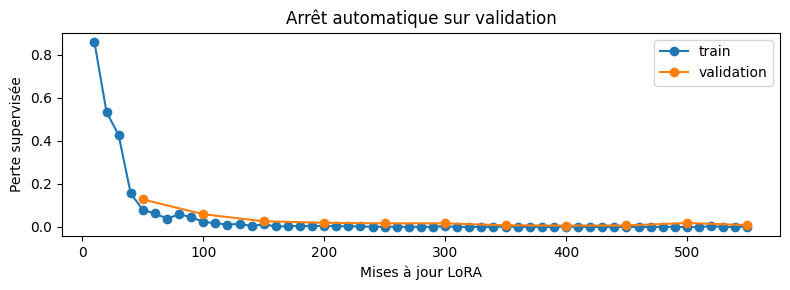

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


after_validation 10 / 40
after_validation 20 / 40
after_validation 30 / 40
after_validation 40 / 40
after_validation {'contract_valid': 1.0, 'action_acc': 0.925, 'reuse_acc': 1.0, 'quotes_ok': 1.0, 'facet_f1_strict': 0.9583333333333334, 'facet_f1_structure': 0.9583333333333334, 'exact_structure': 0.925}
test_report 10 / 80
test_report 20 / 80
test_report 30 / 80
test_report 40 / 80
test_report 50 / 80
test_report 60 / 80
test_report 70 / 80
test_report 80 / 80
test_report {'contract_valid': 1.0, 'action_acc': 0.75, 'reuse_acc': 0.975, 'quotes_ok': 0.975, 'facet_f1_strict': 0.9229166666666668, 'facet_f1_structure': 0.95625, 'exact_structure': 0.7125}
chat_regressions 10 / 10
chat_regressions {'contract_valid': 1.0, 'action_acc': 1.0, 'reuse_acc': 0.9, 'quotes_ok': 1.0, 'facet_f1_strict': 0.27999999999999997, 'facet_f1_structure': 0.86, 'exact_structure': 0.6}


,phase,contract_valid,action_acc,reuse_acc,quotes_ok,facet_f1_strict,facet_f1_structure,exact_structure
0,before_validation,0.0,0.000,0.000,0.000,0.000000,0.000000,0.0000
1,after_validation,1.0,0.925,1.000,1.000,0.958333,0.958333,0.9250
2,heldout_test,1.0,0.750,0.975,0.975,0.922917,0.956250,0.7125


Adaptateur exportable : /kaggle/working/bo5_parser_runs/2ee442336b8e5a84/parser_for_local.zip
Promotion automatique selon VALIDATION : {'passed': True, 'checks': {'contract_at_least_95_percent': True, 'strict_facet_f1_improvement': True, 'action_not_worse': True, 'structure_not_worse': True}, 'selection_split': 'validation', 'thresholds_are': 'declared engineering choices, not statistical proof', 'human_validation': False}
Le test est majoritairement synthétique. Vérifier les demandes réelles avant de conclure.
Le parseur entraîné sera chargé pour le chat à la section suivante.


In [9]:
# Une seule voie : entraînement Kaggle / reprise complète / réutilisation du résultat.
TRAIN_PARSER = os.environ.get('DRESSME_TRAIN_PARSER','1' if ON_KAGGLE else '0')=='1'
ALLOW_LOCAL_TRAINING = False  # l'utilisateur veut entraîner sur Kaggle seulement
PARSER_TRAIN_REPORT={'executed':False,'reason':'training_disabled'}
PARSER_PROMOTED=False
PARSER_SELECTED_DIR=None

def complete_parser_checkpoint(folder,identity):
    folder=Path(folder)
    metadata=load_json(folder/'parser_state.json',{})
    required=['adapter_config.json','adapter_model.safetensors','trainer_state.json','optimizer.pt','scheduler.pt']
    return (metadata.get('run_identity')==identity and all((folder/name).is_file() for name in required)
            and bool(list(folder.glob('rng_state*.pth'))))

def atomic_parser_zip(destination,entries):
    import zipfile
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    temporary=destination.with_suffix('.tmp.zip')
    with zipfile.ZipFile(temporary,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=1) as archive:
        for folder,prefix in entries:
            for path in Path(folder).rglob('*'):
                if path.is_file() and path!=destination and path!=temporary and not path.name.endswith('.zip'):
                    archive.write(path,str(Path(prefix)/path.relative_to(folder)))
    temporary.replace(destination)
    return destination

def finish_parser_evaluation(model,tokenizer,run,selected):
    """Reprendre les évaluations sans réentraîner si la session s'interrompt après Trainer."""
    run,selected=Path(run),Path(selected)
    baseline=load_json(run/'baseline_validation.json',{})
    if not baseline:raise ValueError('Baseline de validation absente ; comparaison non reproductible.')
    receipt=load_json(selected/'training_receipt.json',{})
    evaluation=parser_eval_subset(PARSER_SPLITS['validation'],min(int(os.environ.get('DRESSME_PARSER_EVAL_N','40')),len(PARSER_SPLITS['validation'])),17)
    test_n=min(int(os.environ.get('DRESSME_PARSER_TEST_N','80')),len(PARSER_SPLITS['test']))
    if not evaluation or test_n<1:raise ValueError('Les évaluations doivent être non vides.')
    tested=parser_eval_subset(PARSER_SPLITS['test'],test_n,29)
    reports={}
    for name,examples in [('after_validation',evaluation),('test_report',tested),('chat_regressions',PARSER_CHAT_REGRESSIONS)]:
        identity=digest({'adapter':receipt['adapter_file_sha256'],'examples':examples,'prompt':PARSER_TASK_PROMPT})
        path=run/(name+'.json');report=load_json(path,{})
        if report.get('evaluation_identity')!=identity:
            report=evaluate_parser_generation(model,tokenizer,examples,name)
            report['evaluation_identity']=identity;write_json_atomic(path,report)
        reports[name]=report
    gate=validation_gate(baseline,reports['after_validation'])
    write_json_atomic(run/'validation_gate.json',gate)
    table=pd.DataFrame([{'phase':'before_validation',**baseline['summary']},
                        {'phase':'after_validation',**reports['after_validation']['summary']},
                        {'phase':'heldout_test',**reports['test_report']['summary']}])
    display(table);table.to_csv(run/'parser_benchmark.csv',index=False)
    export_reports=run/'export_reports';export_reports.mkdir(exist_ok=True)
    for name in ['run_config.json','baseline_validation.json','after_validation.json','test_report.json',
                 'chat_regressions.json','validation_gate.json','parser_benchmark.csv','training_history.csv','learning_curve.png']:
        if (run/name).is_file():shutil.copy2(run/name,export_reports/name)
    atomic_parser_zip(run/'parser_for_local.zip',[(selected,'parser_adapter'),(PARSER_DATA_DIR,'data'),(export_reports,'reports')])
    print('Adaptateur exportable :',run/'parser_for_local.zip')
    print('Promotion automatique selon VALIDATION :',gate)
    print('Le test est majoritairement synthétique. Vérifier les demandes réelles avant de conclure.')
    return gate

def run_parser_training():
    if not ON_KAGGLE and not ALLOW_LOCAL_TRAINING:
        raise RuntimeError('Entraînement réservé à Kaggle. En local, laisser DRESSME_TRAIN_PARSER=0.')
    import gc
    import torch
    from transformers import (AutoTokenizer,AutoModelForCausalLM,BitsAndBytesConfig,
        Trainer,TrainingArguments,EarlyStoppingCallback,TrainerCallback,set_seed)
    from peft import LoraConfig,get_peft_model,prepare_model_for_kbit_training,PeftModel
    from huggingface_hub import HfApi
    if int(os.environ.get('DRESSME_PARSER_EVAL_N','40'))<1 or int(os.environ.get('DRESSME_PARSER_TEST_N','80'))<1:
        raise ValueError('Les sous-ensembles de génération doivent contenir au moins un exemple.')
    if not torch.cuda.is_available():raise RuntimeError('Activer le GPU T4 Kaggle avant cette section.')
    if torch.cuda.device_count()!=1:
        raise RuntimeError('Une seule T4 doit être visible pour QLoRA. Exécuter la configuration GPU dans un kernel propre avant les imports Torch.')
    gpu=os.environ.get('DRESSME_TRAIN_DEVICE','cuda:0')
    index=int(gpu.split(':')[-1])
    if 'T4' not in torch.cuda.get_device_name(index):
        raise RuntimeError('Ce protocole est configuré pour une T4. Vérifier le GPU sélectionné.')
    if os.environ.get('CUDA_LAUNCH_BLOCKING','0')!='0':
        raise RuntimeError('CUDA_LAUNCH_BLOCKING doit valoir 0 avant les imports GPU. Redémarrer le kernel après correction.')
    # Une erreur CUDA antérieure reste bloquante. empty_cache ne la répare pas.
    torch.cuda.synchronize(index)
    base=PARSER_BASE_MODEL
    lock=CACHE_DIR/'parser_base_revision_v2.json';saved=load_json(lock,{})
    revision=saved.get('revision') if saved.get('model')==base else None
    revision=revision or HfApi().model_info(base).sha
    write_json_atomic(lock,{'model':base,'revision':revision})
    config={'base':base,'revision':revision,'data_identity':PARSER_DATA_ID,'seed':42,
        'precision':'NF4 double quant + FP16 compute; LoRA FP32','attention':'sdpa',
        'rank':16,'alpha':32,'dropout':.05,'learning_rate':1e-4,'optimizer':'adamw_torch',
        'max_length':2048,'batch_size':1,'gradient_accumulation_steps':8,
        'epochs':float(os.environ.get('DRESSME_LORA_EPOCHS','6')),
        'eval_steps':int(os.environ.get('DRESSME_LORA_EVAL_STEPS','50')),
        'patience':int(os.environ.get('DRESSME_LORA_PATIENCE','3')),
        'min_delta':float(os.environ.get('DRESSME_LORA_MIN_DELTA','0.001')),
        'prompt':PARSER_TASK_PROMPT,'method':'response-only-qlora-early-stopping-v2'}
    if config['epochs']<=0 or config['eval_steps']<1 or config['patience']<1 or config['min_delta']<0:
        raise ValueError('Configuration early stopping invalide.')
    config['requested_eval_steps']=config['eval_steps']
    config['eval_steps']=min(config['eval_steps'],max(1,math.ceil(len(PARSER_SPLITS['train'])/config['gradient_accumulation_steps'])))
    identity=digest(config);run=WORK_DIR/'bo5_parser_runs'/identity[:16]
    run.mkdir(parents=True,exist_ok=True)
    write_json_atomic(run/'run_config.json',config)
    selected=run/'adapter_best'
    receipt=load_json(selected/'training_receipt.json',{})
    complete=(receipt.get('run_identity')==identity and receipt.get('training_complete') is True
              and (selected/'adapter_model.safetensors').is_file()
              and receipt.get('adapter_file_sha256')==file_sha256(selected/'adapter_model.safetensors'))
    if complete:
        print('Entraînement déjà terminé : adaptateur retenu réutilisé, aucune nouvelle mise à jour.')
        if not all((run/name).is_file() for name in ['after_validation.json','test_report.json','chat_regressions.json','validation_gate.json','parser_for_local.zip']):
            # La reprise de l'évaluation charge seulement l'adaptateur déjà entraîné.
            original_dir,original_backend=globals()['PARSER_ADAPTER_DIR'],globals()['PARSER_BACKEND']
            try:
                globals()['PARSER_ADAPTER_DIR']=str(selected);globals()['PARSER_BACKEND']='hf_lora'
                evaluator=HFParser().load()
                finish_parser_evaluation(evaluator.model,evaluator.tokenizer,run,selected)
            finally:
                globals()['PARSER_ADAPTER_DIR']=original_dir;globals()['PARSER_BACKEND']=original_backend
        return {'executed':False,'reason':'completed_run_reused','run':str(run),'adapter':str(selected),
                'promoted':load_json(run/'validation_gate.json',{}).get('passed',False),'receipt':receipt}
    # Ne pas garder Ollama sur la même carte pendant l'apprentissage.
    try:
        ready=requests.get(OLLAMA_BASE_URL+'/api/tags',timeout=2)
        if ready.ok:
            unload=requests.post(OLLAMA_BASE_URL+'/api/generate',json={'model':OLLAMA_MODEL,'keep_alive':0},timeout=30)
            unload.raise_for_status()
    except requests.ConnectionError:
        pass  # un serveur absent n'utilise pas de mémoire GPU
    checkpoints=run/'checkpoints';checkpoints.mkdir(exist_ok=True)
    resume_root=Path(os.environ.get('DRESSME_PARSER_RESUME_DIR',str(checkpoints)))
    if os.environ.get('DRESSME_PARSER_RESUME_DIR') and not resume_root.is_dir():
        raise FileNotFoundError('Dossier de reprise demandé absent : '+str(resume_root))
    candidates=[p for p in resume_root.rglob('checkpoint-*') if p.is_dir() and complete_parser_checkpoint(p,identity)]
    if complete_parser_checkpoint(resume_root,identity):candidates.append(resume_root)
    resume=max(candidates,key=lambda p:int(load_json(p/'trainer_state.json',{}).get('global_step',0))) if candidates else None
    if resume is None and (os.environ.get('DRESSME_PARSER_RESUME_DIR') or list(checkpoints.glob('checkpoint-*'))):
        raise RuntimeError('Aucun checkpoint COMPLET compatible dans le dossier demandé. Vérifier identité des données, optimiseur, scheduler et RNG ; aucun redémarrage à zéro silencieux.')
    if resume and resume.parent.resolve()!=checkpoints.resolve():
        # Les Input Kaggle sont en lecture seule et les chemins d'une ancienne session ne sont pas portables.
        for candidate in candidates:
            destination=checkpoints/candidate.name
            if candidate.resolve()!=destination.resolve():shutil.copytree(candidate,destination,dirs_exist_ok=True)
        resume=checkpoints/resume.name
    if resume:
        state_path=resume/'trainer_state.json';state=load_json(state_path,{})
        best=state.get('best_model_checkpoint')
        if best:
            rebased=checkpoints/Path(best).name
            if not rebased.is_dir():raise RuntimeError('Le meilleur checkpoint manque dans la sauvegarde. Importer le ZIP complet avec meilleur et dernier checkpoints.')
            state['best_model_checkpoint']=str(rebased);write_json_atomic(state_path,state)
    set_seed(42)
    existing=globals().get('parser_model')
    if existing is not None:
        if getattr(existing,'_bo5_training_identity',None)!=identity or globals().get('parser_tokenizer') is None:
            raise RuntimeError('Un autre modèle HF est chargé ; aucun second Qwen chargé. Conserver ses sorties avant de reprendre dans un kernel propre.')
        if not resume:raise RuntimeError('Tentative précédente en mémoire sans checkpoint complet. Redémarrer le kernel pour repartir de la même initialisation.')
        model,tokenizer=existing,globals()['parser_tokenizer']
        print('Modèle compatible en mémoire réutilisé ; l’état complet du checkpoint sera restauré.')
    else:
        from huggingface_hub import try_to_load_from_cache
        files=HfApi().model_info(base,revision=revision,files_metadata=True).siblings
        remaining=0
        for entry in files:
            if entry.rfilename.endswith('.safetensors') and '/' not in entry.rfilename:
                cached=try_to_load_from_cache(base,entry.rfilename,revision=revision,cache_dir=str(CACHE_DIR/'models'))
                if not isinstance(cached,str):remaining+=int(entry.size or 0)
        if shutil.disk_usage(WORK_DIR).free<remaining+1024**3:
            raise RuntimeError(f'Espace insuffisant : environ {remaining/1024**3:.1f} Gio de poids restent à télécharger, plus 1 Gio de marge.')
        tokenizer=AutoTokenizer.from_pretrained(base,revision=revision,cache_dir=str(CACHE_DIR/'models'))
        if tokenizer.pad_token_id is None:tokenizer.pad_token=tokenizer.eos_token
        tokenizer.padding_side='right'
        quantization=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.float16)
        model=AutoModelForCausalLM.from_pretrained(base,revision=revision,quantization_config=quantization,
            dtype=torch.float16,device_map={'':gpu},attn_implementation='sdpa',use_safetensors=True,
            cache_dir=str(CACHE_DIR/'models'))
        model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=True,gradient_checkpointing_kwargs={'use_reentrant':False})
        if resume:
            model=PeftModel.from_pretrained(model,str(resume),is_trainable=True)
        else:
            model=get_peft_model(model,LoraConfig(r=config['rank'],lora_alpha=config['alpha'],lora_dropout=config['dropout'],
                 bias='none',task_type='CAUSAL_LM',target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj']))
    model._bo5_training_identity=identity
    model.config.pad_token_id=tokenizer.pad_token_id
    model.generation_config.pad_token_id=tokenizer.pad_token_id
    model.config.use_cache=False
    model.print_trainable_parameters()
    if shutil.disk_usage(WORK_DIR).free<1024**3:
        raise RuntimeError('Moins de 1 Gio libre pour checkpoints et sauvegardes ; conserver les fichiers avant de libérer de l’espace.')
    trainable=[name for name,p in model.named_parameters() if p.requires_grad]
    if not trainable or any('lora_' not in name for name in trainable):
        raise RuntimeError('Ce protocole doit entraîner uniquement les paramètres LoRA.')
    globals()['parser_model']=model;globals()['parser_tokenizer']=tokenizer
    class Examples(torch.utils.data.Dataset):
        def __init__(self,examples):
            self.rows=[]
            vocabulary=model.get_input_embeddings().num_embeddings
            for example in examples:
                plan=validate_parser_example(example)
                prefix=tokenizer.apply_chat_template(parser_messages(example['input']),tokenize=False,add_generation_prompt=True,enable_thinking=False)
                first=tokenizer(prefix,add_special_tokens=False)['input_ids']
                last=tokenizer(json.dumps(plan.model_dump(),ensure_ascii=False,separators=(',',':'))+tokenizer.eos_token,add_special_tokens=False)['input_ids']
                ids=first+last
                if len(ids)>config['max_length'] or not last:raise ValueError('Exemple trop long ou cible vide ; aucun JSON tronqué.')
                if min(ids)<0 or max(ids)>=vocabulary:raise ValueError('Token hors vocabulaire.')
                self.rows.append({'input_ids':ids,'attention_mask':[1]*len(ids),'labels':[-100]*len(first)+last})
        def __len__(self):return len(self.rows)
        def __getitem__(self,index):return self.rows[index]
    def collate(rows):
        length=((max(len(row['input_ids']) for row in rows)+7)//8)*8
        return {field:torch.tensor([row[field]+[fill]*(length-len(row[field])) for row in rows],dtype=torch.long)
                for field,fill in [('input_ids',tokenizer.pad_token_id),('attention_mask',0),('labels',-100)]}
    training=Examples(PARSER_SPLITS['train']);validation=Examples(PARSER_SPLITS['validation'])
    # Baseline de génération sur VALIDATION uniquement. Un score nul ne bloque pas l'entraînement.
    evaluation=parser_eval_subset(PARSER_SPLITS['validation'],min(int(os.environ.get('DRESSME_PARSER_EVAL_N','40')),len(PARSER_SPLITS['validation'])),17)
    baseline_path=run/'baseline_validation.json'
    baseline=load_json(baseline_path,{})
    evaluation_identity=digest({'run':identity,'examples':evaluation,'scope':'adapter disabled'})
    if baseline.get('evaluation_identity')!=evaluation_identity:
        with model.disable_adapter():baseline=evaluate_parser_generation(model,tokenizer,evaluation,'AVANT — validation')
        baseline['evaluation_identity']=evaluation_identity;write_json_atomic(baseline_path,baseline)
    # Vérification numérique courte avant la longue boucle.
    batch={key:value.to(gpu) for key,value in collate([training[0]]).items()}
    model.train();model.zero_grad(set_to_none=True);start=time.perf_counter()
    with torch.autocast('cuda',dtype=torch.float16):loss=model(**batch).loss
    if not torch.isfinite(loss):raise RuntimeError('Perte non finie avant entraînement.')
    loss.backward();torch.cuda.synchronize(index)
    gradients=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
    if not gradients or not all(torch.isfinite(g).all().item() for g in gradients):raise RuntimeError('Gradients LoRA non finis ou absents.')
    print('Contrôle forward/backward :',round(time.perf_counter()-start,2),'s ; aucune mise à jour effectuée.')
    model.zero_grad(set_to_none=True);del batch,loss,gradients;gc.collect();torch.cuda.empty_cache()
    class PortableCheckpoint(TrainerCallback):
        def on_save(self,args,state,control,**kwargs):
            folder=Path(args.output_dir)/f'checkpoint-{state.global_step}'
            meta={'run_identity':identity,'data_identity':PARSER_DATA_ID,'base_model':base,'base_revision':revision,
                  'global_steps':state.global_step,'training_complete':False,'training_config':config}
            write_json_atomic(folder/'parser_state.json',meta)
            if complete_parser_checkpoint(folder,identity):
                entries=[(folder,folder.name),(PARSER_DATA_DIR,'data')]
                best=Path(state.best_model_checkpoint) if state.best_model_checkpoint else None
                if best and best.is_dir() and best.resolve()!=folder.resolve():entries.append((best,best.name))
                atomic_parser_zip(run/'resume_latest.zip',entries)
            print('Checkpoint et ZIP de reprise :',folder)
    args=TrainingArguments(output_dir=str(checkpoints),per_device_train_batch_size=1,per_device_eval_batch_size=1,
        gradient_accumulation_steps=config['gradient_accumulation_steps'],num_train_epochs=config['epochs'],
        learning_rate=config['learning_rate'],lr_scheduler_type='cosine',warmup_ratio=.05,weight_decay=.01,
        fp16=True,bf16=False,optim='adamw_torch',gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant':False},logging_steps=10,
        eval_strategy='steps',eval_steps=config['eval_steps'],save_strategy='steps',save_steps=config['eval_steps'],
        save_total_limit=2,load_best_model_at_end=True,metric_for_best_model='eval_loss',greater_is_better=False,
        restore_callback_states_from_checkpoint=True,eval_accumulation_steps=1,prediction_loss_only=True,
        group_by_length=True,report_to='none',seed=42,data_seed=42,dataloader_num_workers=0,
        remove_unused_columns=False,label_names=['labels'],dataloader_pin_memory=False)
    trainer=Trainer(model=model,args=args,train_dataset=training,eval_dataset=validation,data_collator=collate,
        processing_class=tokenizer,callbacks=[EarlyStoppingCallback(early_stopping_patience=config['patience'],
        early_stopping_threshold=config['min_delta']),PortableCheckpoint()])
    print('Pas de limite de 20 minutes. Arrêt sur perte de validation ; patience',config['patience'],
          'évaluations ; amélioration minimale',config['min_delta'],'; au plus',config['epochs'],'époques.')
    print('Reprise complète :',str(resume) if resume else 'aucune ; nouvel apprentissage')
    before=lora_fingerprint(model);started=time.perf_counter()
    try:
        stats=trainer.train(resume_from_checkpoint=str(resume) if resume else None)
    except KeyboardInterrupt:
        partial=run/'adapter_interrupted';partial.mkdir(exist_ok=True)
        trainer.save_model(str(partial));tokenizer.save_pretrained(partial)
        write_json_atomic(partial/'parser_state.json',{'run_identity':identity,'base_model':base,'base_revision':revision,
            'global_steps':trainer.state.global_step,'training_complete':False,'training_config':config,
            'note':'adapter only; optimizer state is in the last complete periodic checkpoint'})
        atomic_parser_zip(run/'interrupted_adapter.zip',[(partial,'adapter_interrupted')])
        print('Interruption : adaptateur sauvegardé ; reprendre le dernier checkpoint COMPLET. Aucun résultat final annoncé.')
        raise
    after=lora_fingerprint(model)
    if trainer.state.global_step<1:raise RuntimeError('Aucune mise à jour effectuée.')
    if after==before and not resume:raise RuntimeError('Poids LoRA inchangés malgré un nouvel entraînement.')
    selected.mkdir(exist_ok=True);trainer.save_model(str(selected));tokenizer.save_pretrained(selected)
    model.eval();model.config.use_cache=True
    checkpoint=trainer.state.best_model_checkpoint
    metadata={'run_identity':identity,'data_identity':PARSER_DATA_ID,'base_model':base,'base_revision':revision,
        'global_steps':trainer.state.global_step,'training_complete':True,'training_config':config,
        'selected_adapter_checkpoint':checkpoint,'selection_metric':'validation loss','best_validation_loss':trainer.state.best_metric,
        'adapter_file_sha256':file_sha256(selected/'adapter_model.safetensors'),
        'adapter_hash_after_session':after,'duration_seconds_this_session':time.perf_counter()-started,
        'stop_reason':'early_stopping' if trainer.state.global_step<trainer.state.max_steps else 'maximum_epochs',
        'metrics':stats.metrics,'task':'request -> Turn; does not train retrieval or outfit compatibility'}
    model._bo5_adapter_file_sha256=metadata['adapter_file_sha256']
    write_json_atomic(selected/'training_receipt.json',metadata)
    history=pd.DataFrame(trainer.state.log_history);history.to_csv(run/'training_history.csv',index=False)
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(8,3))
    for field,label in [('loss','train'),('eval_loss','validation')]:
        if field in history:
            part=history.dropna(subset=[field]);ax.plot(part['step'],part[field],marker='o',label=label)
    ax.set(xlabel='Mises à jour LoRA',ylabel='Perte supervisée',title='Arrêt automatique sur validation');ax.legend();fig.tight_layout()
    fig.savefig(run/'learning_curve.png',dpi=150);display(fig);plt.close(fig)
    gate=finish_parser_evaluation(model,tokenizer,run,selected)
    del trainer,training,validation;gc.collect();torch.cuda.empty_cache()
    return {'executed':True,'run':str(run),'adapter':str(selected),'promoted':gate['passed'],'receipt':metadata}

if TRAIN_PARSER:
    PARSER_TRAIN_REPORT=run_parser_training()
    PARSER_PROMOTED=bool(PARSER_TRAIN_REPORT['promoted'])
    PARSER_SELECTED_DIR=PARSER_TRAIN_REPORT['adapter']
    if PARSER_PROMOTED:
        PARSER_ADAPTER_DIR=PARSER_SELECTED_DIR
        PARSER_BACKEND='hf_lora'
        print('Le parseur entraîné sera chargé pour le chat à la section suivante.')
    else:
        PARSER_BACKEND='ollama'
        # Ne pas garder un LoRA refusé sur le GPU pendant l'inférence Ollama.
        globals().pop('parser_model',None);globals().pop('parser_tokenizer',None)
        import gc,torch
        gc.collect();torch.cuda.empty_cache()
        print('Le LoRA reste exporté mais non activé : critères de validation non atteints. Le chat annoncera le modèle Ollama réellement utilisé.')
else:
    print('Entraînement non exécuté. Sur Kaggle : DRESSME_TRAIN_PARSER=1 avant cette section. En local : inférence seulement.')


## 5 — Catalogue et RAG indépendants de BO1

Les fiches produits et les annotations **train uniquement** forment les documents. Une étiquette issue d'une tenue source est un contexte, pas une propriété esthétique certifiée du produit.

BM25 travaille sur les vrais mots. E5 utilise `query:` et `passage:` ; les documents longs sont découpés en passages avec recouvrement. L'identité du cache inclut l'encodeur, sa révision, les IDs et les passages. Une incohérence ou un vecteur nul est refusé. Aucun repli lexical silencieux : `lexical` est un choix explicite de diagnostic.

La recherche se teste avec `search_products_rag()` sans moteur BO1 ni appel à Qwen. Une recherche sémantique seule n'est pas un filtre strict : transmettre un `ComposeSpec` pour contrôler les attributs.


In [10]:
class ProductContext:
    """Training annotation context and co-occurrence statistics. Never returns source outfits."""
    def __init__(self, manifest, annotations):
        self.frame=manifest.copy().reset_index(drop=True)
        self.frame['image_id']=self.frame.image_id.astype(str)
        if self.frame.image_id.duplicated().any(): raise ValueError('Identifiants de produits dupliqués')
        self.ids=self.frame.image_id.tolist(); self.pos={x:i for i,x in enumerate(self.ids)}
        self.products=self.frame.set_index('image_id').to_dict('index')
        self.products={k:{'image_id':k,**v} for k,v in self.products.items()}
        self.labels={k:{f:Counter() for f in ('style','occasion','season')} for k in self.ids}
        self.label_sources=defaultdict(list)
        self.pairs=Counter(); self.frequency=Counter(); self.source_signatures=set(); seen=set(); self.train_records=0
        for oid,record in annotations.items():
            if not isinstance(record,dict) or record.get('section')!='train' or record.get('source')!='mytheresa': continue
            members=record.get('outfit') or {}; info=record.get('outfit_info') or {}
            if not isinstance(members,dict) or not isinstance(info,dict): continue
            signature=tuple(sorted(map(str,members)))
            if signature in seen: continue
            seen.add(signature)
            local=sorted(set(signature).intersection(self.pos))
            if not local: continue
            self.train_records+=1; self.source_signatures.add(tuple(local))
            self.frequency.update(local)
            self.pairs.update(itertools.combinations(local,2))
            for item_id in local:
                for field in ('style','occasion','season'):
                    for label in annotation_labels(info.get(field)):
                        self.labels[item_id][field][label]+=1
                        key=(item_id,field,label)
                        if len(self.label_sources[key])<3: self.label_sources[key].append(str(oid))
        self.texts=[]; self.context_texts=[]
        for item_id in self.ids:
            p=self.products[item_id]
            context='. '.join(f"associated {f}: {', '.join(k for k,_ in self.labels[item_id][f].most_common(6))}"
                             for f in ('style','occasion','season'))
            self.context_texts.append(context)
            self.texts.append('. '.join(f'{f}: {p.get(f, "")}' for f in
                              ('gender','type','name','color','description')) + '. '+context)
        self.vocabulary={f:sorted(set(str(p.get(f) or '') for p in self.products.values())-{''})
                         for f in ('gender','color','type')}
        for f in ('style','occasion','season'):
            self.vocabulary[f]=sorted(set(k for v in self.labels.values() for k in v[f]))

    def association(self, ids):
        details=[]
        for a,b in itertools.combinations(sorted(ids),2):
            count=self.pairs[(a,b)]; fa=self.frequency[a]; fb=self.frequency[b]
            # Cosine of the binary outfit-incidence columns: bounded, support is explicit.
            value=count/math.sqrt(fa*fb) if fa and fb else None
            details.append({'a':a,'b':b,'train_cooccurrences':count,
                            'frequency_a':fa,'frequency_b':fb,'association':value})
        known=[x['association'] for x in details if x['association'] is not None]
        return (float(sum(known)/len(details)) if known else None),details

    def evidence(self, item_id):
        p=self.products[item_id]
        result={f:p.get(f,'') for f in ('name','type','color','gender','description','role')}
        for field in ('style','occasion','season'):
            result['associated_'+field]=[{'label':label,'train_support':count,
                'source_annotation_ids':self.label_sources[(item_id,field,label)]}
                for label,count in self.labels[item_id][field].most_common(4)]
        return result


In [11]:
class ProductRAG:
    """BM25 + E5 gelé. Les contraintes sont appliquées par BO5, pas inférées ici."""
    def __init__(self, catalog, mode='hybrid', encoder=None):
        if mode not in {'hybrid','lexical'}:
            raise ValueError('Mode RAG : hybrid ou lexical.')
        self.catalog, self.mode = catalog, mode
        self.ids = list(catalog.ids)
        self.encoder = encoder
        self.query_cache = {}
        self.taxonomy_vectors = None
        self.vectors = None
        self.passage_vectors = None
        self.identity = 'bm25-words-v2'
        self.docs = [Counter(tokens(text)) for text in catalog.texts]
        self.length = np.asarray([sum(doc.values()) for doc in self.docs], dtype=float)
        self.average = max(float(self.length.mean()), 1.) if len(self.length) else 1.
        df = Counter(word for doc in self.docs for word in doc)
        self.idf = {word:math.log(1+(len(self.docs)-count+.5)/(count+.5)) for word,count in df.items()}
        self.taxonomy = [{'field':field,'value':value} for field,values in catalog.vocabulary.items() for value in values]
        self.passages, self.passage_positions = [], []
        if not self.ids:
            return
        if not any(self.docs):
            raise ValueError('Index lexical vide : vérifier la tokenisation et les documents.')
        if mode == 'hybrid':
            if encoder is None:
                from sentence_transformers import SentenceTransformer
                from huggingface_hub import HfApi
                model = 'intfloat/multilingual-e5-small'
                lock = CACHE_DIR/'bo5_e5_revision.json'
                record = load_json(lock,{})
                revision = record.get('revision') if record.get('model') == model else None
                revision = revision or HfApi().model_info(model).sha
                write_json_atomic(lock,{'model':model,'revision':revision})
                encoder = SentenceTransformer(model,revision=revision,device='cpu',cache_folder=str(CACHE_DIR/'models'))
                encoder.max_seq_length = 512
                self.identity = f'{model}@{revision}:512:passages-v2'
            else:
                # Un encodeur externe doit fournir une identité versionnée pour le cache.
                self.identity = getattr(encoder,'bo5_identity',None)
                if not self.identity:
                    raise ValueError('Encodeur externe : bo5_identity versionné requis.')
            self.encoder = encoder
            for position,text in enumerate(catalog.texts):
                parts = self._pieces(text, 360, 48)
                for part in parts:
                    self.passages.append('passage: '+part)
                    self.passage_positions.append(position)
            cache = CACHE_DIR/'bo5_product_passages_v2.npz'
            identity = digest({'encoder':self.identity,'ids':self.ids,'passages':self.passages})
            if cache.is_file():
                with np.load(cache,allow_pickle=False) as stored:
                    if stored['identity'].item() == identity:
                        self.passage_vectors = stored['vectors']
            if self.passage_vectors is None:
                self.passage_vectors = self._encode(self.passages)
                temporary = cache.with_suffix('.tmp.npz')
                np.savez_compressed(temporary,identity=np.asarray(identity),vectors=self.passage_vectors)
                temporary.replace(cache)
            self._check(self.passage_vectors,len(self.passages))
            # Vecteur produit pour l'affinité de préférence, distinct du max de passages pour la recherche.
            self.vectors = np.stack([self.passage_vectors[np.asarray(self.passage_positions)==i].mean(axis=0)
                                     for i in range(len(self.ids))])
            self.vectors /= np.maximum(np.linalg.norm(self.vectors,axis=1,keepdims=True),1e-12)

    def _pieces(self,text,size,overlap=0):
        tokenizer = getattr(self.encoder,'tokenizer',None)
        if tokenizer is not None:
            ids = tokenizer.encode(str(text),add_special_tokens=False)
            return [tokenizer.decode(ids[i:i+size],skip_special_tokens=True)
                    for i in range(0,max(1,len(ids)),size-overlap)]
        words = str(text).split()
        return [' '.join(words[i:i+size]) for i in range(0,max(1,len(words)),size-overlap)]

    @staticmethod
    def _check(vectors,count):
        if vectors.ndim != 2 or len(vectors) != count or not np.isfinite(vectors).all():
            raise ValueError('Vecteurs E5 invalides ou mal alignés.')
        if count and np.any(np.linalg.norm(vectors,axis=1)<1e-8):
            raise ValueError('Vecteur E5 nul.')

    def _encode(self,texts):
        vectors = np.asarray(self.encoder.encode(texts,normalize_embeddings=True,convert_to_numpy=True,
                             batch_size=24,show_progress_bar=False),dtype=np.float32)
        self._check(vectors,len(texts))
        return vectors

    def encode_query(self,query):
        if self.encoder is None:
            raise BackendUnavailable('Affinité sémantique indisponible en mode lexical.')
        if query not in self.query_cache:
            vectors = self._encode(['query: '+piece for piece in self._pieces(query,400)])
            vector = vectors.mean(axis=0)
            self.query_cache[query] = vector/max(float(np.linalg.norm(vector)),1e-12)
        return self.query_cache[query]

    def hints(self,query,k=16):
        if not self.taxonomy:
            return []
        if self.mode == 'hybrid':
            if self.taxonomy_vectors is None:
                self.taxonomy_vectors = self._encode(['passage: '+x['field']+': '+x['value'] for x in self.taxonomy])
            scores = self.taxonomy_vectors@self.encode_query(query)
        else:
            words = set(tokens(query))
            scores = np.asarray([len(words&set(tokens(x['value']))) for x in self.taxonomy])
        order = sorted(range(len(scores)),key=lambda i:(-float(scores[i]),self.taxonomy[i]['value']))[:k]
        return [{**self.taxonomy[i],'similarity':float(scores[i])} for i in order]

    def score(self,query):
        if not self.ids:
            return {}
        lexical = np.zeros(len(self.ids),dtype=float)
        for word in set(tokens(query)):
            counts = np.asarray([doc.get(word,0) for doc in self.docs],dtype=float)
            lexical += self.idf.get(word,0)*counts*2.5/(counts+1.5*(.25+.75*self.length/self.average))
        lex = lexical/max(float(lexical.max()),1e-12)
        dense = None
        if self.mode == 'hybrid':
            scores = self.passage_vectors@self.encode_query(query)
            dense = np.asarray([scores[np.asarray(self.passage_positions)==i].max() for i in range(len(self.ids))])
        relevance = .85*np.clip((dense+1)/2,0,1)+.15*lex if dense is not None else lex
        return {key:{'relevance':float(relevance[i]),'dense_cosine':float(dense[i]) if dense is not None else None,
                     'bm25':float(lexical[i]),'retrieval_mode':self.mode,'encoder_identity':self.identity}
                for i,key in enumerate(self.ids)}


def search_products_rag(query,top_n=5,spec=None,user_id=ACTIVE_USER):
    if rag is None:
        raise RuntimeError('Le RAG n’est pas chargé : '+RAG_ERROR)
    if not isinstance(query,str) or not query.strip():
        raise ValueError('Requête non vide requise.')
    if not 1<=top_n<=100:
        raise ValueError('top_n doit être entre 1 et 100.')
    signals = rag.score(query)
    rows = []
    profile = Profiles(STATE_DIR).get(user_id)
    for key,item in catalog.products.items():
        if not Path(item['image_path']).is_file():
            continue
        if spec:
            if spec.scope == 'wardrobe' and key not in profile['wardrobe_ids']:
                continue
            if not all(report['passed'] for report in reports_for_items([item],spec.facets)):
                continue
        rows.append({**item,**signals[key],'evidence':catalog.evidence(key)})
    rows.sort(key=lambda row:(-row['relevance'],row['image_id']))
    return pd.DataFrame(rows[:top_n])


In [12]:
manifest_mt, context_annotations, personal_ids, DATA_REPORT = load_catalog_inputs()
catalog = ProductContext(manifest_mt, context_annotations)
rag = None
RAG_ERROR = ''
try:
    rag = ProductRAG(catalog, RAG_MODE)
except (ImportError, OSError, RuntimeError, ValueError) as exc:
    RAG_ERROR = f'{type(exc).__name__}: {exc}'
print(json.dumps(DATA_REPORT,ensure_ascii=False,indent=2))
print('RAG :', RAG_MODE, '| documents :',len(catalog.ids),'| erreur :',RAG_ERROR or 'aucune')
if len(manifest_mt):
    display(pd.crosstab(manifest_mt.gender,manifest_mt.role))
    display(manifest_mt.groupby('type').size().sort_values(ascending=False).rename('nombre').to_frame().head(30))
else:
    print('Configurer les fichiers de données avant une recommandation. Les tests mécaniques utilisent leur propre fixture séparée.')


{
  "source": "not_configured",
  "products": 0,
  "missing_images": [],
  "unknown_roles": 0,
  "personal_products": 0,
  "automatic_downloads": false
}
RAG : hybrid | documents : 0 | erreur : aucune
Configurer les fichiers de données avant une recommandation. Les tests mécaniques utilisent leur propre fixture séparée.


## 6 — Contrats des autres BO

BO1 fournit `health`, `propose`, `score`, comme détaillé ci-dessous. Pour les autres BO, enregistrer un adaptateur dans `external_bos` avec ses vraies opérations. Le registre ne devine ni API ni format de réponse. Il rend les appels explicites et traçables ; l'ajout d'une nouvelle intention au chat demandera son contrat et sa validation propres.


### Contrat BO1

**Mode conseillé : `module`.** Un module local doit exposer `create_backend(config)` qui renvoie un objet avec :

```python
health() -> {"ready": bool, "can_propose": bool, "can_score": bool,
             "model_id": str, "max_items": 5}
propose(request) -> [{"item_ids": ["ID1", "ID2", "ID3"], "proposal_id": "..."}]
score(outfits) -> [{"item_ids": [...], "raw_score": nombre,
                   "scale_min": 0, "scale_max": 10, "model_id": "...", "details": {}}]
```

`request` contient la requête, le plan, les pièces fixes, les pools par rôle et les fiches produits autorisées. La complétion doit retourner une **tenue entière**, pièces fixes comprises. L'adaptateur convertit les indices MiniGPT/RQ-VAE vers les vrais IDs MyTheresa ; il doit refuser une correspondance inconnue. Les scores doivent être retournés exactement une fois par combinaison, avec la même échelle et le même modèle dans un classement.

Le mode `http` définit les routes `/health`, `/propose` et `/score` **à implémenter dans ton backend local**. Le mode `scorer_only` sait réellement charger `dressme_core.py`, `scorer.pt` et `emb_ft.npy` de l'export BO1 fourni : il score les IDs connus, mais ne complète pas les tenues. Il n'encode pas de nouvelles photos et ne prétend pas corriger le défaut de parité des miniatures signalé dans BO1.

Pour les vêtements personnels absents du catalogue BO1, l'adaptateur doit gérer leur encodage et leur utilisation, ou annoncer qu'il ne les supporte pas. Le notebook ne fabrique aucun vecteur ni résultat à leur place.


In [13]:
import importlib.util
import math
from typing import Protocol


class BackendUnavailable(RuntimeError):
    pass


class BO1Proposal(StrictModel):
    item_ids: list[str] = Field(min_length=2, max_length=5)
    proposal_id: str = ''


class BO1Score(StrictModel):
    item_ids: list[str] = Field(min_length=2, max_length=5)
    raw_score: float
    scale_min: float
    scale_max: float
    model_id: str = Field(min_length=1)
    details: dict = Field(default_factory=dict)

    def normalized(self):
        values = (self.raw_score,self.scale_min,self.scale_max)
        if not all(math.isfinite(x) for x in values) or self.scale_max <= self.scale_min:
            raise ValueError('Échelle de score BO1 non valide.')
        if not self.scale_min <= self.raw_score <= self.scale_max:
            raise ValueError('Score BO1 hors de l’échelle déclarée.')
        if len(set(self.item_ids)) != len(self.item_ids):
            raise ValueError('Score BO1 associé à des articles dupliqués.')
        return (self.raw_score-self.scale_min)/(self.scale_max-self.scale_min)


class BO1Contract(Protocol):
    # Contrat NOUVEAU à adapter localement aux deux notebooks BO1 existants.
    def health(self) -> dict: ...
    def propose(self, request: dict) -> list[dict]: ...
    def score(self, outfits: list[list[str]]) -> list[dict]: ...


class UnavailableBO1:
    def __init__(self, reason): self.reason=reason
    def health(self):
        return {'ready':False,'can_propose':False,'can_score':False,'reason':self.reason,'model_id':None,'max_items':5}
    def propose(self,request): raise BackendUnavailable(self.reason)
    def score(self,outfits): raise BackendUnavailable(self.reason)


class ModuleBO1:
    def __init__(self,path):
        spec=importlib.util.spec_from_file_location('dressme_local_bo1_adapter',path)
        if spec is None or spec.loader is None: raise ValueError('Module BO1 illisible.')
        import sys
        module=importlib.util.module_from_spec(spec);sys.modules[spec.name]=module;spec.loader.exec_module(module)
        if not callable(getattr(module,'create_backend',None)):
            raise ValueError('Le module local doit fournir create_backend(config). Voir le contrat dans ce notebook.')
        self.backend=module.create_backend({'export_dir':str(BO1_EXPORT_DIR),'device':os.environ.get('DRESSME_BO1_DEVICE','cpu')})
        if not all(callable(getattr(self.backend,name,None)) for name in ('health','propose','score')):
            raise ValueError('Backend BO1 : méthodes health, propose et score requises.')
    def health(self): return self.backend.health()
    def propose(self,request): return self.backend.propose(request)
    def score(self,outfits): return self.backend.score(outfits)


class HTTPBO1:
    # Ces routes définissent le contrat à implémenter ; elles ne sont pas
    # prétendues présentes dans les notebooks BO1 fournis.
    def __init__(self,url): self.url=url
    def health(self):
        response=requests.get(self.url+'/health',timeout=5);response.raise_for_status();return response.json()
    def propose(self,request):
        response=requests.post(self.url+'/propose',json=request,timeout=180)
        response.raise_for_status();return response.json()['proposals']
    def score(self,outfits):
        response=requests.post(self.url+'/score',json={'outfits':outfits},timeout=180)
        response.raise_for_status();return response.json()['scores']


class ExportedBO1Scorer:
    """Vrai scoreur du BO1 fourni, pour les IDs dont emb_ft.npy est disponible.

    Le Transformer est rechargé avec visual=None, car les vecteurs sont déjà
    calculés. Aucun nouvel encodage de photo n'est réalisé. Le défaut de parité
    des miniatures du BO1 reste à résoudre pour les NOUVELLES photos.
    Ce chargeur ne prétend pas fournir la complétion MiniGPT.
    """
    def __init__(self,folder):
        import torch
        self.torch=torch;self.folder=Path(folder)
        config=load_json(self.folder/'config.json',{})
        catalog_data=load_json(self.folder/'catalog.json',{})
        required=['dressme_core.py','scorer.pt','emb_ft.npy','config.json','catalog.json']
        missing=[name for name in required if not (self.folder/name).is_file()]
        if missing: raise FileNotFoundError('Export BO1 incomplet : '+str(missing))
        import sys
        spec=importlib.util.spec_from_file_location('dressme_verified_bo1_core',self.folder/'dressme_core.py')
        if spec is None or spec.loader is None: raise ValueError('dressme_core.py illisible.')
        core=importlib.util.module_from_spec(spec);sys.modules[spec.name]=core;spec.loader.exec_module(core)
        self.model=core.OutfitScorer(None,**config['scorer'])
        self.model.load_state_dict(torch.load(self.folder/'scorer.pt',map_location='cpu',weights_only=True),strict=True)
        self.model.eval();self.core=core
        vectors=np.load(self.folder/'emb_ft.npy',allow_pickle=False)
        ids=list(map(str,catalog_data['codes']))
        if len(ids)!=len(set(ids)) or vectors.shape!=(len(ids),512) or not np.isfinite(vectors).all():
            raise ValueError('BO1 : incohérence entre catalogue et vecteurs.')
        self.positions={key:i for i,key in enumerate(ids)}
        self.vectors=torch.as_tensor(vectors,dtype=torch.float32)
        self.model_id='BO1-OutfitScorer:'+digest({'config':config,'ids':ids,
            'weights_sha256':file_sha256(self.folder/'scorer.pt'),
            'embeddings_sha256':file_sha256(self.folder/'emb_ft.npy')})[:16]
        self.maximum=int(config['K'])
    def health(self):
        return {'ready':True,'can_score':True,'can_propose':False,'max_items':self.maximum,
                'model_id':self.model_id,'supported_ids':list(self.positions),
                'new_photo_embedding_ready':False,'score_target':'synthetic source/corruption score, not human aesthetic rating'}
    def propose(self,request):
        raise BackendUnavailable('Le scoreur BO1 est chargé, mais le moteur de complétion n’est pas encore connecté.')
    def score(self,outfits):
        rows=[]
        for ids in outfits:
            if not 2<=len(ids)<=self.maximum or len(ids)!=len(set(ids)):
                raise ValueError('BO1 : taille ou identifiants de la tenue invalides.')
            missing=set(ids)-set(self.positions)
            if missing: raise BackendUnavailable('Articles sans vecteur BO1 : '+str(sorted(missing)))
            rows.append([self.positions[key] for key in ids])
        with self.torch.inference_mode(): scores=self.core.score_rows(self.model,self.vectors,rows).tolist()
        return [{'item_ids':list(ids),'raw_score':float(score),'scale_min':0.,'scale_max':10.,
                 'model_id':self.model_id,'details':{'input':'exported_image_embeddings','human_rating':False}}
                for ids,score in zip(outfits,scores)]


def connect_bo1():
    try:
        if BO1_MODE=='disabled': return UnavailableBO1('BO1 désactivé explicitement.')
        if BO1_MODE=='module':
            if not BO1_MODULE.is_file(): return UnavailableBO1('Module BO1 local absent : '+str(BO1_MODULE))
            backend=ModuleBO1(BO1_MODULE)
        elif BO1_MODE=='http': backend=HTTPBO1(BO1_BASE_URL)
        elif BO1_MODE=='scorer_only': backend=ExportedBO1Scorer(BO1_EXPORT_DIR)
        else: raise ValueError('DRESSME_BO1_MODE : module, http, scorer_only ou disabled.')
        health=backend.health()
        if not isinstance(health,dict): raise ValueError('health() doit retourner un objet.')
        return backend
    except (OSError,ValueError,ImportError,RuntimeError,requests.RequestException) as exc:
        return UnavailableBO1(f'{type(exc).__name__}: {exc}')


def verified_bo1_scores(backend,outfits):
    raw=backend.score(outfits)
    if not isinstance(raw,list) or len(raw)!=len(outfits): raise ValueError('BO1 n’a pas scoré chaque tenue exactement une fois.')
    scores=[BO1Score.model_validate(x) for x in raw]
    expected=[tuple(sorted(ids)) for ids in outfits]
    observed=[tuple(sorted(x.item_ids)) for x in scores]
    if len(expected)!=len(set(expected)) or sorted(expected)!=sorted(observed):
        raise ValueError('BO1 : score manquant, dupliqué ou associé à une autre tenue.')
    for score in scores: score.normalized()
    if len({(x.scale_min,x.scale_max,x.model_id) for x in scores})>1:
        raise ValueError('Les scores d’un même classement doivent partager modèle et échelle.')
    declared=backend.health().get('model_id')
    if declared and any(x.model_id!=declared for x in scores):
        raise ValueError('Le modèle ayant produit les scores diffère du modèle annoncé par BO1.')
    lookup={tuple(sorted(x.item_ids)):x for x in scores}
    return [lookup[signature] for signature in expected]


In [14]:
bo1 = connect_bo1()
print(json.dumps(bo1.health(),ensure_ascii=False,indent=2))


{
  "ready": false,
  "can_propose": false,
  "can_score": false,
  "reason": "Module BO1 local absent : /kaggle/working/bo1_backend.py",
  "model_id": null,
  "max_items": 5
}


In [15]:
class ExternalBORegistry:
    """Façade locale explicite ; les APIs des autres équipes ne sont pas inventées."""
    def __init__(self):self.backends={};self.calls=[]
    def register(self,name,backend,operations):
        if name in self.backends:raise ValueError('BO déjà enregistré : '+name)
        if not callable(getattr(backend,'health',None)):raise ValueError('health() requis.')
        if not operations or any(not callable(getattr(backend,operation,None)) for operation in operations):
            raise ValueError('Opérations absentes du backend.')
        self.backends[name]={'backend':backend,'operations':set(operations)}
    def health(self):
        result={}
        for name,value in self.backends.items():
            try:result[name]=value['backend'].health()
            except (OSError,ValueError,RuntimeError,requests.RequestException) as exc:result[name]={'ready':False,'error':str(exc)}
        return result
    def call(self,name,operation,*args,**kwargs):
        if name not in self.backends or operation not in self.backends[name]['operations']:
            raise BackendUnavailable('Opération BO non enregistrée : '+name+'.'+operation)
        backend=self.backends[name]['backend'];started=time.perf_counter();entry={'bo':name,'operation':operation}
        try:
            if not backend.health().get('ready'):raise BackendUnavailable('BO indisponible : '+name)
            result=getattr(backend,operation)(*args,**kwargs)
            entry['status']='succeeded';return result
        except Exception as exc:
            entry.update(status='failed',error=f'{type(exc).__name__}: {exc}');raise
        finally:entry['seconds']=time.perf_counter()-started;self.calls.append(entry)

external_bos=ExternalBORegistry()
external_bos.register('bo1',bo1,['propose','score'])

class RegisteredBO1:
    def health(self):return external_bos.backends['bo1']['backend'].health()
    def propose(self,request):return external_bos.call('bo1','propose',request)
    def score(self,outfits):return external_bos.call('bo1','score',outfits)

bo1=RegisteredBO1()
print('Registre des BO :',external_bos.health())
print('Pour un autre BO : external_bos.register(nom, adaptateur, opérations). Son contrat réel doit être fourni par son équipe.')


Registre des BO : {'bo1': {'ready': False, 'can_propose': False, 'can_score': False, 'reason': 'Module BO1 local absent : /kaggle/working/bo1_backend.py', 'model_id': None, 'max_items': 5}}
Pour un autre BO : external_bos.register(nom, adaptateur, opérations). Son contrat réel doit être fourni par son équipe.


## 7 — Contraintes, préférences et explications BO5

Les contraintes objectives sont appliquées avant et après BO1. Les poids de classement sont fixes entre candidats ; aucun article sans donnée ne gagne par renormalisation particulière. Les prix inconnus et possessions absentes restent inconnus/absents.

L'explication montre le score BO1, la pertinence RAG, les contributions des préférences et les rangs avec/sans préférence sur le même pool. Elle explique le calcul, sans prétendre expliquer les représentations internes de BO1 ni mesurer une probabilité esthétique.


In [16]:
def value_match(item,facet):
    field=facet.field
    actual=norm(item.get(field if field!='item_id' else 'image_id',''))
    vals=[norm(v) for v in facet.values]
    if field in {'gender','color','role','item_id'}: return actual in vals
    if field=='type':
        # Generic number agreement for taxonomy words; no style/occasion dictionary.
        def stem(text):
            return ' '.join(w[:-3]+'y' if len(w)>4 and w.endswith('ies') else
                w[:-1] if len(w)>3 and w.endswith('s') and not w.endswith('ss') else w for w in tokens(text))
        actual=stem(actual); vals=[stem(v) for v in vals]
    return any(re.search(r'(?<!\w)'+re.escape(v)+r'(?!\w)',actual) for v in vals if v)

def reports_for_items(items,facets):
    report=[]
    for f in facets:
        if f.strength!='must' or f.field not in {'gender','color','type','role','item_id'} or f.mode=='clear': continue
        evaluated=[x for x in items if not f.roles or x['role'] in f.roles]
        matches=[x['image_id'] for x in evaluated if value_match(x,f)]
        if f.mode=='exclude': passed=not matches
        elif f.mode=='only' or f.field=='gender': passed=bool(evaluated) and len(matches)==len(evaluated)
        elif f.mode=='all': passed=all(any(value_match(x,f.model_copy(update={'values':[v]})) for x in evaluated) for v in f.values)
        else: passed=bool(matches)
        report.append({'facet':f.model_dump(),'passed':passed,'matching_ids':matches,'evaluated_ids':[x['image_id'] for x in evaluated]})
    return report

def compile_spec(turn,previous=None,before=False,allow_missing_currency=False,request_text=""):
    facets=turn.before_facets if before else turn.facets
    inherited=previous.facets if previous is not None else []
    touched={f.field for f in facets}
    merged=[f for f in inherited if f.field not in touched]+[f for f in facets if f.mode!='clear']
    spec=ComposeSpec(query='clothing item' if turn.action=='products' else 'complete outfit',facets=merged,
        scope=previous.scope if previous and 'scope' not in touched else 'catalog',
        top_n=previous.top_n if previous and 'count' not in touched else 1,
        budget=previous.budget if previous and 'budget' not in touched else None,
        currency=previous.currency if previous and 'budget' not in touched else None,
        inclusive=previous.inclusive if previous and 'budget' not in touched else True)
    for f in merged:
        if f.field=='scope':
            if len(f.values)!=1 or f.values[0] not in {'catalog','wardrobe'}: raise ValueError('Périmètre invalide')
            spec.scope=f.values[0]
        if f.field=='count': spec.top_n=max(1,min(int(f.values[0]),5))
        if f.field=='budget':
            if not f.values: raise ValueError('Montant absent')
            spec.budget=float(f.values[0]); spec.inclusive=f.mode!='exclude'
            if not math.isfinite(spec.budget) or spec.budget<=0: raise ValueError('Budget invalide')
            if len(f.values)>1 and re.fullmatch(r'[A-Za-z]{3}',f.values[1]): spec.currency=f.values[1].upper()
        if f.field=='currency':
            if len(f.values)!=1 or not re.fullmatch(r'[A-Za-z]{3}',f.values[0]): raise ValueError('Code de devise invalide')
            spec.currency=f.values[0].upper()
    if spec.budget is not None and not spec.currency and not allow_missing_currency:
        raise ValueError('Précise la devise du budget: le symbole $ seul ne suffit pas.')
    # Fresh requests include real wording and an audited English translation.
    # Refinements rebuild from active facets to avoid stale removed constraints.
    semantic = [turn.query_en.strip(), request_text.strip()] if previous is None and not before and turn.action != 'compare' else []
    active = [f'{f.field}: {", ".join(f.values)}' for f in merged
              if f.mode not in {'exclude','clear'} and f.field not in {'budget','currency','scope','count'}]
    unique=[]
    for x in semantic:
        if x and norm(x) not in {norm(y) for y in unique}: unique.append(x)
    spec.query = '. '.join([spec.query, *unique, *active])
    return spec

def validate_candidate(row,catalog,spec,profile):
    errors=[]; items=row.get('items',[]); ids=[x.get('image_id') for x in items]
    if not ids or len(ids)!=len(set(ids)): errors.append('empty_or_duplicate_items')
    roles=[x.get('role') for x in items]
    if len(items)>5: errors.append('bo1_max_items_exceeded')
    if 'onepiece' in roles and ({'top','bottom'} & set(roles)): errors.append('conflicting_core_templates')
    if len(roles)!=len(set(roles)): errors.append('duplicate_roles')
    if not ('shoes' in roles and ('onepiece' in roles or {'top','bottom'}<=set(roles))): errors.append('incomplete_core')
    for item in items:
        source=catalog.products.get(item.get('image_id'))
        if not source or not Path(source.get('image_path','')).is_file(): errors.append('missing_local_image')
        if not source or any(item.get(f)!=source.get(f) for f in ('name','type','color','gender','role','image_path')):
            errors.append('foreign_or_modified_product')
    if len({x.get('gender') for x in items})>1: errors.append('mixed_gender')
    if not any(f.field=='gender' and f.strength=='must' and f.mode not in {'clear','exclude'} for f in spec.facets):
        if any(norm(x.get('gender')) not in {'men','women'} for x in items): errors.append('implicit_adult_scope')
    if spec.scope=='wardrobe' and not set(ids)<=set(profile['wardrobe_ids']): errors.append('not_owned')
    if not all(x['passed'] for x in reports_for_items(items,spec.facets)): errors.append('violated_constraint')
    if EXCLUDE_SOURCE_COMBINATIONS and tuple(sorted(ids)) in catalog.source_signatures: errors.append('existing_source_combination')
    if spec.budget is not None:
        prices=[profile['prices'].get(x) for x in ids]
        if any(not p or p.get('currency')!=spec.currency for p in prices): errors.append('unverifiable_budget')
        else:
            total=sum((Decimal(str(p['amount'])) for p in prices),Decimal(0))
            if not total.is_finite() or total<0 or (total>Decimal(str(spec.budget)) if spec.inclusive else total>=Decimal(str(spec.budget))): errors.append('violated_budget')
    return sorted(set(errors))


In [17]:
def structured_preferences(agent,uid):
    profile=agent.composer.profiles.get(uid)
    text=profile['preferences'].strip()
    if not text:return []
    if profile.get('preferences_source_text')==text:
        return [ProfilePreference.model_validate(x) for x in profile.get('preference_facets',[])]
    key=digest({'text':text,'parser':getattr(agent.client,'parser_name',agent.client.model_name)})
    if key not in agent.pref_cache:
        value=agent.client.structured(ProfileParse,
            'Extract explicitly declared preferences. Preserve negation and explicitly restricted roles. '
            'English values; exact source quote. Do not infer ownership, gender, budget or price.',{'text':text})
        for pref in value.preferences:
            if norm(pref.quote) not in norm(text):raise ValueError('Préférence sans citation dans le profil.')
        agent.pref_cache[key]=value.preferences
        agent.composer.profiles.update(uid,preference_facets=[x.model_dump() for x in value.preferences],preferences_source_text=text)
    return agent.pref_cache[key]

def save_preference_turn(agent,uid,turn,message):
    profile=agent.composer.profiles.get(uid)
    previous=structured_preferences(agent,uid) if profile['preferences'] else []
    fresh=[ProfilePreference(field=f.field,values=f.values,avoid=f.mode=='exclude',quote=f.quote,roles=f.roles)
           for f in turn.facets if f.strength=='prefer' and f.field in {'gender','color','type','style','occasion','season'}]
    if not fresh:return False
    touched={(p.field,p.avoid,tuple(p.roles)) for p in fresh}
    combined=[p for p in previous if (p.field,p.avoid,tuple(p.roles)) not in touched]+fresh
    text='; '.join(filter(None,[profile['preferences'],message]))
    agent.composer.profiles.update(uid,preferences=text,preferences_source_text=text,
                                  preference_facets=[p.model_dump() for p in combined])
    return True

class PreferenceMixin:
    def _preference(self,items,preferences):
        details=[]
        for pref in preferences:
            evaluated=[item for item in items if not pref.roles or item['role'] in pref.roles]
            hits=[];known=[]
            if pref.field in {'gender','color','type'}:
                facet=Facet(field=pref.field,values=pref.values,quote=pref.quote)
                known=[item for item in evaluated if str(item.get(pref.field,'')).strip()]
                hits=[item['image_id'] for item in known if value_match(item,facet)]
                value=(sum(not value_match(item,facet) for item in known)/len(evaluated) if pref.avoid and evaluated
                       else float(bool(hits)))
                method='exact_annotated_attribute'
            else:
                if getattr(self.rag,'encoder',None) is None:
                    details.append({'quote':pref.quote,'field':pref.field,'values':pref.values,'avoid':pref.avoid,
                        'roles':pref.roles,'matching_item_ids':[],'value':0.,'matched':False,
                        'method':'not_available_without_dense_encoder'})
                    continue
                vector=self.rag.encode_query(pref.field+': '+', '.join(pref.values))
                scores=[float(self.rag.vectors[self.catalog.pos[item['image_id']]]@vector) for item in evaluated]
                match=float(np.mean(np.clip((np.asarray(scores)+1)/2,0,1))) if scores else 0.
                value=(1-match if pref.avoid else match) if scores else 0.
                method='semantic_document_affinity_not_verified_property'
            details.append({'quote':pref.quote,'field':pref.field,'values':pref.values,'avoid':pref.avoid,
                'roles':pref.roles,'matching_item_ids':hits,'value':value,'matched':bool(hits),'method':method})
        return (float(np.mean([x['value'] for x in details])) if details else None),details
    def _price(self,ids,profile,spec):
        if spec.budget is None:return True,None
        prices=[profile['prices'].get(key) for key in ids]
        if any(not p or p.get('currency')!=spec.currency for p in prices):return False,{'status':'unknown'}
        try:amounts=[Decimal(str(p['amount'])) for p in prices]
        except (ValueError,KeyError,ArithmeticError):return False,{'status':'unknown'}
        if any(not amount.is_finite() or amount<0 for amount in amounts):return False,{'status':'unknown'}
        total=sum(amounts,Decimal(0));limit=Decimal(str(spec.budget))
        ok=total<=limit if spec.inclusive else total<limit
        return ok,{'status':'verified' if ok else 'over_budget','total':str(total),
                   'currency':spec.currency,'origin':'user_entered_prices'}


In [18]:
class BO1Consumer(PreferenceMixin):
    """BO5 filtre les entrées, appelle BO1, contrôle et personnalise ses sorties.

    Aucune recherche de combinaisons ni réseau de compatibilité BO5 de secours.
    """
    def __init__(self,catalog,rag,profiles,backend,pool_per_role=24,review_limit=8):
        self.catalog,self.rag,self.profiles,self.backend=catalog,rag,profiles,backend
        self.pool_per_role,self.review_limit=pool_per_role,review_limit
        self.weights=dict(RANKING_WEIGHTS)
        if any(not math.isfinite(v) or v<0 for v in self.weights.values()) or abs(sum(self.weights.values())-1)>1e-9:
            raise ValueError('Poids BO5 non négatifs, finis et de somme 1 requis.')

    def _score(self,ids,signals,preferences,bo1_score):
        items=[self.catalog.products[key] for key in ids]
        pref,details=self._preference(items,preferences)
        raw={'bo1':bo1_score.normalized(),
             'relevance':float(np.mean([signals[key]['relevance'] for key in ids])),
             'preference':0. if pref is None else float(pref)}
        contributions={key:self.weights[key]*value for key,value in raw.items()}
        without=sum(value for key,value in contributions.items() if key!='preference')/(1-self.weights['preference'])
        return {'components':raw,'weights':dict(self.weights),'contributions':contributions,
                'total':sum(contributions.values()),'without_preferences':without,
                'preferences':details,'bo1':bo1_score.model_dump(),
                'meaning':'fixed-weight ranking, not a probability or a human aesthetic rating'}

    def compose(self,spec,uid,preferences=(),fixed_items=(),review_limit=None):
        profile=self.profiles.get(uid); products=self.catalog.products
        allowed=set(products)
        if spec.scope=='wardrobe': allowed.intersection_update(profile['wardrobe_ids'])
        diagnostics={'scope':spec.scope,'source_product_count':len(allowed),'rejections':{},
                     'generator':'BO1','weights':dict(self.weights),'search':'BO1 bounded proposals; not exhaustive'}
        rejected=Counter()
        if spec.scope=='wardrobe' and not allowed:
            return {'results':[],'diagnostics':diagnostics}
        for key in list(allowed):
            item=products[key]
            if not any(f.field=='gender' and f.strength=='must' and f.mode not in {'clear','exclude'} for f in spec.facets) and norm(item.get('gender')) not in {'men','women'}:
                allowed.remove(key);rejected['implicit_adult_scope']+=1;continue
            if item['role']=='unknown' or not Path(item['image_path']).is_file():
                allowed.remove(key);rejected['missing_role_or_image']+=1;continue
            for f in spec.facets:
                if f.strength!='must' or f.mode=='clear' or f.field not in {'gender','color','type','role','item_id'}:continue
                applies=not f.roles or item['role'] in f.roles
                if applies and (f.field=='gender' or f.mode in {'only','exclude'} or f.roles):
                    hit=value_match(item,f)
                    if (f.mode=='exclude' and hit) or (f.mode!='exclude' and not hit):
                        allowed.remove(key);rejected['explicit_item_constraints']+=1;break
        if spec.budget is not None:
            for key in list(allowed):
                ok,price=self._price([key],profile,spec)
                if not ok:allowed.remove(key);rejected['price_'+price['status']]+=1
        diagnostics.update(eligible_products=len(allowed),rejections=dict(rejected))
        if not allowed:return {'results':[],'diagnostics':diagnostics}
        if len(set(fixed_items))!=len(fixed_items) or not set(fixed_items)<=allowed:
            raise ValueError('Une pièce conservée est inconnue, dupliquée ou viole une contrainte.')
        health=self.backend.health()
        if not health.get('ready') or not health.get('can_propose') or not health.get('can_score'):
            raise BackendUnavailable(health.get('reason') or 'BO1 doit fournir complétion ET score pour recommander.')
        signals=self.rag.score(spec.query)
        pools={role:sorted((key for key in allowed if products[key]['role']==role),
                          key=lambda key:(-signals[key]['relevance'],key))[:self.pool_per_role] for role in ROLES}
        # Garde des représentants des couleurs/types demandés même s'ils sont
        # moins bien classés par la recherche textuelle.
        for f in spec.facets:
            if f.strength!='must' or f.mode in {'exclude','clear'} or f.field not in {'color','type','item_id'}:continue
            for value in f.values:
                single=f.model_copy(update={'values':[value]})
                for role in ROLES:
                    extra=sorted((key for key in allowed if products[key]['role']==role and value_match(products[key],single)),
                                 key=lambda key:(-signals[key]['relevance'],key))[:3]
                    pools[role]=list(dict.fromkeys(pools[role]+extra))
        pool_ids=set(fixed_items)|{key for pool in pools.values() for key in pool}
        request={'schema_version':1,'query':spec.query,'constraints':spec.model_dump(),
                 'fixed_item_ids':list(fixed_items),'allowed_item_ids':sorted(pool_ids),'role_pools':pools,
                 'products':[products[key] for key in sorted(pool_ids)],
                 'max_items':min(int(health.get('max_items',5)),5),'candidate_limit':max(24,spec.top_n*8)}
        # Les préférences ne modifient pas le pool de propositions : leur effet
        # sur le rang sera calculé sur le MÊME ensemble de candidats conformes.
        proposals=self.backend.propose(request)
        if not isinstance(proposals,list) or len(proposals)>request['candidate_limit']:
            raise ValueError('BO1 : liste de propositions absente ou dépassement du budget de candidats.')
        candidates=[];seen=set()
        for value in proposals:
            try:proposal=BO1Proposal.model_validate(value)
            except ValueError:rejected['invalid_proposal_contract']+=1;continue
            ids=proposal.item_ids;signature=tuple(sorted(ids))
            if signature in seen:rejected['duplicate_proposal']+=1;continue
            seen.add(signature)
            if len(ids)!=len(set(ids)) or not set(ids)<=pool_ids or not set(fixed_items)<=set(ids):
                rejected['foreign_duplicate_or_missing_fixed_item']+=1;continue
            row={'candidate_id':'bo1:'+digest(signature)[:16],'item_ids':list(ids),
                 'items':[copy.deepcopy(products[key]) for key in ids],'origin':'composed_by_bo1',
                 'proposal_id':proposal.proposal_id}
            errors=validate_candidate(row,self.catalog,spec,profile)
            if errors:
                rejected.update(errors);continue
            ok,price=self._price(ids,profile,spec)
            if not ok:rejected['price_'+price['status']]+=1;continue
            row.update(price=price,constraint_report=reports_for_items(row['items'],spec.facets))
            candidates.append(row)
        if candidates:
            scores=verified_bo1_scores(self.backend,[row['item_ids'] for row in candidates])
            for row,score in zip(candidates,scores):
                row['score_details']=self._score(row['item_ids'],signals,preferences,score)
            candidates.sort(key=lambda row:(-row['score_details']['total'],row['candidate_id']))
            baseline=sorted(candidates,key=lambda row:(-row['score_details']['without_preferences'],row['candidate_id']))
            ranks={row['candidate_id']:i for i,row in enumerate(baseline,1)}
            for i,row in enumerate(candidates,1):
                row['score_details'].update(rank_with_preferences=i,rank_without_preferences=ranks[row['candidate_id']],rank_pool_size=len(candidates))
        diagnostics.update(rejections=dict(rejected),conforming_combinations=len(candidates),
                           role_pool_sizes={r:len(v) for r,v in pools.items()},
                           assembled_signatures_examined=len(seen),bo1_health=health)
        return {'results':candidates[:review_limit or self.review_limit],'diagnostics':diagnostics}


def verify_budget_currency(turn,question):
    """Contrôle d'unité générique : ISO/noms/symboles issus de CLDR/Babel.

    Un symbole monétaire sans qualification peut désigner plusieurs devises.
    Aucune devise n'est inférée depuis le pays ou les préférences de l'utilisateur.
    """
    changed=turn.model_copy(deep=True)
    for side in ('facets','before_facets'):
        for f in getattr(changed,side):
            if f.field not in {'budget','currency'} or f.mode=='clear':continue
            unit=resolve_currency(f.quote)
            if not unit['candidates']:
                # Le quote court peut omettre l'unité ; seulement une unité
                # non ambiguë et unique dans le message entier est réutilisable.
                whole=resolve_currency(question)
                if len(whole['candidates'])==1:unit=whole
            if f.field=='budget':
                if not f.values:raise ValueError('Montant du budget absent.')
                numbers=[Decimal(re.sub(r'\s+','',value).replace(',','.'))
                         for value in re.findall(r'\d+(?:[ \u00a0\u202f]\d{3})*(?:[.,]\d+)?',f.quote)]
                try:amount=Decimal(f.values[0])
                except ArithmeticError:raise ValueError('Montant du budget invalide.')
                if amount not in numbers:raise ValueError('Montant du budget non présent dans sa citation.')
                f.values=[f.values[0]]+([unit['candidates'][0]] if len(unit['candidates'])==1 else [])
            elif len(unit['candidates'])==1:
                f.values=[unit['candidates'][0]]
            else:
                raise ValueError('Devise non vérifiable dans la citation de la demande.')
    return changed


In [19]:
def export_rag_pool(queries,path,pool_size=10):
    path=Path(path)
    if path.exists():raise FileExistsError('Jugements existants conservés : '+str(path))
    rows=[]
    for query in queries:
        found=search_products_rag(query,top_n=pool_size)
        for rank,item in enumerate(found.to_dict('records'),1):
            rows.append({'query':query,'image_id':item['image_id'],'rank_at_export':rank,
                         'name':item['name'],'color':item['color'],'type':item['type'],'image_path':item['image_path'],
                         'relevant_human_judgment':'','comment':''})
    columns=['query','image_id','rank_at_export','name','color','type','image_path','relevant_human_judgment','comment']
    frame=pd.DataFrame(rows,columns=columns);frame.to_csv(path,index=False)
    return frame

def annotate_rag_pool(path):
    import ipywidgets as widgets
    from IPython.display import display,Markdown
    from PIL import Image,ImageOps
    path=Path(path);frame=pd.read_csv(path,keep_default_na=False);position={'i':0};out=widgets.Output()
    yes=widgets.Button(description='Pertinent',button_style='success')
    no=widgets.Button(description='Non pertinent',button_style='danger');skip=widgets.Button(description='Passer')
    comment=widgets.Text(description='Commentaire')
    def render():
        out.clear_output(wait=True)
        with out:
            if position['i']>=len(frame):
                yes.disabled=no.disabled=skip.disabled=True;print('Annotation terminée.');return
            row=frame.iloc[position['i']]
            display(Markdown('**Requête :** '+row['query']))
            path_image=Path(str(row['image_path']))
            if path_image.is_file():
                with Image.open(path_image) as image:display(ImageOps.contain(image.convert('RGB'),(280,320)))
            else:print('Photo absente : jugement visuel impossible pour ce fichier.')
            print(row['name'],'|',row['color'],'|',row['type'])
            print(position['i']+1,'/',len(frame),'— jugement actuel :',row['relevant_human_judgment'])
    def save(label):
        if position['i']>=len(frame):return
        frame.loc[position['i'],'relevant_human_judgment']=str(label)
        frame.loc[position['i'],'comment']=comment.value
        temporary=path.with_suffix('.tmp');frame.to_csv(temporary,index=False);temporary.replace(path)
        position['i']+=1;comment.value='';render()
    yes.on_click(lambda _:save(1));no.on_click(lambda _:save(0))
    def advance(_):position['i']+=1;render()
    skip.on_click(advance);display(widgets.VBox([out,comment,widgets.HBox([yes,no,skip])]))
    render()

def evaluate_rag_qrels(path,k=5):
    frame=pd.read_csv(path,keep_default_na=False,dtype=str)
    required={'query','image_id','relevant_human_judgment'}
    if required-set(frame.columns):raise ValueError('Colonnes absentes : '+str(required-set(frame.columns)))
    if not 1<=k<=100:raise ValueError('k doit être entre 1 et 100.')
    label=frame.relevant_human_judgment.str.strip()
    valid=label.isin(['0','1','0.0','1.0'])
    unknown=sorted(set(label[~valid])- {''})
    if unknown:raise ValueError('Labels non reconnus : '+str(unknown))
    rows=[]
    for query,group in frame.groupby('query',sort=False):
        values={}
        for item in group.itertuples():
            text=item.relevant_human_judgment.strip()
            if text:
                value=int(float(text))
                if item.image_id in values and values[item.image_id]!=value:raise ValueError('Jugements contradictoires.')
                values[item.image_id]=value
        if not values:
            rows.append({'query':query,'status':'unjudged','judgment_coverage_at_k':0.});continue
        positives={key for key,value in values.items() if value==1}
        found=search_products_rag(query,top_n=k)
        ids=found.image_id.astype(str).tolist() if not found.empty else []
        assessed=[key for key in ids if key in values]
        relevant=[key for key in ids if values.get(key)==1]
        first=next((i for i,key in enumerate(ids,1) if key in positives),None)
        rows.append({'query':query,'status':'evaluated_with_incomplete_qrels',
            'returned':len(ids),'judged_at_k':len(assessed),'known_positive_count':len(positives),
            'judgment_coverage_at_k':len(assessed)/len(ids) if ids else 0.,
            'precision_on_judged_at_k':len(relevant)/len(assessed) if assessed else None,
            'precision_at_k_lower_bound':len(relevant)/k,
            'recall_of_known_positives_at_k':len(relevant)/len(positives) if positives else None,
            'hit_of_known_positives_at_k':float(bool(relevant)) if positives else None,
            'reciprocal_rank_known_positive_at_k':1/first if first else 0. if positives else None,
            'missing_annotated_ids':sorted(set(values)-set(catalog.ids)),
            'unjudged_returned_ids':sorted(set(ids)-set(values))})
    table=pd.DataFrame(rows);display(table)
    print('Jugements vides conservés comme non jugés, jamais transformés en 0. Le rappel porte sur les positifs connus du pool, pas sur tout le catalogue.')
    return table

print('RAG testable sans BO1 : search_products_rag("blue linen shirt", top_n=5).')
print('Puis export_rag_pool([...], REPORT_DIR/"rag_judgments.csv"), annotate_rag_pool(...), evaluate_rag_qrels(...).')


RAG testable sans BO1 : search_products_rag("blue linen shirt", top_n=5).
Puis export_rag_pool([...], REPORT_DIR/"rag_judgments.csv"), annotate_rag_pool(...), evaluate_rag_qrels(...).


### Évaluation visuelle du RAG

Créer un pool avec `export_rag_pool`, annoter les photos avec `annotate_rag_pool`, puis appeler `evaluate_rag_qrels`. Une case vide reste **non jugée**, jamais un 0 inventé. Les métriques distinguent précision sur résultats jugés, couverture des jugements, borne inférieure de précision et rappel des positifs connus du pool.

Le F1 du parseur ne mesure pas la recherche. Une bonne recherche ne garantit pas une bonne composition. La qualité des recommandations sera évaluée après branchement réel des moteurs.


## 8 — Agent et preuves fermées

Compréhension → compilation → RAG et outils externes → contraintes et contexte → explication. Les réparations conservent le LoRA actif. Une demande autonome ne réutilise pas les filtres d'une recherche précédente. Chaque exigence contextuelle possède une propriété requise ; les citations pointent uniquement vers les champs non vides du candidat actuel.


In [20]:
from pydantic import create_model
BO5_CHAT_FIX_VERSION=BUILD
_BO5_REVIEW_PROMPT = 'Evaluate the SINGLE composed candidate against each\nnamed requirement in context_facets. Return exactly the object properties in the\nschema. Each property is one requirement, with supported, explanation, evidence_refs.\nThe facts contain the ONLY available evidence. Cite their E references; never invent\nan item, a field, a quotation or a reference. For supported=true, cite direct name,\ntype or description evidence for EVERY essential garment, including the shoes.\nConsider the whole combination, intended activity and explicit exclusions.\nAssociated labels describe OTHER source outfits and cannot alone establish the\nsuitability of this new combination. Functional performance needs product evidence.\nAn aesthetic assessment is an interpretation of the actual garments, not an\nobjective certificate. Set supported=false for conflict or insufficient evidence.\nDo not turn an absent annotation into a positive fact. Explain in French, at most\ntwo short sentences. Do not write product IDs in the explanation.'
def _bo5_review_contract(catalog, row, facets):
    registry = {}
    facts = []
    limits = {"name": 160, "type": 180, "description": 500,
              "associated_style": 180, "associated_occasion": 180,
              "associated_season": 120}
    for item_id in row["item_ids"]:
        for field, text in context_fields(catalog, item_id).items():
            text = str(text or "").strip()
            if not text:
                continue  # Un champ vide ne possède aucune référence citable.
            ref = f"E{len(registry)}"
            shown = text[:limits[field]]
            registry[ref] = {"item_id": item_id, "field": field, "quote": shown[:400]}
            facts.append({"ref": ref, "item_id": item_id,
                          "role": catalog.products[item_id]["role"],
                          "field": field, "value": shown})
    if not registry:
        raise ValueError("Aucune preuve textuelle disponible pour ce candidat")
    Reference = Literal[tuple(registry)]
    Judgment = create_model(
        "BO5GroundedJudgment", __base__=StrictModel,
        supported=(bool, ...),
        explanation=(str, Field(min_length=1, max_length=500)),
        evidence_refs=(list[Reference], Field(default_factory=list, max_length=16)),
    )
    # Les propriétés requises remplacent une liste d'indices que le modèle
    # pouvait omettre ou dupliquer. Chaque exigence possède sa propre propriété.
    schema = create_model(
        "BO5CandidateChecks", __base__=StrictModel,
        **{f"facet_{index}": (Judgment, ...) for index, _ in facets},
    )
    return schema, registry, {
        "context_facets": {f"facet_{i}": facet.model_dump() for i, facet in facets},
        "facts": facts,
    }

def _bo5_decode_review(answer, registry, row, facets):
    judgments = []
    for index, _ in facets:
        check = getattr(answer, f"facet_{index}")
        refs = list(dict.fromkeys(check.evidence_refs))
        citations = [Citation(**registry[ref]) for ref in refs]
        judgments.append(ContextJudgment(
            facet_index=index, supported=check.supported,
            explanation=check.explanation, citations=citations,
        ))
    return ContextReviews(reviews=[CandidateReview(
        candidate_id=row["candidate_id"], judgments=judgments,
    )])


In [21]:
class Citation(StrictModel):
    item_id: str
    field: Literal['name', 'type', 'description', 'associated_style', 'associated_occasion', 'associated_season']
    quote: str = Field(default='', max_length=400)

class ContextJudgment(StrictModel):
    facet_index: int
    supported: bool
    explanation: str = Field(max_length=500)
    citations: list[Citation] = Field(default_factory=list, max_length=4)

class CandidateReview(StrictModel):
    candidate_id: str
    judgments: list[ContextJudgment]

class ContextReviews(StrictModel):
    reviews: list[CandidateReview]
PARSE_INSTRUCTION = 'You parse a clothing assistant\'s full current message, including spelling mistakes and negation.\nTranslate concepts into English values, retaining exact original quote for EVERY facet.\nAction compose for any request to recommend an outfit, products for individual garments, compare ONLY when explicitly\ncomparing scenarios/effect of a change, replace for changing a garment, explain for reasons about a previous choice,\npreferences ONLY if explicitly asking to save preferences, general for general questions.\nA standalone request resets old search filters; a dependent follow-up sets reuse_previous=true with exact reference_quote.\nNever infer a gender, color, season or budget from an occasion. No missing attribute requires clarification by itself.\nDistinguish product type, aesthetic style, intended occasion/activity, and desired performance. Preserve the intended meaning.\nThe vocabulary hints are observed labels, not definitions or constraints on language. Do not force a request into the nearest label.\nEach facet has the SHORTEST exact quote of the relevant phrase, NEVER the entire request; values are English; color/gender should use observed canonical values when equivalent. Do not invent availability.\nFor colors: a single color characterizing the whole outfit requires only (every garment\'s annotated color matches).\nSeveral colors requested present -> all. An exclusive multicolor palette requires two facets: all and only. Alternatives -> any;\nonly a touch -> any; prohibited colors -> exclude. Roles restrict a condition to explicitly mentioned garment roles.\nFor style/occasion/goal/season retain semantic values, no keyword matching. Include all user requirements, not just colors.\nOnly set a scope facet if the user explicitly requests the catalog or clothing they own; default scope is catalog in code.\nDo not infer ownership from a request for an outfit. Personal preferences do not imply wardrobe ownership.\nCount only if explicitly requested; top_n otherwise remains 1. Budget values=[numeric amount, ISO currency],\nwith mode=exclude for strict less-than and any for inclusive; ambiguous $ has no ISO currency and needs clarification.\nA reply supplying a currency to pending_clarification uses field=currency, values=[ISO code], exact new quote,\nreuse_previous=true and reference_quote from the current message. Do not repeat the old amount as a new facet.\nRole facets request additional pieces only when explicitly requested. Do not add layers or accessories by default.\nitem_id may only contain an actual identifier provided by the user. Do not make up ids.\nquery_en faithfully translates the CURRENT request; do not add any unstated criterion. before_facets only for an explicitly given before-scenario.\nFor replace identify the target_role from the previous selection and exact target_quote. For explain, general and clarify the facets list MUST be empty. For replace, facets contain only NEW requirements for the replacement garment; "seulement/only" in a replace request means "change just that garment", never mode=only. "de préférence / plutôt / si possible / idéalement / preferably" makes that requirement strength=prefer, never must.\nAn aesthetic adjective (chic, casual, élégant, sporty...) is a style facet and must be kept even when an occasion is also given; never replace a style by an occasion,\nand never make an occasion more specific than the user\'s words (dîner means dinner, not a formal subtype). Each quote is the shortest phrase of a few words, never the whole message. Return JSON matching Turn.'
AUDIT_INSTRUCTION = "Audit the proposed plan against the original CURRENT message. You are NOT judging availability or\nrecommendation quality. Candidate requirements supplied by the independent extractor are untrusted hints: some may be\nmisclassified or spurious. Decide from the user's meaning whether each is truly requested before treating it as a missing\nrequirement. In particular, an outfit/tenue/look request by itself is not a garment type; a style adjective is not a\nstructural garment role. Type means a requested garment category; role means a garment's place in the outfit; style means\naesthetic; occasion means intended use. Do not reject a sound plan because a hint mislabels one of these.\nSet valid=true only if every genuine explicit requirement, its canonical values, operator and roles are preserved and\nentailed by the current message. No constraints may come from a prior unrelated turn. A wardrobe scope requires an\nexplicit instruction to use owned clothes; merely asking for an outfit is not ownership. Distinguish preference from must,\naesthetic from intended use. Translation must not add criteria. A new outfit recommendation is compose, not\n general/compare. A follow-up must actually depend on earlier context. The question may use any language or spelling.\nA quote existing in the question does not by itself establish that its facet is entailed. Explain actionable issues, and\nnever claim anything absent from a catalog which you have not searched."

def context_fields(catalog, item_id):
    source = catalog.evidence(item_id)
    return {**{f: str(source.get(f) or '') for f in ('name', 'type', 'description')}, **{'associated_' + f: '; '.join((x['label'] for x in source['associated_' + f])) for f in ('style', 'occasion', 'season')}}

def validate_reviews(batch, rows, facets, catalog):
    lookup = {r['candidate_id']: r for r in rows}
    ids = [r.candidate_id for r in batch.reviews]
    if sorted(ids) != sorted(lookup):
        raise ValueError('Chaque candidat doit être contrôlé exactement une fois')
    expected = [i for i, _ in facets]
    accepted = []
    rejections = []
    for review in batch.reviews:
        row = lookup[review.candidate_id]
        if sorted((j.facet_index for j in review.judgments)) != sorted(expected):
            raise ValueError('Couverture des contraintes contextuelles incomplète ou dupliquée')
        for judgment in review.judgments:
            if judgment.supported:
                core = {item['image_id'] for item in row['items'] if item['role'] in {'top', 'bottom', 'onepiece', 'shoes'}}
                grounded = {c.item_id for c in judgment.citations if c.field in {'name', 'type', 'description'}}
                if not core <= grounded:
                    judgment.supported = False
                    judgment.explanation = 'Preuves directes insuffisantes pour toutes les pièces essentielles, chaussures comprises.'
            for citation in judgment.citations:
                if citation.item_id not in row['item_ids']:
                    raise ValueError('Citation provenant d’une autre tenue')
                actual = context_fields(catalog, citation.item_id).get(citation.field, '')
                if not actual:
                    raise ValueError('Champ de preuve absent du produit')
                citation.quote = actual[:400]
        context = {'method': 'LLM interpretation grounded in product evidence; not human validation', 'judgments': [j.model_dump() for j in review.judgments]}
        copy_row = {**row, 'context_review': context}
        if all((j.supported for j in review.judgments)):
            accepted.append(copy_row)
        else:
            rejections.append({'candidate_id': row['candidate_id'], **context})
    return (accepted, rejections)

class AgentState(TypedDict, total=False):
    question: str
    uid: str
    previous: dict
    turn: Any
    spec: Any
    before_spec: Any
    result: dict
    comparison: dict
    trace: list
    status: str
    message: str
    reply: dict

class FashionCompositionAgent:

    def __init__(self, composer, client, uid='demo'):
        from langgraph.graph import StateGraph, START, END
        self.composer, self.client, self.active_user = (composer, client, uid)
        self.sessions = {}
        self.pref_cache = {}
        self.build = BUILD
        self.last_reply = {}
        graph = StateGraph(AgentState)
        for name, fn in [('understand', self._understand), ('compile', self._compile), ('execute', self._execute), ('explain', self._explain)]:
            graph.add_node(name, fn)
        graph.add_edge(START, 'understand')
        graph.add_conditional_edges('understand', lambda s: 'explain' if s.get('status') else 'compile')
        graph.add_conditional_edges('compile', lambda s: 'explain' if s.get('status') else 'execute')
        graph.add_edge('execute', 'explain')
        graph.add_edge('explain', END)
        self.graph = graph.compile()

    def _understand(self, state):
        question = state['question']
        previous = state['previous']
        catalog = self.composer.catalog
        trace = []
        errors = []
        unit = resolve_currency(question)
        if previous.get('pending_field') == 'currency' and len(unit['candidates']) == 1:
            explicit = any((norm(question) == norm(span) for span in unit['spans']))
            if explicit:
                turn = Turn(action='compose', reuse_previous=True, reference_quote=question, facets=[Facet(field='currency', values=unit['candidates'], quote=question)])
                return {'turn': turn, 'trace': [{'stage': 'typed_slot_fill', 'field': 'currency', 'evidence': unit, 'request': turn.model_dump()}]}
        payload = {'message': question, 'previous_selection_roles': [{'number': i, 'roles': [x['role'] for x in row['items']]} for i, row in enumerate(previous.get('selected', []), 1)], 'pending_clarification': previous.get('pending_question', ''), 'pending_facets': previous.get('spec', {}).get('facets', []) if previous.get('pending_question') else [], 'observed_genders': catalog.vocabulary['gender'], 'observed_colors': catalog.vocabulary['color'], 'taxonomy_hints': self.composer.rag.hints(question)}
        for attempt in range(2):
            try:
                turn = self.client.structured(Turn, PARSE_INSTRUCTION, {**payload, 'repair_issues': errors})
                parsed = turn.model_dump()
                for facet in turn.facets + turn.before_facets:
                    if not facet.quote.strip() or norm(facet.quote) not in norm(question):
                        raise ValueError('Citation absente du message courant.')
                    if len(tokens(facet.quote)) > 16:
                        raise ValueError('Citation trop large ; une courte expression est requise.')
                    if not facet.values and facet.mode != 'clear':
                        raise ValueError('Contrainte sans valeur.')
                if turn.action in {'explain', 'general', 'clarify'} and (turn.facets or turn.before_facets):
                    raise ValueError('Une explication ou question générale ne doit pas ajouter des filtres.')
                if turn.reuse_previous and (not turn.reference_quote or norm(turn.reference_quote) not in norm(question)):
                    raise ValueError('Référence au contexte précédent absente du message.')
                if turn.action == 'replace' and (not turn.target_quote or norm(turn.target_quote) not in norm(question)):
                    raise ValueError('Pièce à remplacer non citée.')
                turn = verify_budget_currency(turn, question)
                audit = self.client.structured(PlanAudit, AUDIT_INSTRUCTION, {'message': question, 'parsed': turn.model_dump(), 'independent_requirement_hints': [], 'pending_clarification': previous.get('pending_question', ''), 'previous_spec': previous.get('spec') if turn.reuse_previous else None})
                entry = {'stage': 'understand', 'attempt': attempt + 1, 'raw_plan': parsed, 'request': turn.model_dump(), 'semantic_audit': audit.model_dump()}
                trace.append(entry)
                if audit.valid:
                    return {'turn': turn, 'trace': trace}
                errors = audit.issues or ['Plan non conforme à la demande.']
            except ModelUnavailable as exc:
                return {'status': 'model_unavailable', 'message': str(exc), 'trace': trace + [{'stage': 'model_unavailable', 'error': str(exc)}]}
            except (ValueError, RuntimeError, requests.RequestException) as exc:
                errors = [f'{type(exc).__name__}: {exc}']
                trace.append({'stage': 'understand_error', 'attempt': attempt + 1, 'errors': errors})
        return {'status': 'understanding_error', 'message': 'La demande n’a pas pu être interprétée fidèlement. ' + ' '.join(errors), 'trace': trace}

    def preferences(self, uid):
        return structured_preferences(self, uid)

    def _compile(self, state):
        turn = state['turn']
        previous = state['previous']
        trace = list(state['trace'])
        if turn.action == 'clarify':
            return {'status': 'clarification', 'message': turn.clarification or 'Quelle précision souhaites-tu apporter ?'}
        if turn.action in {'general', 'preferences', 'explain'}:
            return {}
        try:
            base = None
            if turn.reuse_previous or turn.action == 'replace':
                if not previous.get('spec'):
                    raise ValueError('Aucune recherche précédente à modifier. Décris le scénario de départ.')
                base = ComposeSpec.model_validate(previous['spec'])
            if turn.action == 'replace':
                role = norm(turn.target_role)
                role = role if role in ROLES else role + 's' if role + 's' in ROLES else role
                scoped = []
                for f in turn.facets:
                    if f.field in {'scope', 'count', 'budget', 'currency'}:
                        scoped.append(f)
                        continue
                    if f.field == 'role':
                        continue
                    scoped.append(f if f.roles or role not in ROLES[:-1] else f.model_copy(update={'roles': [role]}))
                turn = turn.model_copy(update={'target_role': role, 'facets': scoped})
            spec = compile_spec(turn, base, allow_missing_currency=True, request_text=state['question'])
            if spec.budget is not None and spec.currency is None:
                return {'spec': spec, 'status': 'clarification', 'message': 'Quelle devise utilises-tu pour ce budget ? Le symbole $ seul est ambigu.', 'trace': trace + [{'stage': 'pending_currency', 'spec': spec.model_dump()}]}
            before = None
            if turn.action == 'compare':
                if turn.before_facets:
                    before = compile_spec(turn, before=True)
                    spec = compile_spec(turn, before, request_text=state['question'])
                elif base:
                    before = base
                else:
                    raise ValueError('Précise les deux scénarios ou commence par demander une tenue.')
            trace.append({'stage': 'compiled_plan', 'spec': spec.model_dump(), 'before': before.model_dump() if before else None, 'source_default': 'catalog'})
            return {'turn': turn, 'spec': spec, 'before_spec': before, 'trace': trace}
        except (ValueError, IndexError) as exc:
            return {'status': 'clarification', 'message': str(exc), 'trace': trace}

    def _review(self, result, spec):
        facets = [(i, f) for i, f in enumerate(spec.facets) if f.strength == 'must' and f.field in {'style', 'occasion', 'season', 'goal'}]
        if not facets:
            return {**result, 'context_status': 'not_requested'}
        accepted, rejected, failures = ([], [], [])
        reviewed = 0
        count = min(len(result['results']), max(4, min(8, spec.top_n * 2 + 2)))
        for row in result['results'][:count]:
            try:
                schema, registry, payload = _bo5_review_contract(self.composer.catalog, row, facets)
            except ValueError as exc:
                failures.append({'candidate_id': row['candidate_id'], 'reason': str(exc)})
                continue
            error = ''
            succeeded = False
            for attempt in range(2):
                try:
                    answer = self.client.structured(schema, _BO5_REVIEW_PROMPT, {'request': spec.query, **payload, 'repair_error': error}, num_predict=1400)
                    batch = _bo5_decode_review(answer, registry, row, facets)
                    valid, denied = validate_reviews(batch, [row], facets, self.composer.catalog)
                    accepted.extend(valid)
                    rejected.extend(denied)
                    reviewed += 1
                    succeeded = True
                    break
                except (ValueError, RuntimeError, requests.RequestException) as exc:
                    error = f'{type(exc).__name__}: {exc}'[:1600]
                    if isinstance(exc, requests.Timeout):
                        break
            if not succeeded:
                failures.append({'candidate_id': row['candidate_id'], 'reason': error})
            if len(accepted) >= spec.top_n:
                break
        return {**result, 'results': accepted, 'context_status': 'partial' if failures and accepted else 'unavailable' if failures else 'reviewed', 'context_error': failures[0]['reason'] if failures else None, 'context_failures': failures, 'context_rejections': rejected, 'context_reviewed': reviewed, 'evidence_protocol': BO5_CHAT_FIX_VERSION}

    def _run(self, spec, uid, preferences, fixed=()):
        raw = self.composer.compose(spec, uid, preferences, fixed_items=fixed, review_limit=max(4, min(8, spec.top_n * 2 + 2)))
        checked = self._review(raw, spec)
        valid = []
        errors = []
        for row in checked['results']:
            issues = validate_candidate(row, self.composer.catalog, spec, self.composer.profiles.get(uid))
            if issues:
                errors.append({'candidate_id': row['candidate_id'], 'issues': issues})
            else:
                valid.append(row)
        valid.sort(key=lambda r: (-r['score_details']['total'], r['candidate_id']))
        selected = []
        while valid and len(selected) < spec.top_n:
            candidate = max(valid, key=lambda r: r['score_details']['total'] - 0.1 * max([len(set(r['item_ids']) & set(x['item_ids'])) / len(set(r['item_ids']) | set(x['item_ids'])) for x in selected] or [0]))
            selected.append(candidate)
            valid.remove(candidate)
        return {**checked, 'results': selected, 'validation_errors': errors}

    def _execute(self, state):
        turn = state['turn']
        trace = list(state['trace'])
        uid = state['uid']
        if turn.action in {'general', 'preferences', 'explain'}:
            return {}
        if not self.composer.catalog.products:
            return {'status': 'data_unavailable', 'message': 'Le catalogue n’est pas chargé. Configurer DRESSME_MANIFEST ou les annotations et photos locales.', 'trace': trace}
        try:
            saved_preferences = self.preferences(uid)

            def scenario_preferences(spec):
                explicit = [f for f in spec.facets if f.strength == 'prefer' and f.field in {'gender', 'color', 'type', 'style', 'occasion', 'season'}]
                overridden = {f.field for f in explicit}
                return [p for p in saved_preferences if p.field not in overridden] + [ProfilePreference(field=f.field, values=f.values, avoid=f.mode == 'exclude', quote=f.quote, roles=f.roles) for f in explicit]
            preferences = scenario_preferences(state['spec'])
            if turn.action == 'products':
                spec = state['spec']
                profile = self.composer.profiles.get(uid)
                signals = self.composer.rag.score(spec.query)
                products = []
                for key, item in self.composer.catalog.products.items():
                    if spec.scope == 'wardrobe' and key not in profile['wardrobe_ids']:
                        continue
                    if not any((f.field == 'gender' and f.strength == 'must' and (f.mode not in {'clear', 'exclude'}) for f in spec.facets)):
                        if norm(item.get('gender')) not in {'men', 'women'}:
                            continue
                    if not all((x['passed'] for x in reports_for_items([item], spec.facets))):
                        continue
                    ok, price = self.composer._price([key], profile, spec)
                    if ok:
                        products.append({'candidate_id': 'product:' + key, 'items': [item], 'item_ids': [key], 'origin': 'product_search', 'score_details': {'total': signals[key]['relevance']}, 'price': price})
                products.sort(key=lambda r: -r['score_details']['total'])
                result = self._review({'results': products[:12], 'diagnostics': {'eligible_products': len(products), 'scope': spec.scope}}, spec)
                result['results'] = result['results'][:spec.top_n]
            else:
                fixed = []
                if turn.action == 'replace':
                    selected = state['previous'].get('selected', [])
                    if len(selected) < turn.selection_number:
                        raise ValueError('Sélection précédente inexistante')
                    original = selected[turn.selection_number - 1]
                    targets = [x for x in original['items'] if x['role'] == turn.target_role]
                    if len(targets) != 1:
                        raise ValueError('La pièce à remplacer est ambiguë: indique son rôle ou son nom.')
                    fixed = [x for x in original['item_ids'] if x != targets[0]['image_id']]
                    excluded = Facet(field='item_id', values=[targets[0]['image_id']], mode='exclude', quote=turn.target_quote)
                    state['spec'].facets.append(excluded)
                result = self._run(state['spec'], uid, preferences, fixed)
            comparison = None
            if turn.action == 'compare':
                before = self._run(state['before_spec'], uid, scenario_preferences(state['before_spec']))
                old = before['results'][0]['item_ids'] if before['results'] else []
                new = result['results'][0]['item_ids'] if result['results'] else []
                comparison = {'before': before, 'after': result, 'before_spec': state['before_spec'].model_dump(), 'after_spec': state['spec'].model_dump(), 'kept': sorted(set(old) & set(new)), 'removed': sorted(set(old) - set(new)), 'added': sorted(set(new) - set(old)), 'interpretation': 'same product catalog/profile; new bounded searches, not causal inference'}
            trace.append({'stage': 'tools', 'calls': ['compose_products', 'review_context', 'verify_inventory'] if turn.action != 'products' else ['search_products', 'review_context'], 'diagnostics': result.get('diagnostics'), 'context_status': result.get('context_status'), 'context_error': result.get('context_error'), 'validation_errors': result.get('validation_errors', [])})
            return {'result': result, 'comparison': comparison, 'trace': trace}
        except BackendUnavailable as exc:
            return {'status': 'backend_unavailable', 'message': str(exc), 'trace': trace + [{'stage': 'backend_unavailable', 'error': str(exc)}]}
        except (ValueError, RuntimeError, requests.RequestException) as exc:
            return {'status': 'execution_error', 'message': 'La recherche n’a pas abouti: ' + str(exc)[:800], 'trace': trace + [{'stage': 'execution_error', 'error': str(exc)[:800]}]}

    def _explain(self, state):
        status = state.get('status')
        message = state.get('message', '')
        turn = state.get('turn')
        result = state.get('result', {})
        selected = result.get('results', [])
        previous = state['previous']
        uid = state['uid']
        if not status and turn.action == 'explain':
            selected = previous.get('selected', [])
            result = previous.get('result', {})
            status = 'verified_inventory_and_constraints' if selected else 'clarification'
            message = 'Voici les preuves et les calculs de la sélection précédente.' if selected else 'La recherche précédente n’a pas de sélection à expliquer. Consulte son diagnostic ou demande une nouvelle recherche.'
        elif not status and turn.action == 'preferences':
            saved = save_preference_turn(self, uid, turn, state['question'])
            if saved:
                status = 'preferences_saved'
                message = 'Tes préférences sont enregistrées. Elles influenceront le classement sans remplacer tes contraintes.'
            else:
                status = 'clarification'
                message = 'Quelles préférences souhaites-tu enregistrer ?'
        elif not status and turn.action == 'general':
            try:
                catalog = self.composer.catalog
                context = {'local_products': len(catalog.products), 'local_types': len(catalog.vocabulary['type']), 'observed_genders': catalog.vocabulary['gender'], 'common_types': catalog.frame.type.value_counts().head(20).to_dict(), 'relevant_observed_labels': self.composer.rag.hints(state['question'])}
                response = self.client.structured(GeneralAnswer, 'You are DressMe, a fashion assistant. Answer the CURRENT question clearly in French. General fashion reasoning is an interpretation. Catalog facts must come only from the provided inventory. Do not invent recommendations, product identities, possessions, prices or measured performance. Explain type/style/occasion distinctions when relevant. No canned response unrelated to the actual question.', {'question': state['question'], 'inventory': context})
                status = 'general'
                message = response.text
            except (ValueError, RuntimeError, requests.RequestException) as exc:
                status = 'model_unavailable'
                message = 'Le modèle de dialogue n’a pas répondu correctement: ' + str(exc)[:500]
        elif not status:
            if selected:
                status = 'verified_inventory_and_constraints'
                message = 'BO1 a proposé ' + str(len(selected)) + ' tenue(s) à partir des articles disponibles. Les pièces et les contraintes objectives sont vérifiées; l’adéquation au style ou à l’occasion reste une interprétation fondée sur les données.' if turn.action != 'products' else 'Voici les articles retrouvés et leurs caractéristiques annotées.'
            elif result.get('context_status') == 'unavailable':
                status = 'context_unverified'
                message = 'Des combinaisons ont été composées, mais le contrôle du contexte a échoué. Je ne les présente pas comme adaptées. Le diagnostic contient la cause.'
            elif result.get('diagnostics', {}).get('scope') == 'wardrobe' and (not self.composer.profiles.get(uid)['wardrobe_ids']):
                status = 'empty_wardrobe'
                message = 'La recherche porte explicitement sur ta garde-robe, qui est vide. Ajoute tes vêtements ou demande une recherche dans le catalogue.'
            elif result.get('diagnostics', {}).get('rejections', {}).get('price_unknown'):
                status = 'budget_unverifiable'
                message = 'Je ne peux pas vérifier le budget pour ces combinaisons: les prix de certaines pièces manquent. Aucun prix n’a été inventé.'
            elif result.get('context_rejections'):
                status = 'no_context_match'
                message = 'Les combinaisons examinées respectent les filtres objectifs, mais leurs annotations n’étayent pas suffisamment le contexte demandé. Ce constat concerne les candidats examinés.'
                reasons = list(dict.fromkeys((j['explanation'] for r in result['context_rejections'] for j in r['judgments'] if not j['supported'] and j['explanation'])))
                if reasons:
                    message += ' Interprétation du contrôle: ' + ' '.join(reasons[:2])
            else:
                status = 'no_result'
                message = 'Aucune nouvelle combinaison conforme dans la recherche bornée de cet échantillon; cela ne prouve pas une absence dans le jeu complet.'
                diagnostics = result.get('diagnostics', {})
                missing = sorted(set((role for t in diagnostics.get('incomplete_templates', []) for role in t['missing_roles'])))
                if missing:
                    message += ' Rôles manquants après filtrage: ' + ', '.join(missing) + '.'
                if diagnostics.get('rejections', {}).get('price_over_budget'):
                    message += ' Les combinaisons disposant de prix vérifiables qui ont été examinées dépassent le budget.'
        explanations = []
        for row in selected:
            explanations.append({'candidate_id': row['candidate_id'], 'products': [self.composer.catalog.evidence(x) for x in row['item_ids']], 'score': row.get('score_details', {}), 'constraints': row.get('constraint_report', []), 'context': row.get('context_review'), 'price': row.get('price')})
        spec = state.get('spec')
        reply = {'status': status, 'answer': message, 'selected': selected, 'explanations': explanations, 'plan': {'request': turn.model_dump() if turn else None, 'current': spec.model_dump() if spec else None}, 'comparison': state.get('comparison'), 'trace': state.get('trace', []), 'diagnostics': result.get('diagnostics', {}), 'context_rejections': result.get('context_rejections', []), 'result': result, 'build': BUILD, 'explanation_scope': 'BO1 score accounting, preference ablation and catalog evidence; semantic suitability is an interpretation'}
        return {'reply': reply}

    def ask(self, question, *, user_id=None):
        if not isinstance(question, str) or not 1 <= len(question.strip()) <= 3000:
            raise ValueError('Message attendu : 1 à 3 000 caractères.')
        uid = user_id or self.active_user
        started = time.monotonic()
        offset = len(self.client.calls)
        previous = copy.deepcopy(self.sessions.get(uid, {}))
        state = self.graph.invoke({'question': question.strip(), 'uid': uid, 'previous': previous, 'trace': []}, config={'recursion_limit': 10})
        reply = state['reply']
        reply['latency_seconds'] = round(time.monotonic() - started, 2)
        try:
            health = self.composer.backend.health()
        except (OSError, RuntimeError, ValueError, requests.RequestException) as exc:
            health = {'ready': False, 'error': str(exc)}
        reply['model_runtime'] = {'parser': getattr(self.client, 'parser_name', self.client.model_name), 'reviewer': self.client.model_name, 'bo1': health, 'calls': self.client.calls[offset:], 'build': BUILD}
        if reply['status'] == 'clarification' and state.get('spec') is not None:
            pending = 'currency' if state['spec'].budget is not None and (not state['spec'].currency) else None
            self.sessions[uid] = {**previous, 'spec': state['spec'].model_dump(), 'pending_question': reply['answer'], 'pending_field': pending}
        elif state.get('spec') is not None:
            self.sessions[uid] = {'spec': state['spec'].model_dump(), 'selected': copy.deepcopy(reply['selected']), 'result': copy.deepcopy(state.get('result') or {'diagnostics': {'status': reply['status'], 'message': reply['answer']}})}
        self.last_reply = reply
        with (REPORT_DIR / 'turns.jsonl').open('a', encoding='utf-8') as stream:
            stream.write(json.dumps({'question': question, 'user_id': uid, 'reply': reply}, ensure_ascii=False, default=str) + '\n')
        return reply

    def reset(self, user_id=None):
        self.sessions.pop(user_id or self.active_user, None)

In [22]:
def show_reply(reply):
    from IPython.display import display,Markdown
    import ipywidgets as widgets
    import matplotlib.pyplot as plt
    from PIL import Image,ImageOps
    display(Markdown(reply.get('answer','')))
    for number,row in enumerate(reply.get('selected',[]),1):
        items=row['items'];figure,axes=plt.subplots(1,len(items),figsize=(3.6*len(items),4.3),squeeze=False)
        for ax,item in zip(axes[0],items):
            try:
                with Image.open(item['image_path']) as image:ax.imshow(ImageOps.exif_transpose(image).convert('RGB'))
            except (OSError,ValueError):ax.text(.1,.5,'Photo indisponible')
            ax.set_title(f"{item['name']}\n{item['role']} · {item['color'] or 'couleur inconnue'}",fontsize=9);ax.axis('off')
        figure.suptitle(f'Proposition {number}');figure.tight_layout();display(figure);plt.close(figure)
        score=row.get('score_details',{})
        if score.get('bo1'):
            evidence=score['bo1']
            print(f"Score BO1 : {evidence['raw_score']:.3f} sur [{evidence['scale_min']}, {evidence['scale_max']}] · modèle : {evidence['model_id']}")
            print('Ce score n’est ni une note humaine ni une probabilité esthétique.')
        if 'contributions' in score:
            display(pd.DataFrame([{'signal':key,'valeur':score['components'][key],
                'poids':score['weights'][key],'contribution':value} for key,value in score['contributions'].items()]))
            print('Score de classement :',round(score['total'],4))
            print('Rang sans préférences :',score['rank_without_preferences'],'; avec :',score['rank_with_preferences'],
                  '; candidats conformes comparés :',score['rank_pool_size'])
            print('Comparaison sur le même pool numérique, avant revue du contexte.')
            for pref in score.get('preferences',[]):
                hits=[item['name'] for item in items if item['image_id'] in pref['matching_item_ids']]
                print('Préférence :',pref['quote'],'| évitement :',pref['avoid'],'| méthode :',pref['method'],'| pièces :',', '.join(hits) or 'aucune correspondance exacte')
        for judgment in row.get('context_review',{}).get('judgments',[]):
            print('Interprétation du contexte :',judgment['explanation'])
        if row.get('price'):print('Budget :',row['price'])
    if reply.get('comparison'):
        comparison=reply['comparison']
        print('What-if :',len(comparison['kept']),'pièces conservées,',len(comparison['removed']),'retirées,',len(comparison['added']),'ajoutées.')
        for label,key in (('Conservées','kept'),('Retirées','removed'),('Ajoutées','added')):
            print(label+':',', '.join(catalog.products[item_id]['name'] for item_id in comparison[key] if item_id in catalog.products) or 'aucune')
        rows=[]
        for label,key in (('Avant','before'),('Après','after')):
            candidates=comparison[key].get('results',[])
            if candidates:
                score=candidates[0]['score_details'];raw=score.get('bo1',{})
                rows.append({'scénario':label,'score_BO1':raw.get('raw_score'),'modèle_BO1':raw.get('model_id'),
                             'score_classement':score['total']})
        if rows:display(pd.DataFrame(rows))
        print('Les requêtes RAG peuvent différer : les scores de classement décrivent chaque scénario, sans isoler un effet causal.')
        print('Deux recherches sous contraintes ; cette comparaison n’est pas une inférence causale.')
    panel=widgets.Output()
    with panel:
        print(json.dumps({key:reply.get(key) for key in ('status','plan','trace','model_runtime','diagnostics','context_rejections')},
                         ensure_ascii=False,indent=2,default=str))
    accordion=widgets.Accordion(children=[panel]);accordion.set_title(0,'Preuves, calculs et diagnostic');display(accordion)


def set_preferences(user_id,text):
    return users.update(user_id,preferences=str(text).strip(),preference_facets=[],preferences_source_text='')


def set_wardrobe(user_id,image_ids):
    ids=sorted(set(map(str,image_ids)))
    if set(ids)-set(catalog.products):raise ValueError('Vêtement absent du catalogue. Ajouter sa fiche et sa photo avant de le déclarer possédé.')
    return users.update(user_id,wardrobe_ids=ids)


def save_price(profiles,user_id,item_id,amount,currency):
    if item_id not in catalog.products:raise ValueError('Article inconnu.')
    amount=Decimal(str(amount));currency=str(currency).upper()
    if not amount.is_finite() or amount<0 or currency not in currency_registry()[0]:raise ValueError('Prix ou devise invalide.')
    prices=profiles.get(user_id)['prices'];prices[item_id]={'amount':str(amount),'currency':currency,'origin':'user_entered'}
    return profiles.update(user_id,prices=prices)


def launch_composition_chat(agent):
    import ipywidgets as widgets
    from IPython.display import display
    profile=agent.composer.profiles.get(agent.active_user)
    preferences=widgets.Textarea(value=profile['preferences'],description='Préférences',layout=widgets.Layout(width='95%'))
    save=widgets.Button(description='Enregistrer préférences');note=widgets.HTML()
    def save_profile(_):set_preferences(agent.active_user,preferences.value);note.value='Préférences enregistrées.'
    save.on_click(save_profile)
    wardrobe=widgets.SelectMultiple(options=[(f"{x['name']} · {x['color']} · {x['role']}",key) for key,x in agent.composer.catalog.products.items()],
        value=tuple(key for key in profile['wardrobe_ids'] if key in agent.composer.catalog.products),description='Possédés',rows=6,
        layout=widgets.Layout(width='95%'))
    save_owned=widgets.Button(description='Déclarer ces vêtements possédés')
    def save_wardrobe(_):set_wardrobe(agent.active_user,wardrobe.value);note.value='Garde-robe mise à jour explicitement.'
    save_owned.on_click(save_wardrobe)
    question=widgets.Textarea(placeholder='Décris ta demande, une modification ou une question…',layout=widgets.Layout(width='95%',height='80px'))
    send=widgets.Button(description='Envoyer',button_style='primary');reset=widgets.Button(description='Nouvelle recherche');output=widgets.Output()
    def submit(_):
        text=question.value.strip()
        if not text:return
        send.disabled=True
        try:
            with output:print('Vous :',text);show_reply(agent.ask(text))
        except Exception as exc:
            with output:print(type(exc).__name__,str(exc))
        finally:send.disabled=False
    def clear(_):agent.reset();output.clear_output()
    send.on_click(submit);reset.on_click(clear)
    display(widgets.VBox([preferences,save,wardrobe,save_owned,note,question,widgets.HBox([send,reset]),output]))


In [42]:
import json

# Autoriser la fonction existante à démarrer le serveur local.
AUTO_START_OLLAMA = True

client, OLLAMA_HEALTH = ensure_ollama()

print(json.dumps(OLLAMA_HEALTH, ensure_ascii=False, indent=2))

if not OLLAMA_HEALTH["server_ready"]:
    raise RuntimeError(
        "Ollama reste inaccessible. Consulte /kaggle/working/bo5_ollama.log."
    )

if not OLLAMA_HEALTH["model_installed"]:
    response = requests.get(
        OLLAMA_BASE_URL + "/api/tags",
        timeout=10,
    )
    response.raise_for_status()

    print("Modèles disponibles :", [
        item["name"]
        for item in response.json().get("models", [])
    ])

    raise RuntimeError(
        f"Serveur démarré, mais {OLLAMA_MODEL!r} n'est pas présent "
        "dans le stockage utilisé par ce serveur."
    )

print("Ollama prêt. Réexécute maintenant les quatre tests de diagnostic.")

{
  "server_ready": true,
  "model_installed": true,
  "url": "http://127.0.0.1:11435",
  "model": "qwen3:4b",
  "digest": "359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7"
}
Ollama prêt. Réexécute maintenant les quatre tests de diagnostic.


In [43]:
import copy
import json
import re
import time
import requests


def require_all_fields(schema):
    result = copy.deepcopy(schema)

    def visit(node):
        if isinstance(node, dict):
            node.pop("default", None)

            if node.get("type") == "object" and "properties" in node:
                node["required"] = list(node["properties"])

            for child in node.values():
                visit(child)

        elif isinstance(node, list):
            for child in node:
                visit(child)

    visit(result)
    return result


def exact_source_span(quote, message):
    if not quote.strip():
        return False

    for match in re.finditer(re.escape(quote), message):
        left_ok = (
            match.start() == 0
            or not (
                quote[0].isalnum()
                and message[match.start() - 1].isalnum()
            )
        )
        right_ok = (
            match.end() == len(message)
            or not (
                quote[-1].isalnum()
                and message[match.end()].isalnum()
            )
        )

        if left_ok and right_ok:
            return True

    return False


PROBE_INSTRUCTION = """
Extract the CURRENT request into the JSON schema. Return JSON only.
Use English values and short exact source quotes.

Never infer availability, ownership or an unstated requirement.
compose = whole outfit; products = individual garment search;
replace = substitution; compare = explicit scenarios;
explain = reasons; preferences = explicitly save preferences.

type = garment category; style = aesthetic; occasion = activity/context;
goal = functional garment performance.
Optionality modifies a requirement; it is not a separate goal.

must = requirement; prefer = wish.
A preference is not a prohibition.
Values name positive attributes.
Express prohibition through mode=exclude, not through a negated value.

any = presence or alternatives; all = every requested value present;
only = every affected item matches; exclude = prohibition;
clear = remove a previous constraint.
Scope garment-specific conditions by role.

Preserve every explicit criterion.
Gender contract: men/women.
Budget values: amount, then ISO currency when explicitly stated.
Standalone requests do not reuse history.
Leave query_en empty. Fill every field explicitly.
"""


# Retirer le wrapper croisé, sans recharger les modèles.
if globals().get("agent") is not None:
    while getattr(agent.client, "_bo5_cross_audit", False):
        agent.client = agent.client.delegate

    routed_client = agent.client


schema = require_all_fields(Turn.model_json_schema())

test_questions = [
    "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",

    "Je cherche une tenue pour faire de la randonnée, pour femme. "
    "Le vert est une préférence, pas une obligation.",

    "Trouve une veste bleue pour homme.",

    "Je veux une tenue beige et blanche pour femme, "
    "avec un budget maximum de 180 EUR.",
]

BO5_PARSER_PROBES = []

for number, question in enumerate(test_questions, 1):
    print("\n" + "=" * 70)
    print(f"TEST {number} — {question}")

    started = time.perf_counter()
    raw = ""

    try:
        response = requests.post(
            OLLAMA_BASE_URL.rstrip("/") + "/api/chat",
            json={
                "model": OLLAMA_MODEL,
                "stream": False,
                "think": False,
                "format": schema,
                "messages": [
                    {
                        "role": "system",
                        "content": (
                            PROBE_INSTRUCTION
                            + "\nSchema:\n"
                            + json.dumps(schema)
                        ),
                    },
                    {"role": "user", "content": question},
                ],
                "options": {
                    "temperature": 0,
                    "num_ctx": 4096,
                    "num_predict": 1200,
                },
            },
            timeout=300,
        )
        response.raise_for_status()
        data = response.json()

        raw = data.get("message", {}).get("content", "").strip()

        print("Modèle :", data.get("model"))
        print("Tokens du prompt :", data.get("prompt_eval_count"))
        print("Tokens générés :", data.get("eval_count"))
        print("Fin de génération :", data.get("done_reason"))

        if (
            not data.get("done")
            or data.get("done_reason") == "length"
            or not raw
        ):
            raise ValueError("Réponse vide, incomplète ou tronquée.")

        value = json.loads(raw)

        if (
            not isinstance(value, dict)
            or set(Turn.model_fields) - set(value)
        ):
            raise ValueError("Champs du plan omis.")

        for side in ("facets", "before_facets"):
            if not isinstance(value[side], list):
                raise ValueError("Liste de facettes requise.")

            for facet in value[side]:
                if (
                    not isinstance(facet, dict)
                    or set(Facet.model_fields) - set(facet)
                ):
                    raise ValueError("Champs de facette omis.")

        turn = Turn.model_validate(value, strict=True)

        span_errors = [
            facet.quote
            for facet in turn.facets + turn.before_facets
            if not exact_source_span(facet.quote, question)
        ]

        print("Schéma complet : oui")
        print("Citations non exactes :", span_errors)
        print(json.dumps(
            turn.model_dump(),
            ensure_ascii=False,
            indent=2,
        ))

        BO5_PARSER_PROBES.append({
            "question": question,
            "model": data.get("model"),
            "plan": turn.model_dump(),
            "span_errors": span_errors,
            "raw": raw,
        })

    except (ValueError, requests.RequestException) as exc:
        print("ÉCHEC :", str(exc))

        if raw:
            print("SORTIE BRUTE :", raw)

        BO5_PARSER_PROBES.append({
            "question": question,
            "error": str(exc),
            "raw": raw,
        })

    print("Durée :", round(time.perf_counter() - started, 2), "s")

print(
    "\nDiagnostic Ollama seul terminé. "
    "Aucune validation automatique du sens ni recommandation."
)


TEST 1 — Propose une tenue minimaliste pour homme pour le bureau, sans blanc.
Modèle : qwen3:4b
Tokens du prompt : 847
Tokens générés : 285
Fin de génération : stop
Schéma complet : oui
Citations non exactes : []
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",
  "facets": [
    {
      "field": "gender",
      "values": [
        "homme"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",
      "roles": [
        "top",
        "bottom"
      ]
    },
    {
      "field": "occasion",
      "values": [
        "bureau"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",
      "roles": []
    },
    {
      "field": "color",
      "values": [
        "no blanc"
      ],
      "mode": "any",
    

In [44]:
import json
import time
import requests

question = "Trouve une veste bleue pour homme."

print("Test de Qwen avec raisonnement :", question, flush=True)
started = time.perf_counter()

response = requests.post(
    OLLAMA_BASE_URL.rstrip("/") + "/api/chat",
    json={
        "model": OLLAMA_MODEL,
        "stream": False,
        "think": True,
        "format": schema,  # Schéma obligatoire du diagnostic précédent
        "messages": [
            {
                "role": "system",
                "content": (
                    PROBE_INSTRUCTION
                    + "\nSchema:\n"
                    + json.dumps(schema)
                ),
            },
            {"role": "user", "content": question},
        ],
        "options": {
            "temperature": 0.6,
            "top_p": 0.95,
            "top_k": 20,
            "min_p": 0,
            "seed": 42,
            "num_ctx": 8192,
            "num_predict": 4096,
        },
    },
    timeout=300,
)
response.raise_for_status()
data = response.json()

message = data.get("message", {})
raw = message.get("content", "").strip()

print("Modèle :", data.get("model"))
print("Champ de raisonnement présent :", bool(message.get("thinking")))
print("Fin de génération :", data.get("done_reason"))
print("Tokens générés :", data.get("eval_count"))
print("Durée :", round(time.perf_counter() - started, 2), "s")

if (
    not data.get("done")
    or data.get("done_reason") == "length"
    or not raw
):
    raise RuntimeError(
        "Aucune réponse finale complète. "
        "Ce résultat ne permet pas de juger la compréhension."
    )

# Afficher le JSON réellement produit, sans remplir ses champs par défaut.
print(json.dumps(json.loads(raw), ensure_ascii=False, indent=2))

Test de Qwen avec raisonnement : Trouve une veste bleue pour homme.
Modèle : qwen3:4b
Champ de raisonnement présent : True
Fin de génération : length
Tokens générés : 4096
Durée : 78.54 s


RuntimeError: Aucune réponse finale complète. Ce résultat ne permet pas de juger la compréhension.

In [45]:
import os
import json
import shutil
import subprocess
import time
import requests
from urllib.parse import urlparse

CANDIDATE_MODEL = "qwen2.5:7b"

AUTO_START_OLLAMA = True
_, health = ensure_ollama()

if not health["server_ready"]:
    raise RuntimeError("Le serveur Ollama reste inaccessible.")

tags_response = requests.get(
    OLLAMA_BASE_URL + "/api/tags",
    timeout=10,
)
tags_response.raise_for_status()

installed = {
    item["name"]
    for item in tags_response.json().get("models", [])
}

ollama_env = os.environ.copy()
ollama_env["OLLAMA_HOST"] = urlparse(OLLAMA_BASE_URL).netloc

if CANDIDATE_MODEL not in installed:
    free_gib = shutil.disk_usage(WORK_DIR).free / 1024**3

    if free_gib < 6:
        raise RuntimeError(
            f"Seulement {free_gib:.1f} Gio libres dans WORK_DIR. "
            "Prévoir au moins 6 Gio avant ce téléchargement."
        )

    print("Téléchargement du candidat :", CANDIDATE_MODEL, flush=True)
    subprocess.run(
        ["ollama", "pull", CANDIDATE_MODEL],
        env=ollama_env,
        check=True,
    )

# Décharger le modèle précédent, sans supprimer ses fichiers.
unload = requests.post(
    OLLAMA_BASE_URL + "/api/generate",
    json={"model": OLLAMA_MODEL, "keep_alive": 0},
    timeout=30,
)
unload.raise_for_status()

CANDIDATE_RESULTS = []

for number, question in enumerate(test_questions, 1):
    print("\n" + "=" * 70)
    print(f"TEST {number} — {question}", flush=True)
    started = time.perf_counter()

    try:
        response = requests.post(
            OLLAMA_BASE_URL + "/api/chat",
            json={
                "model": CANDIDATE_MODEL,
                "stream": False,
                "format": schema,
                "messages": [
                    {
                        "role": "system",
                        "content": (
                            PROBE_INSTRUCTION
                            + "\nSchema:\n"
                            + json.dumps(schema)
                        ),
                    },
                    {"role": "user", "content": question},
                ],
                "options": {
                    "temperature": 0,
                    "num_ctx": 4096,
                    "num_predict": 1200,
                },
            },
            timeout=300,
        )
        response.raise_for_status()
        data = response.json()
        raw = data.get("message", {}).get("content", "").strip()

        print("Modèle :", data.get("model"))
        print("Fin :", data.get("done_reason"))
        print("Durée :", round(time.perf_counter() - started, 2), "s")

        if (
            not data.get("done")
            or data.get("done_reason") == "length"
            or not raw
        ):
            raise ValueError("Aucune réponse finale complète.")

        # Afficher exactement les champs produits, sans valeurs ajoutées.
        plan = json.loads(raw)
        print(json.dumps(plan, ensure_ascii=False, indent=2))

        CANDIDATE_RESULTS.append({
            "question": question,
            "model": data.get("model"),
            "plan": plan,
            "raw": raw,
        })

    except (ValueError, requests.RequestException) as exc:
        print("ÉCHEC :", str(exc))
        CANDIDATE_RESULTS.append({
            "question": question,
            "error": str(exc),
        })

print("\nUtilisation matérielle du candidat :")
subprocess.run(
    ["ollama", "ps"],
    env=ollama_env,
    check=False,
)

print(
    "\nComparaison terminée. "
    "Le modèle du chat n’a pas été remplacé automatiquement."
)

Téléchargement du candidat : qwen2.5:7b


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  65 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   3% ▕                  ▏ 144 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   4% ▕                  ▏ 187 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   6% ▕█                 ▏ 284 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   8% ▕█                 ▏ 379 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   9% ▕█                 ▏ 434 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  11% ▕██                ▏ 526 MB/4.7


TEST 1 — Propose une tenue minimaliste pour homme pour le bureau, sans blanc.


pulling manifest 
pulling 2bada8a74506: 100% ▕█████████████████ ▏ 4.7 GB/4.7 GB   28 MB/s      0s
pulling 2f15b3218f05: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest ⠸ pulling manifest 
pulling 2bada8a74506: 100% ▕█████████████████ ▏ 4.7 GB/4.7 GB   28 MB/s      0s
pulling 2f15b3218f05: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest 
writing manifest 
success 


Modèle : qwen2.5:7b
Fin : stop
Durée : 50.35 s
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "",
  "facets": [
    {
      "field": "gender",
      "values": [
        "men"
      ],
      "mode": "only",
      "strength": "must",
      "quote": "Propose a minimalist outfit for a man for the office, without white.",
      "roles": [
        "top",
        "bottom",
        "shoes"
      ]
    }
  ],
  "before_facets": [],
  "selection_number": 1,
  "target_role": "",
  "target_quote": "",
  "clarification": ""
}

TEST 2 — Je cherche une tenue pour faire de la randonnée, pour femme. Le vert est une préférence, pas une obligation.
Modèle : qwen2.5:7b
Fin : stop
Durée : 8.69 s
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "",
  "facets": [
    {
      "field": "gender",
      "values": [
        "women"
      ],
      "mode": "only",
      "strength": "must",
      "quote": "Women",
      "roles": [


In [46]:
import json
import requests

question = (
    "Je cherche une tenue pour faire de la randonnée, pour femme. "
    "Le vert est une préférence, pas une obligation."
)

experiments = [
    (
        "A — Même contrat, sans format JSON imposé par Ollama",
        PROBE_INSTRUCTION + "\nSchema:\n" + json.dumps(schema),
    ),
    (
        "B — Compréhension simple, sans notre format de plan",
        "Relève les critères explicitement exprimés dans la demande. "
        "Réponds en français avec une liste courte. "
        "Distingue les exigences, les préférences et les interdictions. "
        "N'ajoute aucun critère et ne propose aucun vêtement.",
    ),
]

for label, instruction in experiments:
    print("\n" + "=" * 70)
    print(label, flush=True)

    response = requests.post(
        OLLAMA_BASE_URL.rstrip("/") + "/api/chat",
        json={
            "model": "qwen2.5:7b",
            "stream": False,
            # Absence volontaire de « format » pour cette comparaison.
            "messages": [
                {"role": "system", "content": instruction},
                {"role": "user", "content": question},
            ],
            "options": {
                "temperature": 0,
                "num_ctx": 4096,
                "num_predict": 1200,
            },
        },
        timeout=300,
    )
    response.raise_for_status()
    result = response.json()

    print("Modèle :", result.get("model"))
    print("Fin :", result.get("done_reason"))
    print(result.get("message", {}).get("content", ""))


A — Même contrat, sans format JSON imposé par Ollama
Modèle : qwen2.5:7b
Fin : stop
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "",
  "facets": [
    {
      "field": "gender",
      "values": ["women"],
      "mode": "only",
      "strength": "must",
      "quote": "Women",
      "roles": ["top", "bottom", "outerwear", "layer", "shoes"]
    },
    {
      "field": "occasion",
      "values": ["outdoor"],
      "mode": "only",
      "strength": "must",
      "quote": "outdoor activity",
      "roles": ["top", "bottom", "outerwear", "layer", "shoes"]
    },
    {
      "field": "color",
      "values": ["green"],
      "mode": "prefer",
      "strength": "prefer",
      "quote": "green",
      "roles": ["top", "bottom", "outerwear", "layer", "shoes"]
    }
  ],
  "before_facets": [],
  "selection_number": 1,
  "target_role": "",
  "target_quote": "",
  "clarification": ""
}

B — Compréhension simple, sans notre format de plan
Modèle : qwen

In [ ]:
for call in agent.client.calls:
    if call.get("backend") == "bidirectional_alignment":
        print("\nLECTURE INDÉPENDANTE :")
        print(json.dumps(call["reference"], ensure_ascii=False, indent=2))

        print("\nDÉSACCORDS :")
        print(json.dumps(call["all_issues"], ensure_ascii=False, indent=2))

In [39]:
import json

questions = [
    "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",

    "Je cherche une tenue pour faire de la randonnée, pour femme. "
    "Le vert est une préférence, pas une obligation.",

    "Trouve une veste bleue pour homme.",

    "Je veux une tenue beige et blanche pour femme, "
    "avec un budget maximum de 180 EUR.",
]

if globals().get("agent") is None:
    raise RuntimeError("L’agent n’est pas initialisé.")

for numero, question in enumerate(questions, start=1):
    print("\n" + "=" * 70)
    print(f"TEST {numero} — {question}")

    # Chaque demande est indépendante.
    # Aucun appel au moteur de composition BO1.
    result = agent._understand({
        "question": question,
        "previous": {},
    })

    print("\nSTATUT :", result.get("status", "accepté par les contrôles"))

    turn = result.get("turn")
    if turn is not None:
        print("\nPLAN RETENU :")
        print(json.dumps(
            turn.model_dump(),
            ensure_ascii=False,
            indent=2,
        ))
    else:
        print("\nMOTIF :", result.get("message", "Aucun plan retenu."))

    print("\nDIAGNOSTIC DES TENTATIVES :")
    print(json.dumps(
        result.get("trace", []),
        ensure_ascii=False,
        indent=2,
        default=str,
    ))


TEST 1 — Propose une tenue minimaliste pour homme pour le bureau, sans blanc.

STATUT : accepté par les contrôles

PLAN RETENU :
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "",
  "facets": [
    {
      "field": "style",
      "values": [
        "minimalist"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "minimaliste",
      "roles": []
    },
    {
      "field": "gender",
      "values": [
        "men"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "pour homme",
      "roles": []
    },
    {
      "field": "occasion",
      "values": [
        "office"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "pour le bureau",
      "roles": []
    },
    {
      "field": "color",
      "values": [
        "white"
      ],
      "mode": "exclude",
      "strength": "must",
      "quote": "sans blanc",
      "roles": []
    }
  ],
  "before_facets": [],
  "selection_number":

KeyboardInterrupt: 

## 9 — Tests de mécanique avant connexion

Les fixtures sont isolées et ne servent jamais de moteur de secours. Ces tests vérifient le pipeline ; ils ne prétendent pas mesurer les vrais modèles GPU ou la pertinence humaine.


In [23]:
import tempfile
import unittest


class FixtureBO1:
    """Fixture isolée, JAMAIS utilisée comme backend de l'assistant réel."""
    def __init__(self):self.proposal_calls=0;self.score_calls=0
    def health(self):return {'ready':True,'can_propose':True,'can_score':True,'model_id':'fixture-not-a-trained-model','max_items':5}
    def propose(self,request):
        self.proposal_calls+=1;pools=request['role_pools'];fixed=request['fixed_item_ids'];result=[]
        for template in CORE_TEMPLATES:
            fixed_roles={request['products'][i]['role']:request['products'][i]['image_id'] for i in range(len(request['products'])) if request['products'][i]['image_id'] in fixed}
            if not set(fixed_roles)<=set(template):continue
            options=[[fixed_roles[role]] if role in fixed_roles else pools[role] for role in template]
            for ids in itertools.product(*options):
                result.append({'item_ids':list(ids),'proposal_id':'fixture'})
                if len(result)>=request['candidate_limit']:return result
        return result
    def score(self,outfits):
        self.score_calls+=1
        return [{'item_ids':list(ids),'raw_score':6+(int(digest(sorted(ids))[:4],16)%50)/100,
                 'scale_min':0.,'scale_max':10.,'model_id':'fixture-not-a-trained-model'} for ids in outfits]


class ScriptedClient:
    """Plans prescrits par le test ; aucun score de qualité Qwen n'est calculé."""
    model_name='scripted-contract-fixture';parser_name=model_name
    def __init__(self,turns):self.turns=list(turns);self.calls=[]
    def structured(self,schema,instruction,payload,**kwargs):
        self.calls.append({'schema':schema.__name__,'payload':payload})
        if schema is Turn:
            if not self.turns:raise AssertionError('Le test n’a pas fourni assez de plans.')
            return self.turns.pop(0)
        if schema is PlanAudit:return PlanAudit(valid=True)
        if schema is GeneralAnswer:return GeneralAnswer(text='Réponse générale de fixture, sans proposition de tenue.')
        if schema is ProfileParse:return ProfileParse(preferences=[])
        if all(name.startswith('facet_') for name in schema.model_fields):
            refs=[fact['ref'] for fact in payload['facts'] if fact['field']=='name']
            return schema.model_validate({name:{'supported':True,'explanation':'Interprétation de fixture, pas un jugement humain.',
                'evidence_refs':refs} for name in schema.model_fields})
        raise AssertionError('Schéma non prévu par la fixture : '+schema.__name__)


class ConsumerChecks(unittest.TestCase):
    def setUp(self):
        global REPORT_DIR
        self.tmp=tempfile.TemporaryDirectory();self.root=Path(self.tmp.name)
        self.previous_report_dir=REPORT_DIR;REPORT_DIR=self.root/'reports';REPORT_DIR.mkdir()
        from PIL import Image
        image=self.root/'item.jpg';Image.new('RGB',(10,10),'white').save(image)
        rows=[]
        for gender in ('men','women'):
            for role in ('top','bottom','shoes','onepiece'):
                for color in ('black','blue'):
                    key=f'{gender}_{role}_{color}'
                    rows.append({'image_id':key,'name':key,'type':role,'color':color,'gender':gender,
                                 'role':role,'description':'','image_path':str(image)})
        self.catalog=ProductContext(pd.DataFrame(rows),{})
        self.rag=ProductRAG(self.catalog,'lexical')
        self.profiles=Profiles(self.root/'users');self.backend=FixtureBO1()
        self.engine=BO1Consumer(self.catalog,self.rag,self.profiles,self.backend,pool_per_role=30)
        self.spec=ComposeSpec(facets=[Facet(field='gender',values=['men'],quote='homme')])
    def tearDown(self):
        global REPORT_DIR
        REPORT_DIR=self.previous_report_dir;self.tmp.cleanup()
    def test_bo1_actually_called(self):
        result=self.engine.compose(self.spec,'u');self.assertTrue(result['results'])
        self.assertEqual((self.backend.proposal_calls,self.backend.score_calls),(1,1))
        self.assertEqual(result['results'][0]['origin'],'composed_by_bo1')
    def test_no_backend_no_simulation(self):
        self.engine.backend=UnavailableBO1('fixture missing')
        with self.assertRaises(BackendUnavailable):self.engine.compose(self.spec,'u')
    def test_empty_wardrobe_is_separate(self):
        spec=self.spec.model_copy(update={'scope':'wardrobe'})
        self.assertFalse(self.engine.compose(spec,'u')['results'])
        self.assertEqual(self.backend.proposal_calls,0)
    def test_black_only(self):
        spec=self.spec.model_copy(deep=True);spec.facets.append(Facet(field='color',values=['black'],mode='only',quote='noir'))
        rows=self.engine.compose(spec,'u')['results'];self.assertTrue(rows)
        self.assertTrue(all(item['color']=='black' for row in rows for item in row['items']))
    def test_all_colors(self):
        spec=self.spec.model_copy(deep=True);spec.facets.append(Facet(field='color',values=['blue','black'],mode='all',quote='bleu et noir'))
        rows=self.engine.compose(spec,'u')['results'];self.assertTrue(rows)
        self.assertTrue(all({'blue','black'}<={item['color'] for item in row['items']} for row in rows))
    def test_negative_gender_does_not_enable_childrenswear(self):
        for role in ('top','bottom','shoes'):
            original=self.catalog.products['men_'+role+'_black']
            key='child_'+role
            self.catalog.products[key]={**original,'image_id':key,'gender':'boys'}
        spec=self.spec.model_copy(update={'facets':[Facet(field='gender',values=['women'],mode='exclude',quote='pas femme')]})
        rows=self.engine.compose(spec,'u')['results']
        self.assertTrue(rows)
        self.assertTrue(all(item['gender']=='men' for row in rows for item in row['items']))
    def test_foreign_ids_filtered(self):
        old=self.backend.propose
        self.backend.propose=lambda request:[{'item_ids':['fake','unknown']}] + old(request)[:2]
        rows=self.engine.compose(self.spec,'u')
        self.assertTrue(rows['results']);self.assertEqual(rows['diagnostics']['rejections']['foreign_duplicate_or_missing_fixed_item'],1)
    def test_score_bound_to_outfit(self):
        self.backend.score=lambda outfits:[{'item_ids':['fake','other'],'raw_score':5,'scale_min':0,'scale_max':10,'model_id':'fixture'} for _ in outfits]
        with self.assertRaises(ValueError):self.engine.compose(self.spec,'u')
    def test_score_sum_and_preference_ranks(self):
        prefs=[ProfilePreference(field='color',values=['blue'],quote='bleu')]
        rows=self.engine.compose(self.spec,'u',prefs)['results'];self.assertTrue(rows)
        for row in rows:
            score=row['score_details'];self.assertAlmostEqual(score['total'],sum(score['contributions'].values()))
            self.assertGreaterEqual(score['rank_without_preferences'],1)
            self.assertGreaterEqual(score['rank_with_preferences'],1)
    def test_missing_prices_never_invented(self):
        spec=self.spec.model_copy(update={'budget':100.,'currency':'USD'})
        result=self.engine.compose(spec,'u');self.assertFalse(result['results'])
        self.assertGreater(result['diagnostics']['rejections']['price_unknown'],0)
    def test_partial_json_does_not_crash(self):
        for value in ({'facets':['blue']},{'facets':None},{'facets':'blue'},{'selection_number':'oops'}):
            decoded=inspect_turn_json(json.dumps(value));self.assertFalse(decoded['contract_valid']);self.assertIsNone(decoded['prediction'])
    def test_closed_registry_has_no_empty_field(self):
        row={'candidate_id':'f','item_ids':['men_top_black','men_bottom_black','men_shoes_black'],
             'items':[self.catalog.products[k] for k in ('men_top_black','men_bottom_black','men_shoes_black')]}
        facets=[(0,Facet(field='style',values=['fixture'],quote='fixture'))]
        schema,registry,payload=_bo5_review_contract(self.catalog,row,facets)
        self.assertFalse(any(fact['field']=='description' for fact in payload['facts']))
        with self.assertRaises(ValueError):schema.model_validate({'facet_0':{'supported':True,'explanation':'fixture','evidence_refs':['E999']}})
        with self.assertRaises(ValueError):schema.model_validate({})
    def test_currency_symbols_are_not_guessed(self):
        self.assertGreater(len(resolve_currency('100$')['candidates']),1)
        self.assertEqual(resolve_currency('100 USD')['candidates'],['USD'])
        self.assertEqual(resolve_currency('100 €')['candidates'],['EUR'])
    def test_ambiguous_budget_then_currency_slot(self):
        turn=Turn(action='compose',facets=[Facet(field='budget',values=['100','EUR'],quote='100$')])
        client=ScriptedClient([turn]);agent=FashionCompositionAgent(self.engine,client,'budget')
        first=agent.ask('Une tenue à moins de 100$')
        self.assertEqual(first['status'],'clarification');self.assertIsNone(first['plan']['current']['currency'])
        second=agent.ask('USD')
        self.assertEqual(second['status'],'budget_unverifiable');self.assertEqual(second['plan']['current']['currency'],'USD')
    def test_general_does_not_compose(self):
        agent=FashionCompositionAgent(self.engine,ScriptedClient([Turn(action='general')]),'general')
        reply=agent.ask('Une question générale de fixture ?')
        self.assertEqual(reply['status'],'general');self.assertEqual(self.backend.proposal_calls,0)
    def test_explain_preserves_selection(self):
        turns=[Turn(action='compose',facets=[Facet(field='gender',values=['men'],quote='homme')]),Turn(action='explain')]
        agent=FashionCompositionAgent(self.engine,ScriptedClient(turns),'explain')
        before=agent.ask('Une tenue pour homme');after=agent.ask('Explique ce choix')
        self.assertEqual([row['item_ids'] for row in before['selected']],[row['item_ids'] for row in after['selected']])
        self.assertEqual(self.backend.proposal_calls,1)
    def test_failed_plan_never_displays_previous_filters(self):
        good=Turn(facets=[Facet(field='gender',values=['men'],quote='homme')])
        bad=Turn(facets=[Facet(field='gender',values=['men'],quote='citation absente')])
        agent=FashionCompositionAgent(self.engine,ScriptedClient([good,bad,bad]),'isolation')
        agent.ask('Une tenue pour homme');reply=agent.ask('Autre demande')
        self.assertEqual(reply['status'],'understanding_error');self.assertIsNone(reply['plan']['current'])
    def test_preferences_keep_avoidance(self):
        turn=Turn(action='preferences',facets=[Facet(field='color',values=['blue'],strength='prefer',quote='bleu'),
              Facet(field='color',values=['red'],mode='exclude',strength='prefer',quote='pas de rouge')])
        agent=FashionCompositionAgent(self.engine,ScriptedClient([turn]),'prefs')
        reply=agent.ask('Mémorise bleu et pas de rouge')
        self.assertEqual(reply['status'],'preferences_saved')
        prefs=agent.preferences('prefs');self.assertTrue(any(p.values==['red'] and p.avoid for p in prefs))
    def test_repair_keeps_hf_parser(self):
        captured=[]
        class Parser:
            model=object();metadata={'base_model':'fixture-HF'}
            def parse(self,payload):
                captured.append(payload)
                turn=Turn(action='compose').model_dump()
                return {'contract_valid':True,'prediction':turn,'errors':[]},json.dumps(turn)
        base=ScriptedClient([]);routed=RoutedClient(base,Parser())
        routed.structured(Turn,'fixture',{'message':'fixture','repair_issues':['fixture correction']})
        self.assertTrue(captured[0]['repair_issues']);self.assertFalse(base.calls)
        self.assertEqual(routed.calls[0]['backend'],'HF_PEFT_LoRA')
    def test_only_invalid_hf_contract_uses_fallback(self):
        class Parser:
            model=object();metadata={'base_model':'fixture-HF'}
            def parse(self,payload):return {'contract_valid':False,'prediction':None,'errors':['fixture']},'invalid'
        base=ScriptedClient([Turn(action='general')]);routed=RoutedClient(base,Parser())
        self.assertEqual(routed.structured(Turn,'fixture',{'message':'fixture'}).action,'general')
        self.assertEqual(len(base.calls),1)
    def test_replace_preserves_other_pieces(self):
        first=Turn(facets=[Facet(field='gender',values=['men'],quote='homme'),
                           Facet(field='color',values=['black'],mode='only',quote='noir')])
        second=Turn(action='replace',reuse_previous=True,reference_quote='Remplace',
                    target_role='shoes',target_quote='chaussures',
                    facets=[Facet(field='color',values=['blue'],quote='bleu')])
        agent=FashionCompositionAgent(self.engine,ScriptedClient([first,second]),'replacement')
        before=agent.ask('Une tenue pour homme en noir');after=agent.ask('Remplace les chaussures par du bleu')
        self.assertTrue(before['selected']);self.assertTrue(after['selected'])
        old=before['selected'][0]['items'];new=after['selected'][0]['items']
        self.assertEqual({x['image_id'] for x in old if x['role']!='shoes'},{x['image_id'] for x in new if x['role']!='shoes'})
        self.assertTrue(all(x['color']=='blue' for x in new if x['role']=='shoes'))
    def test_what_if_compares_two_real_tool_results(self):
        first=Turn(facets=[Facet(field='gender',values=['men'],quote='homme'),
                           Facet(field='color',values=['black'],mode='only',quote='noir')])
        changed=Turn(action='compare',reuse_previous=True,reference_quote='Et si',
                     facets=[Facet(field='color',values=['blue'],mode='only',quote='bleu')])
        agent=FashionCompositionAgent(self.engine,ScriptedClient([first,changed]),'what-if')
        agent.ask('Une tenue pour homme en noir');reply=agent.ask('Et si tout était bleu ?')
        comparison=reply['comparison'];self.assertIsNotNone(comparison)
        old=set(comparison['before']['results'][0]['item_ids']);new=set(comparison['after']['results'][0]['item_ids'])
        self.assertEqual(set(comparison['kept'])|set(comparison['removed']),old)
        self.assertEqual(set(comparison['kept'])|set(comparison['added']),new)
        self.assertEqual(self.backend.proposal_calls,3)


suite=unittest.defaultTestLoader.loadTestsFromTestCase(ConsumerChecks)
result=unittest.TextTestRunner(verbosity=1).run(suite)
MECHANICAL_REPORT={'tests':result.testsRun,'failures':len(result.failures),'errors':len(result.errors),
                   'scope':'mechanics with isolated scripted clients; not BO1/Qwen quality'}
if not result.wasSuccessful():raise AssertionError('Corriger les régressions avant de connecter le chat.')
print(MECHANICAL_REPORT)


......................
----------------------------------------------------------------------
Ran 22 tests in 3.260s

OK


{'tests': 22, 'failures': 0, 'errors': 0, 'scope': 'mechanics with isolated scripted clients; not BO1/Qwen quality'}


In [24]:
class RAGTrainingChecks(unittest.TestCase):
    def setUp(self):
        global CACHE_DIR
        self.fixture=ConsumerChecks();self.fixture.setUp()
        self.previous_cache=CACHE_DIR;CACHE_DIR=self.fixture.root/'cache';CACHE_DIR.mkdir()
    def tearDown(self):
        global CACHE_DIR
        CACHE_DIR=self.previous_cache;self.fixture.tearDown()
    def test_real_word_tokenization(self):
        self.assertEqual(tokens('Chemise BLEUE, élégante !'),['chemise','bleue','elegante'])
    def test_bm25_is_not_silently_zero(self):
        scores=self.fixture.rag.score('blue top')
        self.assertGreater(scores['men_top_blue']['bm25'],0)
        self.assertGreater(scores['men_top_blue']['relevance'],scores['men_bottom_black']['relevance'])
    def test_taxonomy_plural_matching(self):
        item={'type':'clothing::pants::jeans'}
        self.assertTrue(value_match(item,Facet(field='type',values=['jean'],quote='jean')))
        self.assertFalse(value_match(item,Facet(field='type',values=['shirt'],quote='shirt')))
    def test_invalid_mode_even_with_empty_catalog(self):
        empty=ProductContext(self.fixture.catalog.frame.iloc[:0],{})
        with self.assertRaises(ValueError):ProductRAG(empty,'not_a_mode')
    def test_dense_passages_and_cache_alignment(self):
        class Encoder:
            bo5_identity='isolated-test-encoder-v1'
            def __init__(self):self.inputs=[]
            def encode(self,texts,**kwargs):
                self.inputs.extend(texts);vectors=[]
                for text in texts:
                    vector=np.ones(16,dtype=np.float32)*.01
                    for word in tokens(text):vector[int(digest(word)[:4],16)%16]+=1
                    vector/=np.linalg.norm(vector);vectors.append(vector)
                return np.stack(vectors)
        encoder=Encoder();catalogue=self.fixture.catalog
        catalogue.texts[0]+=' '+('long passage content '*300)
        first=ProductRAG(catalogue,'hybrid',encoder)
        self.assertGreater(len(first.passages),len(catalogue.ids))
        self.assertTrue(all(text.startswith('passage: ') for text in encoder.inputs))
        scores=first.score('blue top')
        self.assertEqual(set(scores),set(catalogue.ids))
        self.assertTrue(any(text.startswith('query: ') for text in encoder.inputs))
        second_encoder=Encoder();second=ProductRAG(catalogue,'hybrid',second_encoder)
        self.assertFalse(second_encoder.inputs)
        self.assertTrue(np.allclose(first.passage_vectors,second.passage_vectors))
    def test_supervised_oracle_and_no_message_leak(self):
        for split,examples in PARSER_SPLITS.items():
            for example in examples:
                metrics=score_parser_prediction(example['output'],example)
                self.assertEqual(metrics['exact_structure'],1,example['input']['message'])
                self.assertEqual(metrics['quotes_ok'],1)
        keys={split:{norm(e['input']['message']) for e in examples} for split,examples in PARSER_SPLITS.items()}
        for a,b in itertools.combinations(keys,2):self.assertFalse(keys[a]&keys[b])
    def test_invalid_plan_never_gets_oracle_credit(self):
        row=PARSER_SPLITS['validation'][0]
        for prediction in [None,'blue',{'facets':['wrong']},[]]:
            self.assertEqual(score_parser_prediction(prediction,row)['contract_valid'],0)
    def test_chat_regressions_are_reserved_and_well_typed(self):
        train_keys={norm(row['input']['message']) for row in PARSER_SPLITS['train']}
        for row in PARSER_CHAT_REGRESSIONS:
            self.assertNotIn(norm(row['input']['message']),train_keys)
            self.assertEqual(score_parser_prediction(row['output'],row)['exact_structure'],1.)
        facets=[f for row in PARSER_SPLITS['train'] for f in row['output']['facets']]
        self.assertTrue({'any','all','only','exclude','clear'}<={f['mode'] for f in facets})
    def test_validation_gate_does_not_ignore_regression(self):
        before={'summary':{'contract_valid':.9,'facet_f1_strict':.6,'action_acc':.9,'exact_structure':.6}}
        after={'summary':{'contract_valid':1.,'facet_f1_strict':.8,'action_acc':.8,'exact_structure':.7}}
        self.assertFalse(validation_gate(before,after)['passed'])
        after['summary']['action_acc']=.95
        self.assertTrue(validation_gate(before,after)['passed'])
    def test_adapter_is_not_a_complete_checkpoint(self):
        folder=self.fixture.root/'checkpoint-1';folder.mkdir()
        write_json_atomic(folder/'parser_state.json',{'run_identity':'fixture'})
        (folder/'adapter_config.json').write_text('{}')
        (folder/'adapter_model.safetensors').write_bytes(b'fixture-not-real-weights')
        self.assertFalse(complete_parser_checkpoint(folder,'fixture'))
        for name in ['trainer_state.json','optimizer.pt','scheduler.pt','rng_state.pth']:(folder/name).write_bytes(b'fixture')
        self.assertTrue(complete_parser_checkpoint(folder,'fixture'))
        self.assertFalse(complete_parser_checkpoint(folder,'other'))
    def test_zip_is_portable(self):
        import zipfile
        folder=self.fixture.root/'adapter';folder.mkdir();(folder/'receipt.json').write_text('{}')
        destination=self.fixture.root/'bundle.zip'
        atomic_parser_zip(destination,[(folder,'parser_adapter')])
        with zipfile.ZipFile(destination) as archive:self.assertEqual(archive.namelist(),['parser_adapter/receipt.json'])
    def test_external_operations_are_allowlisted(self):
        registry=ExternalBORegistry();registry.register('fixture',self.fixture.backend,['score'])
        with self.assertRaises(BackendUnavailable):registry.call('fixture','propose',{})
        result=registry.call('fixture','score',[['one','two']])
        self.assertEqual(len(result),1);self.assertEqual(registry.calls[-1]['status'],'succeeded')
    def test_unjudged_is_not_negative(self):
        global search_products_rag
        original=search_products_rag
        search_products_rag=lambda *args,**kwargs:pd.DataFrame([{'image_id':'one'},{'image_id':'two'}])
        try:
            path=self.fixture.root/'qrels.csv'
            pd.DataFrame([{'query':'fixture','image_id':'one','relevant_human_judgment':'1'},
                          {'query':'fixture','image_id':'two','relevant_human_judgment':''}]).to_csv(path,index=False)
            row=evaluate_rag_qrels(path,k=2).iloc[0]
            self.assertEqual(row['precision_on_judged_at_k'],1.)
            self.assertEqual(row['judgment_coverage_at_k'],.5)
            self.assertEqual(row['precision_at_k_lower_bound'],.5)
        finally:search_products_rag=original

additional_suite=unittest.defaultTestLoader.loadTestsFromTestCase(RAGTrainingChecks)
additional_result=unittest.TextTestRunner(verbosity=1).run(additional_suite)
MECHANICAL_REPORT={'tests':MECHANICAL_REPORT['tests']+additional_result.testsRun,
 'failures':MECHANICAL_REPORT['failures']+len(additional_result.failures),
 'errors':MECHANICAL_REPORT['errors']+len(additional_result.errors),
 'scope':'isolated CPU mechanics; no real model training or BO quality measured'}
if not additional_result.wasSuccessful():raise AssertionError('Régression RAG/parseur à corriger.')
print(MECHANICAL_REPORT)


..........

,query,status,returned,judged_at_k,known_positive_count,judgment_coverage_at_k,precision_on_judged_at_k,precision_at_k_lower_bound,recall_of_known_positives_at_k,hit_of_known_positives_at_k,reciprocal_rank_known_positive_at_k,missing_annotated_ids,unjudged_returned_ids
0,fixture,evaluated_with_incomplete_qrels,2,1,1,0.5,1.0,0.5,1.0,1.0,1.0,[one],[two]


...
----------------------------------------------------------------------
Ran 13 tests in 0.520s

OK


Jugements vides conservés comme non jugés, jamais transformés en 0. Le rappel porte sur les positifs connus du pool, pas sur tout le catalogue.
{'tests': 35, 'failures': 0, 'errors': 0, 'scope': 'isolated CPU mechanics; no real model training or BO quality measured'}


## 10 — Charger le parseur retenu et connecter le chat

Le chat n'est créé qu'après la section d'entraînement. En local, `DRESSME_TRAIN_PARSER=0` et charger l'adaptateur exporté. Si le LoRA n'est pas disponible ou retenu, le backend réellement utilisé est affiché. Le reviewer Ollama doit être joignable ; sa disponibilité est distincte de CUDA dans PyTorch.

Sur Kaggle, la cellule suivante prépare explicitement Ollama et le modèle reviewer s'ils manquent. Elle réutilise les composants présents. Désactiver avec `DRESSME_PREPARE_OLLAMA=0`. En local, elle n'installe rien automatiquement.


In [31]:
PREPARE_OLLAMA=os.environ.get('DRESSME_PREPARE_OLLAMA','1' if ON_KAGGLE else '0')=='1'

def prepare_reviewer():
    """Installation et téléchargement explicites sur Kaggle, APRÈS l'entraînement."""
    global AUTO_START_OLLAMA
    from urllib.parse import urlparse
    health=OllamaJSON(OLLAMA_MODEL,OLLAMA_BASE_URL).health()
    if health['server_ready'] and health['model_installed']:return health
    if not PREPARE_OLLAMA:return {**health,'setup':'not_requested'}
    if not ON_KAGGLE:
        raise RuntimeError('Préparation automatique réservée à Kaggle. En local, utiliser ton installation Ollama existante.')
    if urlparse(OLLAMA_BASE_URL).hostname not in {'127.0.0.1','localhost'}:
        raise RuntimeError('Le serveur distant doit être préparé séparément.')
    if not shutil.which('ollama'):
        if shutil.disk_usage(WORK_DIR).free<4*1024**3:raise RuntimeError('Prévoir 4 Gio libres avant installation Ollama.')
        if not shutil.which('zstd'):
            subprocess.run(['apt-get','update','-qq'],check=True)
            subprocess.run(['apt-get','install','-y','zstd'],check=True)
        installer=WORK_DIR/'install_ollama_official.sh'
        response=requests.get('https://ollama.com/install.sh',timeout=30);response.raise_for_status()
        installer.write_text(response.text,encoding='utf-8')
        print('Installation du reviewer Ollama depuis le script officiel ; les poids LoRA ne sont pas modifiés.')
        subprocess.run(['sh',str(installer)],check=True)
    AUTO_START_OLLAMA=True
    _,health=ensure_ollama()
    if not health['server_ready']:raise ModelUnavailable('Le serveur reviewer ne démarre pas : '+str(health))
    if not health['model_installed']:
        if shutil.disk_usage(WORK_DIR).free<4*1024**3:raise RuntimeError('Prévoir 4 Gio libres pour le modèle reviewer et la marge.')
        env=os.environ.copy();env['OLLAMA_HOST']=urlparse(OLLAMA_BASE_URL).netloc
        print('Téléchargement du modèle reviewer demandé :',OLLAMA_MODEL)
        subprocess.run(['ollama','pull',OLLAMA_MODEL],env=env,check=True)
    return OllamaJSON(OLLAMA_MODEL,OLLAMA_BASE_URL).health()

try:REVIEWER_SETUP_REPORT=prepare_reviewer()
except (OSError,ValueError,RuntimeError,requests.RequestException,subprocess.SubprocessError) as exc:
    REVIEWER_SETUP_REPORT={'server_ready':False,'setup_error':f'{type(exc).__name__}: {exc}'}
print('Préparation du reviewer :',json.dumps(REVIEWER_SETUP_REPORT,ensure_ascii=False))
print('La présence de CUDA dans PyTorch ne prouve pas que le reviewer est sur GPU. Après un appel, vérifier ollama ps et /api/ps.')


Préparation du reviewer : {"server_ready": true, "model_installed": true, "url": "http://127.0.0.1:11435", "model": "qwen3:4b", "digest": "359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7"}
La présence de CUDA dans PyTorch ne prouve pas que le reviewer est sur GPU. Après un appel, vérifier ollama ps et /api/ps.


In [32]:
client, OLLAMA_HEALTH = ensure_ollama()
hf_parser = HFParser()
try:
    hf_parser.load()
except (OSError,ValueError,ImportError,RuntimeError) as exc:
    hf_parser.error=f'{type(exc).__name__}: {exc}'
    if PARSER_BACKEND=='hf_lora':raise
routed_client=RoutedClient(client,hf_parser)
print('Ollama :',json.dumps(OLLAMA_HEALTH,ensure_ascii=False))
print('Parseur actif :',routed_client.parser_name)
print('État LoRA :',json.dumps(hf_parser.metadata if hf_parser.model is not None else {'loaded':False,'reason':hf_parser.error},ensure_ascii=False,default=str))


Ollama : {"server_ready": true, "model_installed": true, "url": "http://127.0.0.1:11435", "model": "qwen3:4b", "digest": "359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7"}
Parseur actif : Qwen/Qwen3-1.7B + LoRA
État LoRA : {"run_identity": "2ee442336b8e5a841e7f1e7634c20a28a56fd8fd49a75ccb369c52e5f7d79be3", "data_identity": "488b2557c891a60b2c2b77924da7fcda214ded0ab25137c52981614b1be9b9ff", "base_model": "Qwen/Qwen3-1.7B", "base_revision": "70d244cc86ccca08cf5af4e1e306ecf908b1ad5e", "global_steps": 550, "training_complete": true, "training_config": {"base": "Qwen/Qwen3-1.7B", "revision": "70d244cc86ccca08cf5af4e1e306ecf908b1ad5e", "data_identity": "488b2557c891a60b2c2b77924da7fcda214ded0ab25137c52981614b1be9b9ff", "seed": 42, "precision": "NF4 double quant + FP16 compute; LoRA FP32", "attention": "sdpa", "rank": 16, "alpha": 32, "dropout": 0.05, "learning_rate": 0.0001, "optimizer": "adamw_torch", "max_length": 2048, "batch_size": 1, "gradient_accumulation_steps": 8, "e

In [ ]:
users=Profiles(STATE_DIR)
if personal_ids:
    users.update(ACTIVE_USER,wardrobe_ids=sorted(set(users.get(ACTIVE_USER)['wardrobe_ids'])|set(personal_ids)))
agent=None
if rag is not None:
    composer=BO1Consumer(catalog,rag,users,bo1)
    agent=FashionCompositionAgent(composer,routed_client,ACTIVE_USER)
chat_agent=agent
RUNTIME_REPORT={
    'build':BUILD,'products':len(catalog.products),'personal_products':len(personal_ids),
    'rag':{'mode':RAG_MODE,'available':rag is not None and bool(catalog.products),'documents':len(catalog.products),'error':RAG_ERROR},
    'parser':{'selected_backend':routed_client.parser_name,'lora_loaded':hf_parser.model is not None,
              'training_complete':hf_parser.metadata.get('training_complete'),
              'steps_recorded':hf_parser.metadata.get('global_steps'),
              'selected_adapter_checkpoint':hf_parser.metadata.get('selected_adapter_checkpoint'),
              'load_error':hf_parser.error},
    'ollama':client.health(),'bo1':bo1.health(),'ranking_weights':RANKING_WEIGHTS,
    'training_started':PARSER_TRAIN_REPORT.get('executed',False), 'parser_training_report':PARSER_TRAIN_REPORT,'new_real_pipeline_validated':False,
}
write_json_atomic(REPORT_DIR/'runtime.json',RUNTIME_REPORT)
print(json.dumps(RUNTIME_REPORT,ensure_ascii=False,indent=2,default=str))
print('Possessions déclarées :',len(users.get(ACTIVE_USER)['wardrobe_ids']))
print('Un backend BO1 manquant est attendu avant ton intégration locale. Aucun résultat n’est simulé.')


{
  "build": "bo5-rag-lora-earlystop-v2",
  "products": 0,
  "personal_products": 0,
  "rag": {
    "mode": "hybrid",
    "available": false,
    "documents": 0,
    "error": ""
  },
  "parser": {
    "selected_backend": "Qwen/Qwen3-1.7B + LoRA",
    "lora_loaded": true,
    "training_complete": true,
    "steps_recorded": 550,
    "selected_adapter_checkpoint": "/kaggle/working/bo5_parser_runs/2ee442336b8e5a84/checkpoints/checkpoint-400",
    "load_error": ""
  },
  "ollama": {
    "server_ready": true,
    "model_installed": true,
    "url": "http://127.0.0.1:11435",
    "model": "qwen3:4b",
    "digest": "359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7"
  },
  "bo1": {
    "ready": false,
    "can_propose": false,
    "can_score": false,
    "reason": "Module BO1 local absent : /kaggle/working/bo1_backend.py",
    "model_id": null,
    "max_items": 5
  },
  "ranking_weights": {
    "bo1": 0.65,
    "relevance": 0.25,
    "preference": 0.1
  },
  "training_started": 

In [33]:
def check_real_readiness(require_bo1=True):
    issues=[];health=client.health()
    if not health['server_ready'] or not health['model_installed']:issues.append('Serveur/modèle Ollama indisponible : '+str(health))
    if not catalog.products:issues.append('Catalogue vide.')
    if rag is None:issues.append('RAG non chargé : '+RAG_ERROR)
    try:bh=bo1.health()
    except (OSError,ValueError,RuntimeError,requests.RequestException) as exc:
        bh={'ready':False,'reason':f'{type(exc).__name__}: {exc}'}
    if require_bo1 and not (bh.get('ready') and bh.get('can_propose') and bh.get('can_score')):
        issues.append('BO1 complétion + score non connectés : '+str(bh))
    if agent is None:issues.append('Agent non initialisé : résoudre le chargement du RAG puis reprendre la connexion.')
    return {'status':'ready' if not issues else 'not_ready','issues':issues}


def verify_ollama_protocol():
    from pydantic import create_model
    Check=create_model('JSONProtocolCheck',__base__=StrictModel,status=(Literal['ready'],...))
    answer=client.structured(Check,'Return the requested JSON object.',{'status':'ready'},num_predict=64)
    print('Contrat JSON complet vérifié. Ce contrôle ne mesure pas la compréhension vestimentaire.')
    return answer.model_dump()


def run_live_cases(queries):
    readiness=check_real_readiness()
    if readiness['status']!='ready':
        print(json.dumps(readiness,ensure_ascii=False,indent=2));return pd.DataFrame()
    verify_ollama_protocol()
    records=[]
    for i,question in enumerate(queries):
        reply=agent.ask(question,user_id=f'live:{time.time_ns()}:{i}')
        records.append({'query':question,'status':reply['status'],'selected':len(reply['selected']),
                        'seconds':reply['latency_seconds'],'reply':reply})
    write_json_atomic(REPORT_DIR/'live_cases.json',records)
    table=pd.DataFrame(records).drop(columns='reply')
    display(table)
    print('Résultats réels enregistrés. Aucun statut d’absence de résultat ne prouve une absence dans le dataset complet.')
    return table


LIVE_QUERIES=[
    'Une tenue élégante pour femme, pour un dîner. Beige de préférence.',
    'Je veux une tenue entièrement noire pour homme.',
    'Une tenue de sport pour homme, sans rouge.',
    'Compose une tenue uniquement avec les vêtements de ma garde-robe.',
    'Je veux une tenue sous 100 USD.',
]
if RUN_LIVE_TESTS:LIVE_REPORT=run_live_cases(LIVE_QUERIES)
else:print('Tests réels non lancés. Après intégration BO1 : run_live_cases(LIVE_QUERIES).')


Tests réels non lancés. Après intégration BO1 : run_live_cases(LIVE_QUERIES).


In [35]:
import json

if hf_parser.model is None:
    raise RuntimeError("Le parseur LoRA n'est pas chargé.")

questions = [
    "Propose une tenue minimaliste pour homme pour le bureau, sans blanc.",
    "Je cherche une tenue pour faire de la randonnée, pour femme. "
    "Le vert est une préférence, pas une obligation.",
    "Trouve une veste bleue pour homme.",
    "Je veux une tenue beige et blanche pour femme, "
    "avec un budget maximum de 180 EUR.",
]

for question in questions:
    decoded, raw = hf_parser.parse({
        "message": question,
        "previous_selection_roles": [],
        "pending_facets": [],
        "pending_clarification": "",
        "observed_genders": [],
        "observed_colors": [],
    })

    print("\nDEMANDE :", question)
    print("Contrat valide :", decoded["contract_valid"])

    if decoded["contract_valid"]:
        print(json.dumps(
            decoded["prediction"],
            ensure_ascii=False,
            indent=2,
        ))
    else:
        print("Erreurs :", decoded["errors"])
        print("Sortie brute :", raw)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)



DEMANDE : Propose une tenue minimaliste pour homme pour le bureau, sans blanc.
Contrat valide : True
{
  "action": "compose",
  "reuse_previous": false,
  "reference_quote": "",
  "query_en": "",
  "facets": [
    {
      "field": "style",
      "values": [
        "minimalist"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "pour le bureau",
      "roles": []
    },
    {
      "field": "gender",
      "values": [
        "male"
      ],
      "mode": "any",
      "strength": "must",
      "quote": "pour le bureau",
      "roles": []
    },
    {
      "field": "color",
      "values": [
        "white"
      ],
      "mode": "exclude",
      "strength": "must",
      "quote": "sans blanc",
      "roles": []
    }
  ],
  "before_facets": [],
  "selection_number": 1,
  "target_role": "",
  "target_quote": "",
  "clarification": ""
}

DEMANDE : Je cherche une tenue pour faire de la randonnée, pour femme. Le vert est une préférence, pas une obligation.
Contrat val

## 11 — Chat, photos, préférences et what-if

Les images, noms et couleurs viennent du catalogue sélectionné. Le what-if relance les outils pour les deux scénarios et présente les pièces conservées, retirées et ajoutées. Ce n'est pas une preuve causale de qualité esthétique.


In [34]:
if os.environ.get('DRESSME_LAUNCH_UI','1')=='1' and agent is not None:
    launch_composition_chat(agent)
else:
    print('Interface non lancée. Voir RUNTIME_REPORT ; launch_composition_chat(agent) quand la configuration est prête.')


## 12 — Évaluation des recommandations et export local

La précision parmi les tenues jugées reste séparée du taux de requêtes avec proposition. Le pool existant n'est pas écrasé. L'export contient les données et le parseur chargé ; les poids des autres BO sont fournis séparément.

Pour conserver un entraînement Kaggle, télécharger aussi `parser_for_local.zip` pour l'inférence et `resume_latest.zip` pour reprendre l'entraînement. L'export léger BO5 n'est pas un checkpoint optimiseur.


In [ ]:
def composition_evaluation(path):
    frame=pd.read_csv(path,keep_default_na=False)
    required={'query','candidate_id','relevant_human_judgment'}
    if required-set(frame.columns):raise ValueError('Colonnes d’évaluation absentes : '+str(required-set(frame.columns)))
    labels=frame.relevant_human_judgment.astype(str).str.strip()
    judged=labels.isin(['0','1','0.0','1.0']);returned=frame.candidate_id.astype(str).str.strip().ne('')
    relevant=int(pd.to_numeric(labels[judged & returned]).eq(1).sum())
    total_queries=frame['query'].nunique();answered_queries=frame.loc[returned,'query'].nunique()
    n=int((judged & returned).sum())
    report={'total_rows':len(frame),'total_queries':int(total_queries),
        'judged_rows':int(judged.sum()),'unjudged_rows':int((~judged).sum()),
        'returned_recommendations':int(returned.sum()),'judged_recommendations':n,
        'relevant_judged_recommendations':relevant,
        'precision_on_judged_recommendations':relevant/n if n else None,
        'queries_with_recommendation':int(answered_queries),
        'recommendation_return_rate':answered_queries/total_queries if total_queries else None,
        'judged_no_result_rows':int((judged & ~returned).sum()),
        'note':'No-result et non jugé ne sont pas des recommandations pertinentes ou non pertinentes par défaut.'}
    print(json.dumps(report,ensure_ascii=False,indent=2));return report


def new_judgment_pool(agent,queries,path,pool_size=3):
    path=Path(path)
    if path.exists():raise FileExistsError('Fichier de jugements existant conservé : '+str(path))
    rows=[]
    for question in queries:
        reply=agent.ask(question,user_id='evaluation:'+str(time.time_ns()))
        for row in reply['selected'][:pool_size]:
            rows.append({'query':question,'candidate_id':row['candidate_id'],
                'item_ids':json.dumps(row['item_ids']),'items':json.dumps(row['items'],ensure_ascii=False),
                'relevant_human_judgment':'','comment':''})
        if not reply['selected']:
            rows.append({'query':question,'candidate_id':'','item_ids':'[]','items':'[]',
                         'relevant_human_judgment':'','comment':'no_result: '+reply['status']})
    frame=pd.DataFrame(rows,columns=['query','candidate_id','item_ids','items','relevant_human_judgment','comment'])
    frame.to_csv(path,index=False);return frame


def annotate_compositions(path):
    import ipywidgets as widgets
    from IPython.display import display,Markdown
    path=Path(path);frame=pd.read_csv(path,keep_default_na=False);position={'i':0};out=widgets.Output()
    note=widgets.Text(description='Commentaire')
    yes=widgets.Button(description='Pertinente',button_style='success')
    no=widgets.Button(description='Non pertinente',button_style='danger');skip=widgets.Button(description='Passer')
    def render():
        out.clear_output(wait=True)
        with out:
            if position['i']>=len(frame):yes.disabled=no.disabled=skip.disabled=True;print('Fin des jugements.');return
            row=frame.iloc[position['i']];display(Markdown('**Requête :** '+row['query']))
            items=json.loads(row['items']);yes.disabled=no.disabled=not bool(items)
            if items:show_reply({'answer':'','selected':[{'items':items}]})
            else:print('Aucune tenue proposée : aucune pertinence de recommandation à attribuer. Couverture mesurée séparément.')
            print(f"{position['i']+1}/{len(frame)} · jugement : {row['relevant_human_judgment']}")
    def judge(label):
        if position['i']>=len(frame):return
        frame.loc[position['i'],'relevant_human_judgment']=str(label);frame.loc[position['i'],'comment']=note.value
        tmp=path.with_suffix('.tmp');frame.to_csv(tmp,index=False);tmp.replace(path)
        position['i']+=1;note.value='';render()
    yes.on_click(lambda _:judge(1));no.on_click(lambda _:judge(0))
    def advance(_):position['i']+=1;render()
    skip.on_click(advance);display(widgets.VBox([out,note,widgets.HBox([yes,no,skip])]))
    render()


def export_portable_bo5(destination):
    """Un export local ; modèles préentraînés et checkpoint optimiseur non dupliqués."""
    import zipfile
    destination=Path(destination)
    if destination.exists():raise FileExistsError('Export existant conservé ; choisir un nouveau nom.')
    portable=catalog.frame.copy()
    portable['image_path']=['images/'+digest(key)[:24]+Path(path).suffix.lower()
                            for key,path in zip(portable.image_id,portable.image_path)]
    with zipfile.ZipFile(destination,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=1) as archive:
        archive.writestr('manifest_products.csv',portable.to_csv(index=False))
        archive.writestr('runtime.json',json.dumps(RUNTIME_REPORT,ensure_ascii=False,indent=2,default=str))
        archive.writestr('parser_prompt.txt',hf_parser.prompt)
        for actual,relative in zip(catalog.frame.image_path,portable.image_path):
            if not Path(actual).is_file():raise FileNotFoundError('Photo absente : '+actual)
            archive.write(actual,relative)
        for path in STATE_DIR.glob('*.json'):archive.write(path,'dressme_users/'+path.name)
        for path in REPORT_DIR.glob('*'):
            if path.is_file():archive.write(path,'reports/'+path.name)
        for filename in ('mytheresa_image_v1.0_2512.json','mytheresa_outfit_v1.1_2512.json'):
            path=ANNOTATIONS_DIR/filename
            if path.is_file():archive.write(path,'g2l_mt_annotations/'+filename)
        adapter=Path(hf_parser.metadata.get('adapter_path','__not_configured__'))
        if hf_parser.model is not None and adapter.is_dir():
            for name in ('adapter_config.json','adapter_model.safetensors','training_receipt.json','parser_state.json'):
                path=adapter/name
                if path.is_file():archive.write(path,'parser_adapter/'+name)
        if ROLE_AUDIT_PATH.is_file():archive.write(ROLE_AUDIT_PATH,'product_role_audit_v2.csv')
    print('Export BO5 :',destination)
    print('Les modèles BO1 et bases préentraînées restent à fournir séparément. Cet export ne relance aucun entraînement.')
    return destination


print('Évaluation et export disponibles ; aucune nouvelle recherche ou archive créée automatiquement.')
print('Exemple : new_judgment_pool(agent, LIVE_QUERIES, REPORT_DIR / "judgments_01.csv")')
print('Puis : annotate_compositions(REPORT_DIR / "judgments_01.csv")')
print('Puis : composition_evaluation(REPORT_DIR / "judgments_01.csv")')


Évaluation et export disponibles ; aucune nouvelle recherche ou archive créée automatiquement.
Exemple : new_judgment_pool(agent, LIVE_QUERIES, REPORT_DIR / "judgments_01.csv")
Puis : annotate_compositions(REPORT_DIR / "judgments_01.csv")
Puis : composition_evaluation(REPORT_DIR / "judgments_01.csv")


## Métriques et limites de validation

| Mesure | Interprétation |
|---|---|
| `contract_valid` | JSON conforme au schéma ; pas une preuve de compréhension |
| `action_acc`, `reuse_acc` | Bonne action et bonne réutilisation du contexte |
| `facet_f1_strict` | Attributs, valeurs, modes, force, rôles et citations corrects |
| `facet_f1_structure` | Même mesure sans exiger la même formulation de citation |
| `exact_structure` | Ensemble du plan structurel correct ; `query_en` n'est pas une cible de traduction évaluée |
| Perte de validation | Critère de checkpoint et d'arrêt ; différente de la pertinence humaine |
| Métriques RAG | Classement de produits face aux jugements disponibles, avec couverture des annotations |
| Pertinence humaine des tenues | À mesurer après connexion effective de BO1 |

Les cas de remplacement, comparaison, négation, devise ambiguë, cache et tokenisation disposent de tests de régression. Les défauts de compréhension ne sont pas contournés par une règle propre au cas « casual noir ».

**Contrôles effectués pour le livrable :** exécution des cellules en mode CPU, entraînement et préparation Ollama désactivés, 35 tests mécaniques réussis avec fixtures isolées. Le callback réel Transformers 4.57.3 a également été vérifié sur une séquence de pertes simulées : arrêt après trois améliorations inférieures au seuil. Cela ne constitue pas un entraînement sur T4 ni une mesure des vrais modèles.

**À tester sur Kaggle :** installation réelle, entraînement sur T4, durée, courbes et résultats avant/après. **À tester après intégration locale :** correspondance IDs/vecteurs BO1, encodage de nouvelles photos, appels réels et adéquation humaine. Aucun fonctionnement parfait n'est garanti par des tests synthétiques.

### Références techniques utilisées

- [EarlyStoppingCallback, Transformers 4.57.3](https://huggingface.co/docs/transformers/v4.57.3/main_classes/callback)
- [Préparation QLoRA, PEFT 0.18.0](https://huggingface.co/docs/peft/v0.18.0/en/developer_guides/quantization)
- [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B)
- [multilingual-e5-small et préfixes de recherche](https://huggingface.co/intfloat/multilingual-e5-small)
- [Installation Linux du reviewer Ollama](https://docs.ollama.com/linux)
